In [2]:
%pip -q install ezc3d plotly openpyxl scipy scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.3/49.3 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 25.4 MB/s eta 0:00:00


In [3]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import os, json, zipfile, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
INP = ROOT / "input"
OUT = ROOT / "review_outputs"
EXTRACT = ROOT / "extracted"

OUT.mkdir(parents=True, exist_ok=True)
EXTRACT.mkdir(parents=True, exist_ok=True)

FILES = {
    "checkpoint": INP / "best_pediatric_pinn.pth",
    "workbook": INP / "Stratifiedfoldkinematicparametersandcurves.xlsx",
    "maastricht": INP / "children gait.zip",
    "cp": INP / "CP child gait data.zip",
    "notebook": INP / "pedigaitdt.ipynb",
}

for name, path in FILES.items():
    print(f"{name:12s} {path.exists()}  {path}")

missing = [str(p) for p in FILES.values() if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Upload the missing files into the input folder:\n" + "\n".join(missing)
    )

for name in ("maastricht", "cp"):
    dest = EXTRACT / name
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(FILES[name]) as z:
        z.extractall(dest)

print("\nGPU available:", __import__("torch").cuda.is_available())
if __import__("torch").cuda.is_available():
    print("GPU:", __import__("torch").cuda.get_device_name(0))
print("Outputs will be saved to:", OUT)

Mounted at /content/drive
checkpoint   True  /content/drive/MyDrive/Pediatric_GaitProject/input/best_pediatric_pinn.pth
workbook     True  /content/drive/MyDrive/Pediatric_GaitProject/input/Stratifiedfoldkinematicparametersandcurves.xlsx
maastricht   True  /content/drive/MyDrive/Pediatric_GaitProject/input/children gait.zip
cp           True  /content/drive/MyDrive/Pediatric_GaitProject/input/CP child gait data.zip
notebook     True  /content/drive/MyDrive/Pediatric_GaitProject/input/pedigaitdt.ipynb

GPU available: True
GPU: NVIDIA A100-SXM4-40GB
Outputs will be saved to: /content/drive/MyDrive/Pediatric_GaitProject/review_outputs


In [4]:

import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class RegularizedPINN(nn.Module):
    def __init__(self, in_channels=18, out_channels=9, hidden_dim=128):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(64)
        self.act1 = nn.GELU()
        self.drop1 = nn.Dropout(0.3)

        self.bilstm = nn.LSTM(
            input_size=66,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.3,
        )

        self.fc1 = nn.Linear(hidden_dim * 2, 64)
        self.act2 = nn.GELU()
        self.drop2 = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, out_channels)

    def forward(self, x, anthro):
        h = self.conv1(x.transpose(1, 2))
        h = self.drop1(self.act1(self.bn1(h))).transpose(1, 2)
        anthro = anthro.unsqueeze(1).expand(-1, h.shape[1], -1)
        h = torch.cat([h, anthro], dim=-1)
        h, _ = self.bilstm(h)
        h = self.drop2(self.act2(self.fc1(h)))
        return self.fc_out(h)

checkpoint = torch.load(
    FILES["checkpoint"], map_location="cpu", weights_only=True
)

model = RegularizedPINN().to(device)
model.load_state_dict(checkpoint, strict=True)
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print("Checkpoint loaded:", True)
print("Architecture: CNN + bidirectional LSTM")
print("Parameters:", f"{n_params:,}")
print("Input contract: [batch, 100, 18]")
print("Anthropometry contract: [batch, 2]")
print("Output contract: [batch, 100, 9]")

# Save a summary of the real checkpoint weights.
weight_report = []
for name, tensor in checkpoint.items():
    arr = tensor.detach().cpu().numpy().astype(float)
    weight_report.append({
        "layer": name,
        "shape": str(tuple(arr.shape)),
        "parameters": arr.size,
        "mean": arr.mean(),
        "std": arr.std(),
        "min": arr.min(),
        "max": arr.max(),
    })

weight_df = pd.DataFrame(weight_report)
display(weight_df.head(12))
weight_df.to_csv(OUT / "checkpoint_weight_diagnostics.csv", index=False)

Checkpoint loaded: True
Architecture: CNN + bidirectional LSTM
Parameters: 616,649
Input contract: [batch, 100, 18]
Anthropometry contract: [batch, 2]
Output contract: [batch, 100, 9]


,layer,shape,parameters,mean,std,min,max
0,conv1.weight,"(64, 18, 3)",3456,0.000691,0.080306,-0.158297,0.172008
1,conv1.bias,"(64,)",64,-0.006488,0.078771,-0.128784,0.134047
2,bn1.weight,"(64,)",64,1.013588,0.008857,0.981404,1.021678
3,bn1.bias,"(64,)",64,0.006350,0.015962,-0.022140,0.022163
4,bn1.running_mean,"(64,)",64,-0.012904,0.350119,-0.908435,0.510292
5,bn1.running_var,"(64,)",64,0.043195,0.042689,0.003731,0.251077
6,bn1.num_batches_tracked,(),1,109.000000,0.000000,109.000000,109.000000
7,bilstm.weight_ih_l0,"(512, 66)",33792,0.004786,0.053565,-0.115169,0.114276
8,bilstm.weight_hh_l0,"(512, 128)",65536,0.000509,0.054601,-0.133068,0.127292
9,bilstm.bias_ih_l0,"(512,)",512,0.012768,0.052515,-0.106876,0.111213


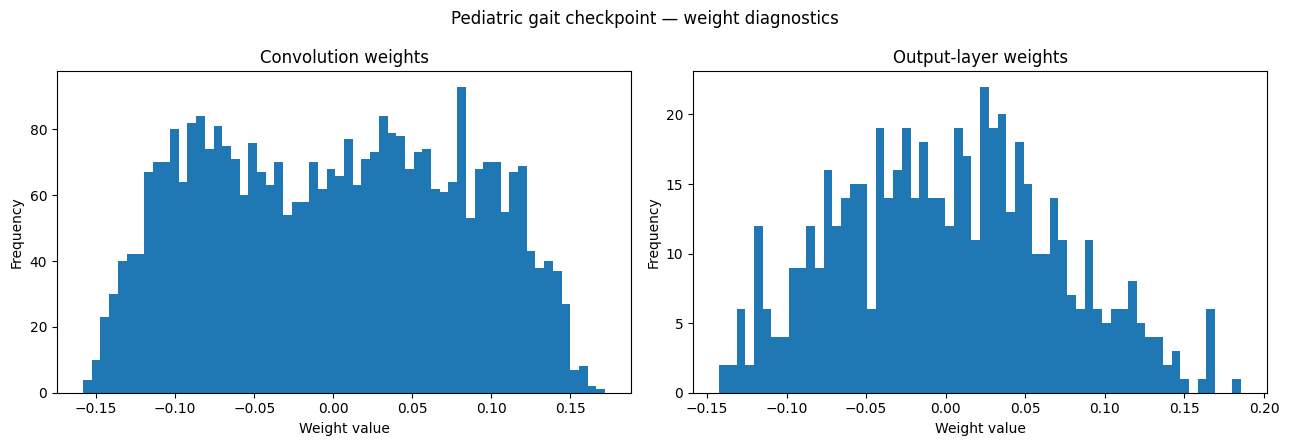

In [5]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for key, label in [
    ("conv1.weight", "Convolution weights"),
    ("fc_out.weight", "Output-layer weights"),
]:
    values = checkpoint[key].detach().cpu().numpy().ravel()
    axes[0 if key == "conv1.weight" else 1].hist(values, bins=60)
    axes[0 if key == "conv1.weight" else 1].set_title(label)
    axes[0 if key == "conv1.weight" else 1].set_xlabel("Weight value")
    axes[0 if key == "conv1.weight" else 1].set_ylabel("Frequency")

fig.suptitle("Pediatric gait checkpoint — weight diagnostics")
plt.tight_layout()
plt.savefig(OUT / "checkpoint_weight_distributions.png", dpi=180)
plt.show()

Dataset shape: (1719, 844)
Unique patients: 356
Unique trials: 22
Side distribution:


,rows
side,
RIGHT,870
LEFT,849


,metric,value
0,Rows,1719.0
1,Columns,844.0
2,Unique patients,356.0
3,Unique trial identifiers,22.0
4,Numeric columns,802.0
5,Cells missing (%),0.0


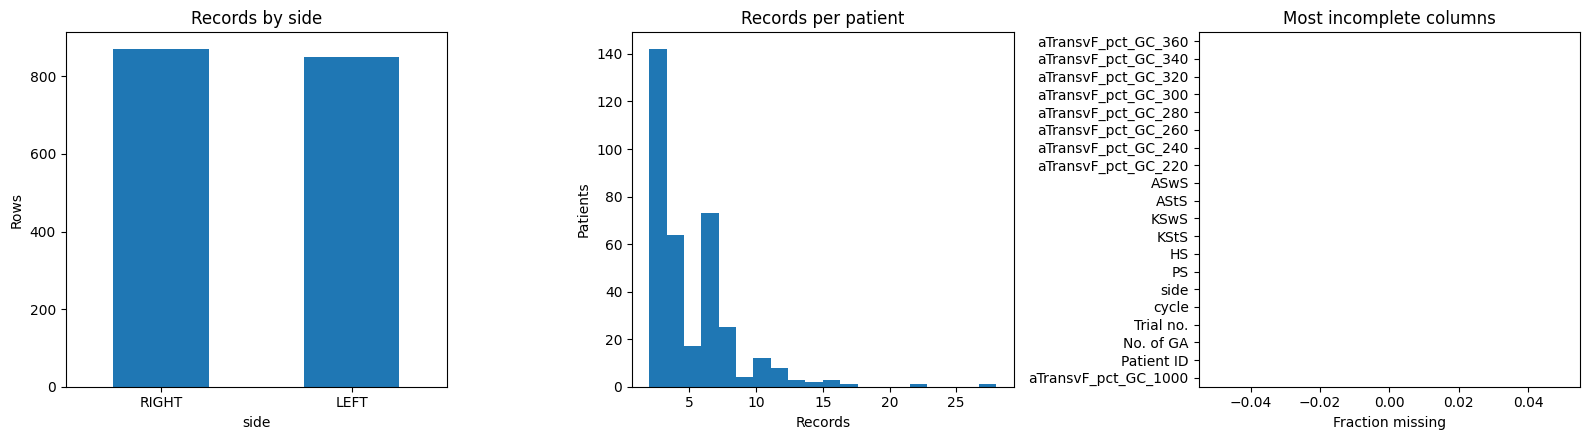

In [6]:

df = pd.read_excel(FILES["workbook"], sheet_name="ALL")

print("Dataset shape:", df.shape)
print("Unique patients:", df["Patient ID"].nunique())
print("Unique trials:", df["Trial no."].nunique())
print("Side distribution:")
display(df["side"].value_counts(dropna=False).to_frame("rows"))

numeric = df.select_dtypes(include=np.number)
missing = df.isna().mean().sort_values(ascending=False)

summary = pd.DataFrame({
    "metric": [
        "Rows", "Columns", "Unique patients",
        "Unique trial identifiers", "Numeric columns",
        "Cells missing (%)"
    ],
    "value": [
        len(df), df.shape[1], df["Patient ID"].nunique(),
        df["Trial no."].nunique(), len(numeric.columns),
        round(100 * df.isna().to_numpy().mean(), 3)
    ]
})
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df["side"].value_counts(dropna=False).plot.bar(ax=axes[0])
axes[0].set_title("Records by side")
axes[0].set_ylabel("Rows")
axes[0].tick_params(axis="x", rotation=0)

patient_counts = df.groupby("Patient ID", dropna=False).size()
axes[1].hist(patient_counts, bins=20)
axes[1].set_title("Records per patient")
axes[1].set_xlabel("Records")
axes[1].set_ylabel("Patients")

missing.head(20).sort_values().plot.barh(ax=axes[2])
axes[2].set_title("Most incomplete columns")
axes[2].set_xlabel("Fraction missing")

plt.tight_layout()
plt.savefig(OUT / "dataset_quality_dashboard.png", dpi=180)
plt.show()

summary.to_csv(OUT / "dataset_summary.csv", index=False)
missing.rename("missing_fraction").to_csv(OUT / "column_missingness.csv")

Detected gait-curve families: 13
Examples: ['aSagA_pct_GC_', 'aSagP_pct_GC_', 'avSagP_pct_GC_', 'aCorP_pct_GC_', 'aTransvP_pct_GC_', 'aSagH_pct_GC_', 'avSagH_pct_GC_', 'aCorH_pct_GC_', 'aTransvH_pct_GC_', 'aSagK_pct_GC_', 'avSagK_pct_GC_', 'avSagA_pct_GC_', 'aTransvF_pct_GC_']


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1243: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


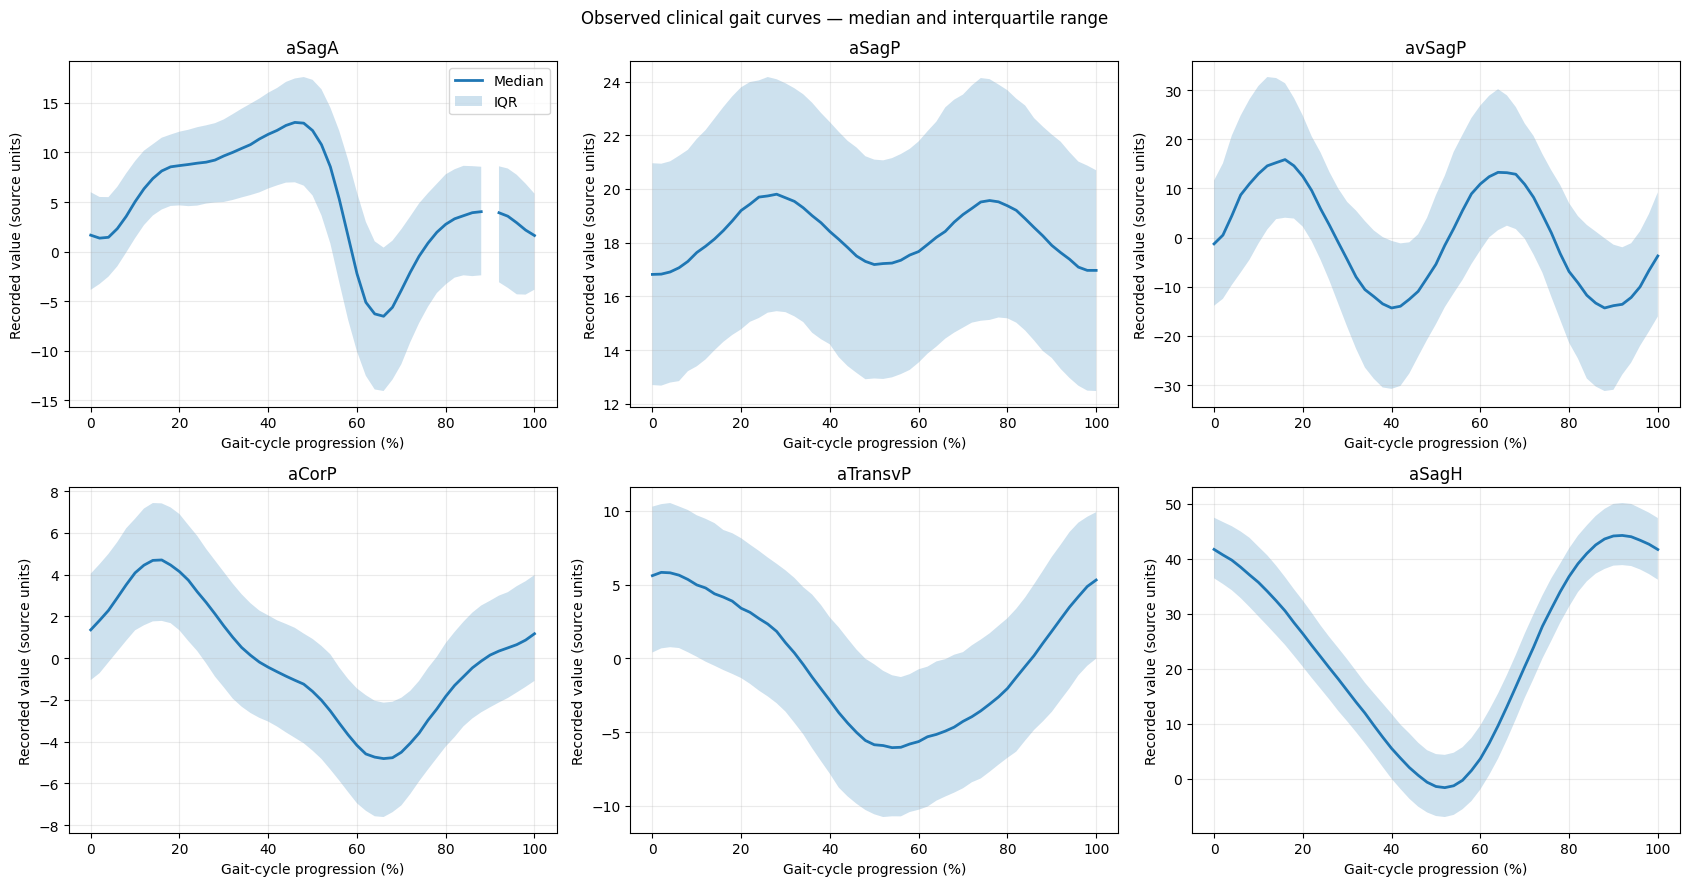

In [7]:

import re
from collections import defaultdict

curve_groups = defaultdict(list)

for col in df.columns:
    match = re.match(r"^(.*_pct_GC_)(\d+)(?:_discr)?$", str(col))
    if match:
        prefix, phase = match.groups()
        curve_groups[prefix].append((int(phase), col))

# Retain only sufficiently sampled curves.
curve_groups = {
    prefix: sorted(items)
    for prefix, items in curve_groups.items()
    if len(items) >= 10
}

print("Detected gait-curve families:", len(curve_groups))
print("Examples:", list(curve_groups)[:15])

if not curve_groups:
    raise ValueError(
        "No gait-cycle curve families matched the naming convention. "
        "Inspect df.columns for the workbook's actual curve naming."
    )

# Select up to six of the longest available curve families.
selected_groups = sorted(
    curve_groups.items(),
    key=lambda item: len(item[1]),
    reverse=True
)[:6]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.ravel()

for ax, (prefix, items) in zip(axes, selected_groups):
    phases = np.array([phase for phase, _ in items], dtype=float)
    columns = [col for _, col in items]

    values = df[columns].apply(pd.to_numeric, errors="coerce").to_numpy()
    median = np.nanmedian(values, axis=0)
    q25 = np.nanpercentile(values, 25, axis=0)
    q75 = np.nanpercentile(values, 75, axis=0)

    ax.plot(phases / 10.0, median, linewidth=2, label="Median")
    ax.fill_between(phases / 10.0, q25, q75, alpha=0.22, label="IQR")
    ax.set_title(prefix.replace("_pct_GC_", ""))
    ax.set_xlabel("Gait-cycle progression (%)")
    ax.set_ylabel("Recorded value (source units)")
    ax.grid(alpha=0.25)

for ax in axes[len(selected_groups):]:
    ax.axis("off")

axes[0].legend()
fig.suptitle("Observed clinical gait curves — median and interquartile range")
plt.tight_layout()
plt.savefig(OUT / "observed_gait_curves.png", dpi=180)
plt.show()

C3D trials: 21
dicp/DiCP1.c3d
dicp/DiCP2.c3d
dicp/DiCP3a.c3d
dicp/DiCP3b.c3d
dicp/DiCP3c.c3d
dicp/DiCP4.c3d
hecp/HeCP1.c3d
hecp/HeCP2a.c3d
hecp/HeCP2b.c3d
hecp/HeCP2c.c3d
hecp/HeCP3.c3d
hecp/HeCP4.c3d
hecp/HeCP5.c3d
td/TD1a.c3d
td/TD1b.c3d
td/TD2.c3d
td/TD3.c3d
td/TD4a.c3d
td/TD4b.c3d
td/TD4c.c3d
td/TD5.c3d


,file,group,frames,markers,point_rate_hz,analog_channels
0,DiCP1.c3d,dicp,1030,71,100.0,44
1,DiCP2.c3d,dicp,658,158,100.0,44
2,DiCP3a.c3d,dicp,740,147,100.0,28
3,DiCP3b.c3d,dicp,624,60,100.0,28
4,DiCP3c.c3d,dicp,476,46,100.0,28
5,DiCP4.c3d,dicp,612,69,100.0,44
6,HeCP1.c3d,hecp,612,73,100.0,44
7,HeCP2a.c3d,hecp,642,51,100.0,44
8,HeCP2b.c3d,hecp,560,50,100.0,44
9,HeCP2c.c3d,hecp,519,47,100.0,44


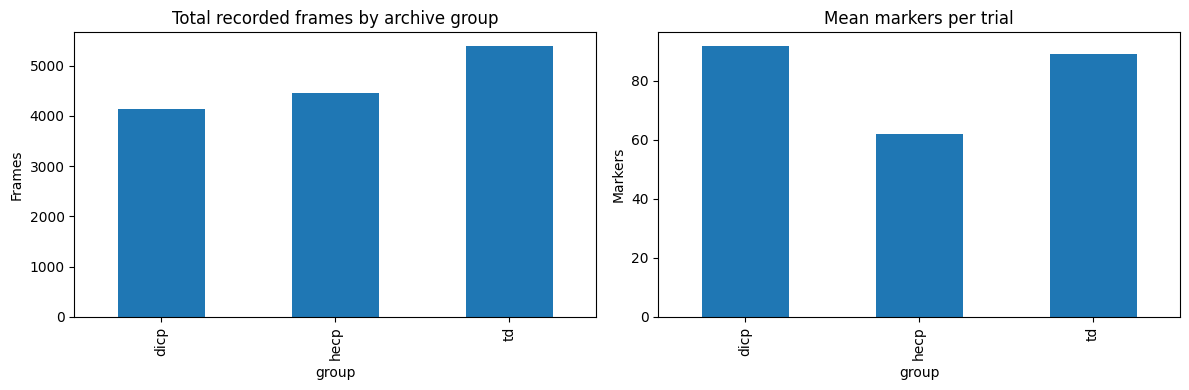

In [8]:

import ezc3d

c3d_files = sorted((EXTRACT / "cp").rglob("*.c3d"))

print("C3D trials:", len(c3d_files))
for p in c3d_files:
    print(p.relative_to(EXTRACT / "cp"))

def c3d_metadata(path):
    c = ezc3d.c3d(str(path))
    points = c["data"]["points"]
    analogs = c["data"]["analogs"]

    point_labels = c["parameters"]["POINT"]["LABELS"]["value"]
    analog_labels = c["parameters"]["ANALOG"]["LABELS"]["value"]

    return {
        "file": path.name,
        "group": path.parent.name,
        "frames": points.shape[2],
        "markers": points.shape[1],
        "point_rate_hz": float(c["parameters"]["POINT"]["RATE"]["value"][0]),
        "analog_channels": analogs.shape[1] if analogs.ndim >= 2 else 0,
        "marker_labels": point_labels,
        "analog_labels": analog_labels,
    }

trial_info = [c3d_metadata(p) for p in c3d_files]

trial_df = pd.DataFrame([
    {k: v for k, v in item.items()
     if k not in ("marker_labels", "analog_labels")}
    for item in trial_info
])

display(trial_df)
trial_df.to_csv(OUT / "c3d_trial_inventory.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
trial_df.groupby("group")["frames"].sum().plot.bar(ax=axes[0])
axes[0].set_title("Total recorded frames by archive group")
axes[0].set_ylabel("Frames")

trial_df.groupby("group")["markers"].mean().plot.bar(ax=axes[1])
axes[1].set_title("Mean markers per trial")
axes[1].set_ylabel("Markers")
plt.tight_layout()
plt.savefig(OUT / "c3d_inventory.png", dpi=180)
plt.show()

In [9]:

import plotly.graph_objects as go

# Start with a trial from the supplied archive.
# Change this to any filename printed by Cell 7.
TRIAL_NAME = "TD1a.c3d"

matches = [p for p in c3d_files if p.name == TRIAL_NAME]
if not matches:
    raise FileNotFoundError(f"Trial not found: {TRIAL_NAME}")

trial_path = matches[0]
c = ezc3d.c3d(str(trial_path))

points = c["data"]["points"]  # [x/y/z/residual, marker, frame]
labels = list(c["parameters"]["POINT"]["LABELS"]["value"])
xyz = points[:3].astype(float)

# Drop markers that have no valid observations.
valid_marker = np.isfinite(xyz).all(axis=(0, 2))
xyz = xyz[:, valid_marker, :]
labels = [label for label, keep in zip(labels, valid_marker) if keep]

# Center the coordinates for a stable viewing window.
xyz = xyz - np.nanmedian(xyz, axis=(1, 2), keepdims=True)

# C3D coordinates are commonly stored in mm, but inspect scale first.
if np.nanpercentile(np.abs(xyz), 95) > 10:
    xyz = xyz / 1000.0
unit_label = "m (centered; inferred scale)" if np.nanpercentile(np.abs(xyz), 95) < 10 else "source units"

n_frames = xyz.shape[2]
frame_ids = np.unique(
    np.linspace(0, n_frames - 1, min(70, n_frames)).astype(int)
)

# Stable plot bounds across the animation.
lim = float(np.nanpercentile(np.abs(xyz), 99))
lim = max(lim, 0.1)

def marker_trace(frame_idx):
    p = xyz[:, :, frame_idx]
    return go.Scatter3d(
        x=p[0], y=p[1], z=p[2],
        mode="markers+text",
        text=labels,
        textposition="top center",
        textfont=dict(size=8),
        marker=dict(size=4, color=p[2], colorscale="Turbo",
                    showscale=True, colorbar=dict(title="Z")),
        hovertemplate="%{text}<br>X=%{x:.3f}<br>Y=%{y:.3f}<br>Z=%{z:.3f}<extra></extra>",
        name="Measured markers"
    )

fig = go.Figure(
    data=[marker_trace(frame_ids[0])],
    frames=[
        go.Frame(
            data=[marker_trace(int(f))],
            name=str(int(f))
        )
        for f in frame_ids
    ]
)

fig.update_layout(
    title=f"Motion-capture digital twin prototype — {trial_path.name}",
    template="plotly_dark",
    scene=dict(
        xaxis_title=f"X ({unit_label})",
        yaxis_title=f"Y ({unit_label})",
        zaxis_title=f"Z ({unit_label})",
        aspectmode="data",
        xaxis=dict(range=[-lim, lim]),
        yaxis=dict(range=[-lim, lim]),
        zaxis=dict(range=[-lim, lim]),
    ),
    height=750,
    margin=dict(l=0, r=0, t=60, b=0),
    updatemenus=[dict(
        type="buttons",
        showactive=False,
        x=0.05, y=1.08,
        buttons=[
            dict(label="Play", method="animate",
                 args=[None, {"frame": {"duration": 70, "redraw": True},
                              "fromcurrent": True}]),
            dict(label="Pause", method="animate",
                 args=[[None], {"frame": {"duration": 0, "redraw": False},
                                "mode": "immediate"}])
        ]
    )],
    sliders=[dict(
        steps=[
            dict(method="animate", args=[[str(int(f))],
                 {"mode": "immediate",
                  "frame": {"duration": 0, "redraw": True}}],
                 label=str(i))
            for i, f in enumerate(frame_ids)
        ],
        currentvalue=dict(prefix="Animation frame: ")
    )]
)

html_path = OUT / f"digital_twin_{trial_path.stem}.html"
fig.write_html(str(html_path), include_plotlyjs=True)
fig.show()

print("Interactive animation saved:", html_path)

Interactive animation saved: /content/drive/MyDrive/Pediatric_GaitProject/review_outputs/digital_twin_TD1a.html


,output_channel,weight_L2_norm,weight_mean,weight_std,bias
0,Output 0,0.541270,0.000899,0.067653,0.083152
1,Output 1,0.438716,0.014964,0.052759,-0.005721
2,Output 2,0.883563,0.034324,0.104976,0.105686
3,Output 3,0.516594,-0.001650,0.064553,-0.073227
4,Output 4,0.522487,-0.002910,0.065246,-0.057788
5,Output 5,0.412951,-0.001400,0.051600,-0.096174
6,Output 6,0.500709,-0.009470,0.061868,-0.076888
7,Output 7,0.455599,-0.012449,0.055572,0.016238
8,Output 8,0.491944,-0.005083,0.061283,-0.094438


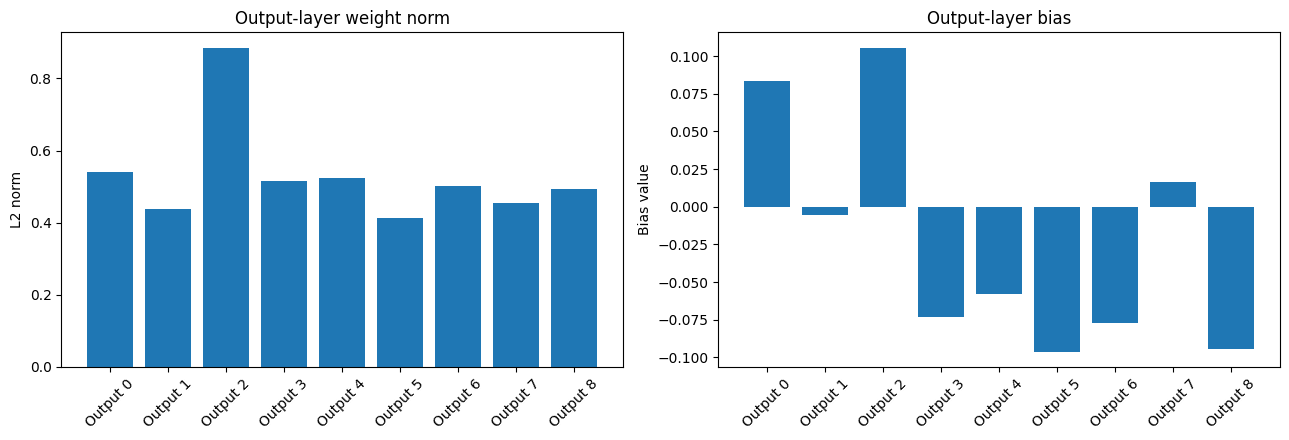

In [10]:

out_w = checkpoint["fc_out.weight"].detach().cpu().numpy()
out_b = checkpoint["fc_out.bias"].detach().cpu().numpy()

channel_df = pd.DataFrame({
    "output_channel": [f"Output {i}" for i in range(out_w.shape[0])],
    "weight_L2_norm": np.linalg.norm(out_w, axis=1),
    "weight_mean": out_w.mean(axis=1),
    "weight_std": out_w.std(axis=1),
    "bias": out_b,
})

display(channel_df)
channel_df.to_csv(OUT / "output_channel_diagnostics.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(channel_df["output_channel"], channel_df["weight_L2_norm"])
axes[0].set_title("Output-layer weight norm")
axes[0].set_ylabel("L2 norm")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(channel_df["output_channel"], channel_df["bias"])
axes[1].set_title("Output-layer bias")
axes[1].set_ylabel("Bias value")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(OUT / "output_channel_diagnostics.png", dpi=180)
plt.show()

,item,available,explanation
0,Checkpoint loads,True,Verified against supplied architecture
1,Input scaler available,False,Not supplied
2,Input feature mapping verified,False,18 channels are not documented
3,Output channel meanings verified,False,Nine output labels are not documented
4,Paired external ground truth available,False,Mapping to checkpoint targets unverified
5,Predictive MAE / RMSE / R2,False,Requires aligned predictions and targets
6,Actual C3D marker visualization,True,Measured coordinates from selected trial
7,Clinical gait-curve analysis,True,Observed curves from supplied workbook


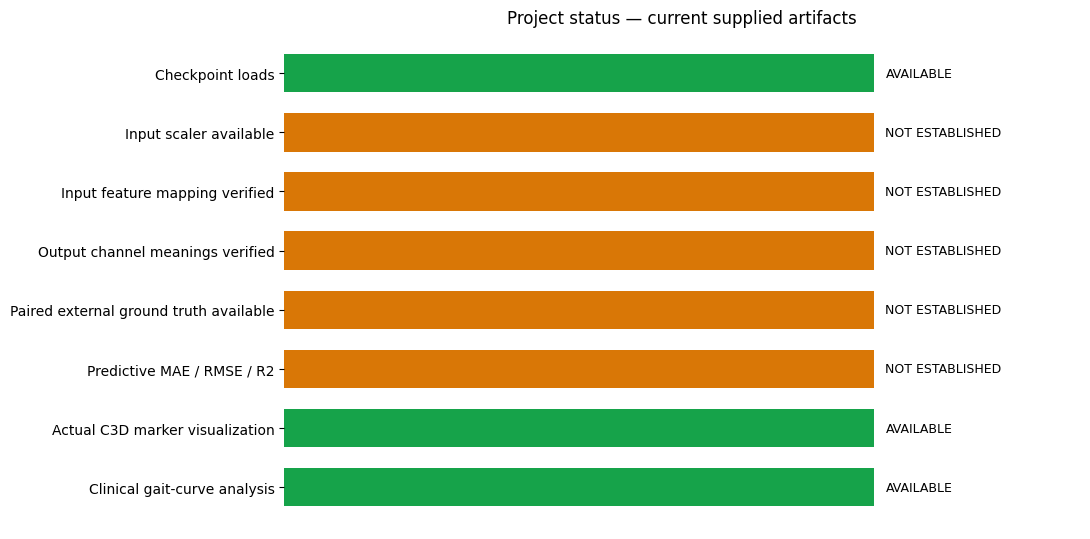

In [11]:

readiness = pd.DataFrame([
    ("Checkpoint loads", True, "Verified against supplied architecture"),
    ("Input scaler available", False, "Not supplied"),
    ("Input feature mapping verified", False, "18 channels are not documented"),
    ("Output channel meanings verified", False, "Nine output labels are not documented"),
    ("Paired external ground truth available", False, "Mapping to checkpoint targets unverified"),
    ("Predictive MAE / RMSE / R2", False, "Requires aligned predictions and targets"),
    ("Actual C3D marker visualization", True, "Measured coordinates from selected trial"),
    ("Clinical gait-curve analysis", True, "Observed curves from supplied workbook"),
], columns=["item", "available", "explanation"])

display(readiness)
readiness.to_csv(OUT / "project_readiness.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = readiness["available"].map({True: "#16a34a", False: "#d97706"})
y = np.arange(len(readiness))

ax.barh(y, np.ones(len(readiness)), color=colors, height=0.65)
ax.set_yticks(y)
ax.set_yticklabels(readiness["item"])
ax.invert_yaxis()
ax.set_xlim(0, 1.35)
ax.set_xticks([])
ax.set_title("Project status — current supplied artifacts")

for i, row in readiness.iterrows():
    status = "AVAILABLE" if row["available"] else "NOT ESTABLISHED"
    ax.text(1.02, i, status, va="center", fontsize=9)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig(OUT / "project_readiness_dashboard.png", dpi=180)
plt.show()

In [12]:

import shutil

# Save the environment and artifact manifest.
manifest = {
    "project": "Pediatric Gait Digital Twin Demonstration",
    "checkpoint": FILES["checkpoint"].name,
    "clinical_workbook": FILES["workbook"].name,
    "device": str(device),
    "parameter_count": int(n_params),
    "c3d_trial_count": int(len(c3d_files)),
    "workbook_rows": int(len(df)),
    "workbook_columns": int(df.shape[1]),
    "predictive_accuracy_metrics": None,
    "accuracy_note": (
        "Not computed: preprocessing, input/target channel mapping, "
        "and paired external ground truth are not established."
    ),
}

with open(OUT / "project_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

zip_path = shutil.make_archive(
    str(ROOT / "Pediatric_Gait_Review_Package"),
    "zip",
    root_dir=OUT
)

print("Review package created:", zip_path)
print("\nFiles included:")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(f"{p.name:45s} {p.stat().st_size / 1024:.1f} KiB")

Review package created: /content/drive/MyDrive/Pediatric_GaitProject/Pediatric_Gait_Review_Package.zip

Files included:
c3d_channel_audit.csv                         16.0 KiB
c3d_inventory.png                             48.0 KiB
c3d_trial_inventory.csv                       0.7 KiB
candidate_biomechanical_variables.csv         12.7 KiB
candidate_training_columns.csv                2920.9 KiB
candidate_training_files.csv                  48.8 KiB
checkpoint_input_mapping_template.csv         1.6 KiB
checkpoint_output_mapping_template.csv        0.7 KiB
checkpoint_parameter_inventory.csv            1.4 KiB
checkpoint_provenance_audit.json              0.5 KiB
checkpoint_weight_diagnostics.csv             3.0 KiB
checkpoint_weight_distributions.png           53.4 KiB
column_missingness.csv                        17.1 KiB
dataset_quality_dashboard.png                 126.7 KiB
dataset_summary.csv                           0.1 KiB
digital_twin_TD1a.html                        5006.1 KiB
fo

In [13]:

import json
from pathlib import Path

NOTEBOOK_PATH = INP / "pedigaitdt.ipynb"

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    keywords = [
        "StandardScaler", "kinematics", "kinetics",
        "synthetic", "torch.save", "load_state_dict",
        "TARGET_FEATURE_DIM", "InverseDynamicsPhysicsLoss"
    ]

    if any(k.lower() in source.lower() for k in keywords):
        print(f"\n{'='*24} CELL {i} {'='*24}")
        print(source[:6000])

        # Print any recorded output for comparison with source code.
        for output in cell.get("outputs", []):
            if output.get("output_type") == "stream":
                print("RECORDED OUTPUT:")
                print("".join(output.get("text", []))[:2000])


======================== CELL 4 ========================
import os
import sys
import subprocess

# Auto-install openpyxl if missing
try:
    import openpyxl
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "openpyxl"])

import glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.preprocessing import StandardScaler
import pyvista as pv
import imageio
from xvfbwrapper import Xvfb

# =========================================================================
# 1. GLOBAL ENVIRONMENT & HEADLESS SETUP
# =========================================================================
print("[INFO] Initializing Global Environment & Headless 3D Engine...")

try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
except Exception:
    pass

vdispla

In [14]:

import os

artifact_extensions = (".pkl", ".pickle", ".joblib", ".json", ".npz", ".pt", ".pth")

found = []
for root, dirs, files in os.walk(ROOT):
    # Avoid traversing extracted raw data and bulky caches.
    dirs[:] = [
        d for d in dirs
        if d not in {".ipynb_checkpoints", "__pycache__"}
    ]

    for name in files:
        lower = name.lower()
        if any(lower.endswith(ext) for ext in artifact_extensions):
            found.append(os.path.join(root, name))

print("Potential model/preprocessing artifacts:")
for item in found:
    print(item)

if not found:
    print("No candidate preprocessing artifacts found under project root.")

Potential model/preprocessing artifacts:
/content/drive/MyDrive/Pediatric_GaitProject/input/best_pediatric_pinn.pth
/content/drive/MyDrive/Pediatric_GaitProject/outputs/initial_data_audit.json
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/project_manifest.json
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/inference_diagnostics.json
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/checkpoint_provenance_audit.json
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/project_validation_status.json
/content/drive/MyDrive/Pediatric_GaitProject/results/kwsw_temporal_cnn_pilot.pth
/content/drive/MyDrive/Pediatric_GaitProject/results/skeletal_twin_model.json


In [15]:

import pandas as pd
import numpy as np

xlsx_path = FILES["workbook"]
book = pd.ExcelFile(xlsx_path)

print("Workbook sheets:", book.sheet_names)

for sheet in book.sheet_names:
    preview = pd.read_excel(xlsx_path, sheet_name=sheet, nrows=3)
    print(f"\n{sheet}: {preview.shape[1]} columns")
    print(preview.columns[:25].tolist())

dictionary = pd.read_excel(xlsx_path, sheet_name="Dictionary")
print("\nDictionary columns:")
print(dictionary.columns.tolist())
display(dictionary.head(40))

# Search descriptions and variable names for biomechanical terms.
dict_text = dictionary.astype(str).agg(" | ".join, axis=1)
pattern = r"moment|torque|kinetic|joint|hip|knee|ankle|power|angle"

candidates = dictionary.loc[
    dict_text.str.contains(pattern, case=False, na=False)
]
display(candidates.head(100))

candidates.to_csv(OUT / "candidate_biomechanical_variables.csv", index=False)

Workbook sheets: ['Fold1', 'Fold2', 'Fold3', 'Fold4', 'Fold5', 'Fold6', 'Fold7', 'Fold8', 'Fold9', 'Fold10', 'ALL', 'Dictionary']

Fold1: 844 columns
['Patient ID', 'No. of GA', 'Trial no.', 'cycle', 'side', 'PS', 'HS', 'KStS', 'KSwS', 'AStS', 'ASwS', 'PC', 'HC', 'PT', 'HT', 'FT', 'SRA_discr', 'aMaxStSagA_discr', 'aIc2SagA_discr', 'aSagA_pct_GC_900_discr', 'aBelow1SDSwSagApct_discr', 'aAbove1SDSwSagApct_discr', 'aIcSagK_discr', 'pctaMaxMStSagK_discr', 'aMinStSagK_discr']

Fold2: 844 columns
['Patient ID', 'No. of GA', 'Trial no.', 'cycle', 'side', 'PS', 'HS', 'KStS', 'KSwS', 'AStS', 'ASwS', 'PC', 'HC', 'PT', 'HT', 'FT', 'SRA_discr', 'aMaxStSagA_discr', 'aIc2SagA_discr', 'aSagA_pct_GC_900_discr', 'aBelow1SDSwSagApct_discr', 'aAbove1SDSwSagApct_discr', 'aIcSagK_discr', 'pctaMaxMStSagK_discr', 'aMinStSagK_discr']

Fold3: 844 columns
['Patient ID', 'No. of GA', 'Trial no.', 'cycle', 'side', 'PS', 'HS', 'KStS', 'KSwS', 'AStS', 'ASwS', 'PC', 'HC', 'PT', 'HT', 'FT', 'SRA_discr', 'aMaxStSagA_d

,Variable code name,Explanation
0,Patient ID,anonymized patient ID
1,No. of GA,number of gait analysis sessions
2,Trial no.,number of walking trial
3,cycle,recorded step
4,side,left or right side
5,PS,classification for the movement of the pelvis ...
6,HS,classification for the movement of the hip in ...
7,KStS,classification for the movement of the knee du...
8,KSwS,classification for the movement of the knee du...
9,AStS,classification for the movement of the ankle d...


,Variable code name,Explanation
6,HS,classification for the movement of the hip in ...
7,KStS,classification for the movement of the knee du...
8,KSwS,classification for the movement of the knee du...
9,AStS,classification for the movement of the ankle d...
10,ASwS,classification for the movement of the ankle d...
...,...,...
113,aAbove1SDTransHpct,hip angle above the +1SD for 75% in the transv...
114,aBelow1SDTransH,hip angle below the -1SD for 75% in transverse...
115,aBelow1SDTransHpct,hip angle below the -1SD for 75% in transverse...
116,aIcSagK_cont,knee angle at initial contact in the sagittal ...


In [16]:

from pathlib import Path
import zipfile

for archive_key in ("maastricht", "cp"):
    archive_path = FILES[archive_key]
    print(f"\n{archive_key.upper()} ARCHIVE")

    with zipfile.ZipFile(archive_path) as z:
        names = z.namelist()
        print("File count:", len(names))

        extensions = {}
        for name in names:
            ext = Path(name).suffix.lower() or "[no extension]"
            extensions[ext] = extensions.get(ext, 0) + 1

        print("File types:", extensions)

        for name in names[:50]:
            print(name)


MAASTRICHT ARCHIVE
File count: 24
File types: {'[no extension]': 1, '.xlsx': 7, '.png': 3, '.jpg': 12, '.docx': 1}
children gait/
children gait/01_Demo_PhysEx.xlsx
children gait/02_Overview_comf.xlsx
children gait/03_Overview_fast.xlsx
children gait/04_Overview_slow.xlsx
children gait/05_AgeGroups_comf.xlsx
children gait/06_AgeGroups_fast.xlsx
children gait/07_AgeGroups_slow.xlsx
children gait/08_Table_SPT_comf.PNG
children gait/09_Fig_JointAngles_comf.JPG
children gait/10_Fig_GRF_comf.JPG
children gait/11_Fig_JointMoments_comf.JPG
children gait/12_Fig_JointPower_comf.JPG
children gait/13_Table_SPT_fast.PNG
children gait/14_Fig_JointAngles_fast.JPG
children gait/15_Fig_GRF_fast.JPG
children gait/16_Fig_JointMoment_fast.JPG
children gait/17_Fig_JointPower_fast.JPG
children gait/18_Table_SPT_slow.PNG
children gait/19_Fig_JointAngles_slow.JPG
children gait/20_Fig_GRF_slow.JPG
children gait/21_Fig_JointMoments_slow.JPG
children gait/22_Fig_JointPower_slow.JPG
children gait/26_Description_

In [17]:

import time
import numpy as np
import torch

model.eval()

batch_size = 1
x_test = torch.zeros(batch_size, 100, 18, device=device)
a_test = torch.zeros(batch_size, 2, device=device)

# Warm-up
with torch.inference_mode():
    for _ in range(10):
        _ = model(x_test, a_test)

if device.type == "cuda":
    torch.cuda.synchronize()

times = []
with torch.inference_mode():
    for _ in range(100):
        start = time.perf_counter()
        pred = model(x_test, a_test)

        if device.type == "cuda":
            torch.cuda.synchronize()

        times.append((time.perf_counter() - start) * 1000)

pred_np = pred.detach().cpu().numpy()

latency_report = {
    "device": str(device),
    "batch_size": batch_size,
    "sequence_length": 100,
    "input_channels": 18,
    "output_channels": 9,
    "median_latency_ms": float(np.median(times)),
    "p95_latency_ms": float(np.percentile(times, 95)),
    "outputs_finite": bool(np.isfinite(pred_np).all()),
    "output_min": float(pred_np.min()),
    "output_max": float(pred_np.max()),
    "output_std": float(pred_np.std()),
    "test_input_type": "all-zero synthetic software test",
}

print(pd.Series(latency_report))
with open(OUT / "inference_diagnostics.json", "w") as f:
    json.dump(latency_report, f, indent=2)

device                                           cuda
batch_size                                          1
sequence_length                                   100
input_channels                                     18
output_channels                                     9
median_latency_ms                            1.784455
p95_latency_ms                               1.868547
outputs_finite                                   True
output_min                                  -0.114155
output_max                                  57.302479
output_std                                  17.673244
test_input_type      all-zero synthetic software test
dtype: object


In [18]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_paired_predictions(y_true, y_pred, channel_names=None):
    """
    Evaluate aligned arrays of shape [trials, time, channels]
    or [samples, channels].

    Call only when the target mapping, units, and preprocessing
    have been verified.
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            f"Shape mismatch: targets {y_true.shape}, predictions {y_pred.shape}"
        )

    if y_true.ndim < 2:
        raise ValueError("Expected samples/time and channel dimensions.")

    if not np.isfinite(y_true).all() or not np.isfinite(y_pred).all():
        raise ValueError("Arrays contain NaN or infinite values.")

    n_channels = y_true.shape[-1]

    if channel_names is None:
        channel_names = [f"Channel {i+1}" for i in range(n_channels)]

    if len(channel_names) != n_channels:
        raise ValueError("Number of channel names does not match array shape.")

    yt = y_true.reshape(-1, n_channels)
    yp = y_pred.reshape(-1, n_channels)

    rows = []
    for i, name in enumerate(channel_names):
        rows.append({
            "channel": name,
            "MAE": mean_absolute_error(yt[:, i], yp[:, i]),
            "RMSE": np.sqrt(mean_squared_error(yt[:, i], yp[:, i])),
            "R2": r2_score(yt[:, i], yp[:, i])
                if len(yt) >= 2 and np.var(yt[:, i]) > 0 else np.nan,
        })

    result = pd.DataFrame(rows)
    display(result)
    return result

# Intentionally do not call the function yet.
# First establish valid paired ground truth and checkpoint-compatible inputs.
print("Metric function ready. No predictive metrics have been fabricated.")

Metric function ready. No predictive metrics have been fabricated.


In [19]:

from pathlib import Path
import hashlib

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
INP = ROOT / "input"
OUT = ROOT / "review_outputs"
EXTRACT = ROOT / "extracted"

OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    "checkpoint": INP / "best_pediatric_pinn.pth",
    "workbook": INP / "Stratifiedfoldkinematicparametersandcurves.xlsx",
    "maastricht": INP / "children gait.zip",
    "cp": INP / "CP child gait data.zip",
    "notebook": INP / "pedigaitdt.ipynb",
}

print("PROJECT ROOT:", ROOT)
assert ROOT.exists(), f"Project directory not found: {ROOT}"

for name, path in FILES.items():
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"{name:12s} | {status:7s} | {path}")

missing = [str(p) for p in FILES.values() if not p.is_file()]
if missing:
    raise FileNotFoundError(
        "Please correct these file paths before proceeding:\n" +
        "\n".join(missing)
    )

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

print("\nCheckpoint SHA-256:")
print(sha256(FILES["checkpoint"]))

PROJECT ROOT: /content/drive/MyDrive/Pediatric_GaitProject
checkpoint   | FOUND   | /content/drive/MyDrive/Pediatric_GaitProject/input/best_pediatric_pinn.pth
workbook     | FOUND   | /content/drive/MyDrive/Pediatric_GaitProject/input/Stratifiedfoldkinematicparametersandcurves.xlsx
maastricht   | FOUND   | /content/drive/MyDrive/Pediatric_GaitProject/input/children gait.zip
cp           | FOUND   | /content/drive/MyDrive/Pediatric_GaitProject/input/CP child gait data.zip
notebook     | FOUND   | /content/drive/MyDrive/Pediatric_GaitProject/input/pedigaitdt.ipynb

Checkpoint SHA-256:
a1eaad2410a15e83b2bcb8aeee38d3000c81f4b7358fae73b4f7bab2ef6ee763


In [20]:

import pandas as pd
import re

xls = pd.ExcelFile(FILES["workbook"])

sheet_rows = []
for sheet in xls.sheet_names:
    preview = pd.read_excel(
        FILES["workbook"], sheet_name=sheet, nrows=5
    )
    sheet_rows.append({
        "sheet": sheet,
        "column_count": len(preview.columns),
        "columns": " | ".join(map(str, preview.columns[:35])),
    })

sheet_inventory = pd.DataFrame(sheet_rows)
display(sheet_inventory)

sheet_inventory.to_csv(
    OUT / "workbook_sheet_inventory.csv", index=False
)

if "Dictionary" in xls.sheet_names:
    dictionary = pd.read_excel(
        FILES["workbook"], sheet_name="Dictionary"
    )

    print("\nDictionary columns:", dictionary.columns.tolist())
    display(dictionary.head(30))

    text_columns = dictionary.select_dtypes(
        include=["object", "string"]
    )

    keywords = (
        r"moment|torque|kinetic|kinematic|joint|hip|knee|ankle|"
        r"angle|power|mass|height"
    )

    mask = pd.Series(False, index=dictionary.index)
    for col in text_columns:
        mask |= dictionary[col].astype(str).str.contains(
            keywords, case=False, na=False, regex=True
        )

    print("\nPotentially relevant variable definitions:")
    display(dictionary.loc[mask].head(100))

    dictionary.to_csv(
        OUT / "workbook_dictionary.csv", index=False
    )
else:
    print(
        "No exact 'Dictionary' sheet found. "
        "Use the inventory above to identify the correct sheet."
    )

,sheet,column_count,columns
0,Fold1,844,Patient ID | No. of GA | Trial no. | cycle | s...
1,Fold2,844,Patient ID | No. of GA | Trial no. | cycle | s...
2,Fold3,844,Patient ID | No. of GA | Trial no. | cycle | s...
3,Fold4,844,Patient ID | No. of GA | Trial no. | cycle | s...
4,Fold5,844,Patient ID | No. of GA | Trial no. | cycle | s...
5,Fold6,844,Patient ID | No. of GA | Trial no. | cycle | s...
6,Fold7,844,Patient ID | No. of GA | Trial no. | cycle | s...
7,Fold8,844,Patient ID | No. of GA | Trial no. | cycle | s...
8,Fold9,844,Patient ID | No. of GA | Trial no. | cycle | s...
9,Fold10,844,Patient ID | No. of GA | Trial no. | cycle | s...



Dictionary columns: ['Variable code name', 'Explanation']


,Variable code name,Explanation
0,Patient ID,anonymized patient ID
1,No. of GA,number of gait analysis sessions
2,Trial no.,number of walking trial
3,cycle,recorded step
4,side,left or right side
5,PS,classification for the movement of the pelvis ...
6,HS,classification for the movement of the hip in ...
7,KStS,classification for the movement of the knee du...
8,KSwS,classification for the movement of the knee du...
9,AStS,classification for the movement of the ankle d...



Potentially relevant variable definitions:


,Variable code name,Explanation
6,HS,classification for the movement of the hip in ...
7,KStS,classification for the movement of the knee du...
8,KSwS,classification for the movement of the knee du...
9,AStS,classification for the movement of the ankle d...
10,ASwS,classification for the movement of the ankle d...
...,...,...
113,aAbove1SDTransHpct,hip angle above the +1SD for 75% in the transv...
114,aBelow1SDTransH,hip angle below the -1SD for 75% in transverse...
115,aBelow1SDTransHpct,hip angle below the -1SD for 75% in transverse...
116,aIcSagK_cont,knee angle at initial contact in the sagittal ...


In [21]:

import ezc3d
import numpy as np

c3d_paths = sorted((EXTRACT / "cp").rglob("*.c3d"))

if not c3d_paths:
    raise FileNotFoundError(
        f"No extracted C3D trials found under {EXTRACT / 'cp'}. "
        "Check where you extracted CP child gait data.zip."
    )

rows = []

for path in c3d_paths:
    try:
        c = ezc3d.c3d(str(path))

        point_labels = list(
            c["parameters"]["POINT"]["LABELS"]["value"]
        )
        analog_labels = list(
            c["parameters"]["ANALOG"]["LABELS"]["value"]
        )

        point_data = c["data"]["points"]
        analog_data = c["data"]["analogs"]

        keywords = (
            "force", "fp", "cop", "moment", "grf", "plate"
        )
        candidates = [
            label for label in analog_labels
            if any(k in label.lower() for k in keywords)
        ]

        rows.append({
            "trial": path.name,
            "group": path.parent.name,
            "frames": point_data.shape[2],
            "point_rate_hz": float(
                c["parameters"]["POINT"]["RATE"]["value"][0]
            ),
            "marker_count": len(point_labels),
            "marker_labels": ", ".join(point_labels),
            "analog_channel_count": len(analog_labels),
            "analog_labels": ", ".join(analog_labels),
            "kinetic_candidates": ", ".join(candidates),
            "analog_data_nonempty": bool(analog_data.size),
        })

    except Exception as e:
        rows.append({
            "trial": path.name,
            "group": path.parent.name,
            "error": str(e),
        })

c3d_audit = pd.DataFrame(rows)
display(c3d_audit)

c3d_audit.to_csv(
    OUT / "c3d_channel_audit.csv", index=False
)

print("\nForce-plate parameter groups:")
for path in c3d_paths:
    try:
        c = ezc3d.c3d(str(path))
        fp = c["parameters"].get("FORCE_PLATFORM", {})
        if fp:
            print(path.name, {
                k: v.get("value")
                for k, v in fp.items()
                if k in ("USED", "TYPE", "CHANNEL", "CORNERS", "ORIGIN")
            })
    except Exception:
        pass

,trial,group,frames,point_rate_hz,marker_count,marker_labels,analog_channel_count,analog_labels,kinetic_candidates,analog_data_nonempty
0,DiCP1.c3d,dicp,1030,100.0,71,"*1, *2, *3, *4, RSHO, *6, *7, *8, *9, LSHO, C7...",44,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True
1,DiCP2.c3d,dicp,658,100.0,158,"*1, RASI, *3, *4, LTOE, *6, *7, *8, *9, *10, *...",44,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True
2,DiCP3a.c3d,dicp,740,100.0,147,"*1, *2, *3, *4, *5, *6, *7, *8, *9, *10, *11, ...",28,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True
3,DiCP3b.c3d,dicp,624,100.0,60,"LSHO, *2, RFHD, CLAV, RSHO, *6, *7, LELB, *9, ...",28,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True
4,DiCP3c.c3d,dicp,476,100.0,46,"RWRA, RFIN, RASI, STRN, RELB, RTHI, LFIN, CLAV...",28,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True
5,DiCP4.c3d,dicp,612,100.0,69,"RSHO, LBAK, T10, LELB, RELB, *6, *7, *8, *9, *...",44,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True
6,HeCP1.c3d,hecp,612,100.0,73,"*1, *2, *3, RFIN, *5, *6, *7, *8, LSHO, RELB, ...",44,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True
7,HeCP2a.c3d,hecp,642,100.0,51,"RSHO, LSHO, C7, LBAK, RFIN, RWRA, *7, *8, *9, ...",44,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True
8,HeCP2b.c3d,hecp,560,100.0,50,"STRN, CLAV, LSHO, LBAK, LELB, RSHO, C7, RELB, ...",44,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True
9,HeCP2c.c3d,hecp,519,100.0,47,"STRN, T10, LELB, RSHO, RFHD, *6, LBHD, RBHD, R...",44,"FX1, FY1, FZ1, MX1, MY1, MZ1, FX2, FY2, FZ2, M...",,True



Force-plate parameter groups:
DiCP1.c3d {'USED': array([2]), 'TYPE': array([2, 2]), 'CORNERS': array([[[   0., -647.],
        [ 464., -183.],
        [ 464., -183.],
        [   0., -647.]],

       [[ 508.,  508.],
        [ 508.,  508.],
        [   0.,    0.],
        [   0.,    0.]],

       [[   0.,    0.],
        [   0.,    0.],
        [   0.,    0.],
        [   0.,    0.]]]), 'ORIGIN': array([[ 0.        ,  0.29300001],
       [-0.09      , -0.05      ],
       [38.        , 42.74599838]]), 'CHANNEL': array([[ 1,  7],
       [ 2,  8],
       [ 3,  9],
       [ 4, 10],
       [ 5, 11],
       [ 6, 12]])}
DiCP2.c3d {'USED': array([2]), 'TYPE': array([2, 2]), 'CORNERS': array([[[   0., -647.],
        [ 464., -183.],
        [ 464., -183.],
        [   0., -647.]],

       [[ 508.,  508.],
        [ 508.,  508.],
        [   0.,    0.],
        [   0.,    0.]],

       [[   0.,    0.],
        [   0.,    0.],
        [   0.,    0.],
        [   0.,    0.]]]), 'ORIGIN': array([

In [22]:

import ezc3d
import numpy as np
import pandas as pd

audit_rows = []

for path in c3d_paths:
    try:
        c = ezc3d.c3d(str(path))
        params = c["parameters"]
        labels = list(params["ANALOG"]["LABELS"]["value"])
        analog = np.asarray(c["data"]["analogs"])

        # Typical ezc3d shape: subframes x channels x point frames.
        # Report the actual shape rather than assuming the layout.
        analog_rate = params["ANALOG"].get("RATE", {}).get("value", [None])
        point_rate = params["POINT"]["RATE"]["value"][0]

        row = {
            "trial": path.name,
            "group": path.parent.name,
            "analog_shape": str(analog.shape),
            "analog_rate_hz": float(analog_rate[0])
                if analog_rate and analog_rate[0] is not None else np.nan,
            "point_rate_hz": float(point_rate),
            "channel_count": len(labels),
            "finite_fraction": float(np.isfinite(analog).mean())
                if analog.size else np.nan,
        }

        for prefix in ["FX", "FY", "FZ", "MX", "MY", "MZ"]:
            matches = [
                label for label in labels
                if label.upper().startswith(prefix)
            ]
            row[prefix + "_channels"] = ", ".join(matches)

        fp = params.get("FORCE_PLATFORM", {})
        row["force_platforms_used"] = int(
            np.asarray(fp.get("USED", {}).get("value", [0])).ravel()[0]
        ) if fp else 0

        audit_rows.append(row)

    except Exception as e:
        audit_rows.append({"trial": path.name, "error": str(e)})

force_audit = pd.DataFrame(audit_rows)
display(force_audit)

force_audit.to_csv(
    OUT / "force_signal_inventory.csv", index=False
)

print("Saved:", OUT / "force_signal_inventory.csv")

,trial,group,analog_shape,analog_rate_hz,point_rate_hz,channel_count,finite_fraction,FX_channels,FY_channels,FZ_channels,MX_channels,MY_channels,MZ_channels,force_platforms_used
0,DiCP1.c3d,dicp,"(1, 44, 15450)",1500.0,100.0,44,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2
1,DiCP2.c3d,dicp,"(1, 44, 9870)",1500.0,100.0,44,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2
2,DiCP3a.c3d,dicp,"(1, 28, 11100)",1500.0,100.0,28,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2
3,DiCP3b.c3d,dicp,"(1, 28, 9360)",1500.0,100.0,28,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2
4,DiCP3c.c3d,dicp,"(1, 28, 7140)",1500.0,100.0,28,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2
5,DiCP4.c3d,dicp,"(1, 44, 9180)",1500.0,100.0,44,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2
6,HeCP1.c3d,hecp,"(1, 44, 9180)",1500.0,100.0,44,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2
7,HeCP2a.c3d,hecp,"(1, 44, 9630)",1500.0,100.0,44,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2
8,HeCP2b.c3d,hecp,"(1, 44, 8400)",1500.0,100.0,44,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2
9,HeCP2c.c3d,hecp,"(1, 44, 7785)",1500.0,100.0,44,1.0,"FX1, FX2","FY1, FY2","FZ1, FZ2","MX1, MX2","MY1, MY2","MZ1, MZ2",2


Saved: /content/drive/MyDrive/Pediatric_GaitProject/review_outputs/force_signal_inventory.csv


In [23]:

path = next(p for p in c3d_paths if p.name == "TD1a.c3d")
c = ezc3d.c3d(str(path))

def show_parameter_group(group_name):
    group = c["parameters"].get(group_name, {})
    print(f"\n--- {group_name} ---")
    for key, item in group.items():
        if key in [
            "LABELS", "UNITS", "RATE", "SCALE", "OFFSET",
            "GEN_SCALE", "USED", "TYPE", "CHANNEL",
            "CORNERS", "ORIGIN"
        ]:
            print(f"{key}: {item.get('value')}")

for group_name in ["ANALOG", "FORCE_PLATFORM", "POINT"]:
    show_parameter_group(group_name)

print("\nAnalog array shape:", c["data"]["analogs"].shape)
print("Point array shape:", c["data"]["points"].shape)


--- ANALOG ---
GEN_SCALE: [1.]
RATE: [1500.]
USED: [44]
SCALE: [-1.09500000e-02 -1.09599996e-02 -4.65199985e-02 -5.71499014e+00
 -5.73216009e+00 -2.84576988e+00 -1.13500003e-02 -1.14200003e-02
 -4.48799990e-02 -5.61819983e+00 -5.61819983e+00 -2.90981007e+00
  7.62939017e-05  7.62939017e-05  7.62939017e-05  7.62939017e-05
  7.62939017e-05  7.62939017e-05  7.62939017e-05  7.62939017e-05
  7.62939017e-05  7.62939017e-05  7.62939017e-05  7.62939017e-05
  7.62939017e-05  7.62939017e-05  7.62939017e-05  7.62939017e-05
  5.72204008e-04  5.72204008e-04  5.72204008e-04  5.72204008e-04
  5.72204008e-04  5.72204008e-04  5.72204008e-04  5.72204008e-04
  5.72204008e-04  5.72204008e-04  5.72204008e-04  5.72204008e-04
  5.72204008e-04  5.72204008e-04  5.72204008e-04  5.72204008e-04]
OFFSET: [-32697  32614  32466  32649  32504  32594  32675  32733 -32593  32676
  32641  32531 -32768 -32768 -32768 -32768 -32768 -32768 -32768 -32768
 -32768 -32768 -32768 -32768 -32768 -32768 -32768 -32768 -32768 -32768

File: /content/drive/MyDrive/Pediatric_GaitProject/extracted/cp/td/TD1a.c3d
POINT array shape: (4, 140, 582)
POINT rate: 100.0 Hz
POINT units metadata: ['mm']


,target,found,frames,finite_fraction,min,max,std,likely_unit
0,LAnkleMoment,True,582,1.0,-158.552185,1709.351196,149.187129,unknown; verify source pipeline
1,RAnkleMoment,True,582,1.0,-246.805527,1301.406128,130.714771,unknown; verify source pipeline
2,LKneeMoment,True,582,1.0,-563.748169,496.883514,76.486929,unknown; verify source pipeline
3,RKneeMoment,True,582,1.0,-389.993652,576.176208,79.858999,unknown; verify source pipeline
4,LHipMoment,True,582,1.0,-744.006592,1096.032715,142.662861,unknown; verify source pipeline
5,RHipMoment,True,582,1.0,-972.058167,1161.838013,161.354616,unknown; verify source pipeline


Saved: /content/drive/MyDrive/Pediatric_GaitProject/review_outputs/joint_moment_target_audit_TD1a.csv


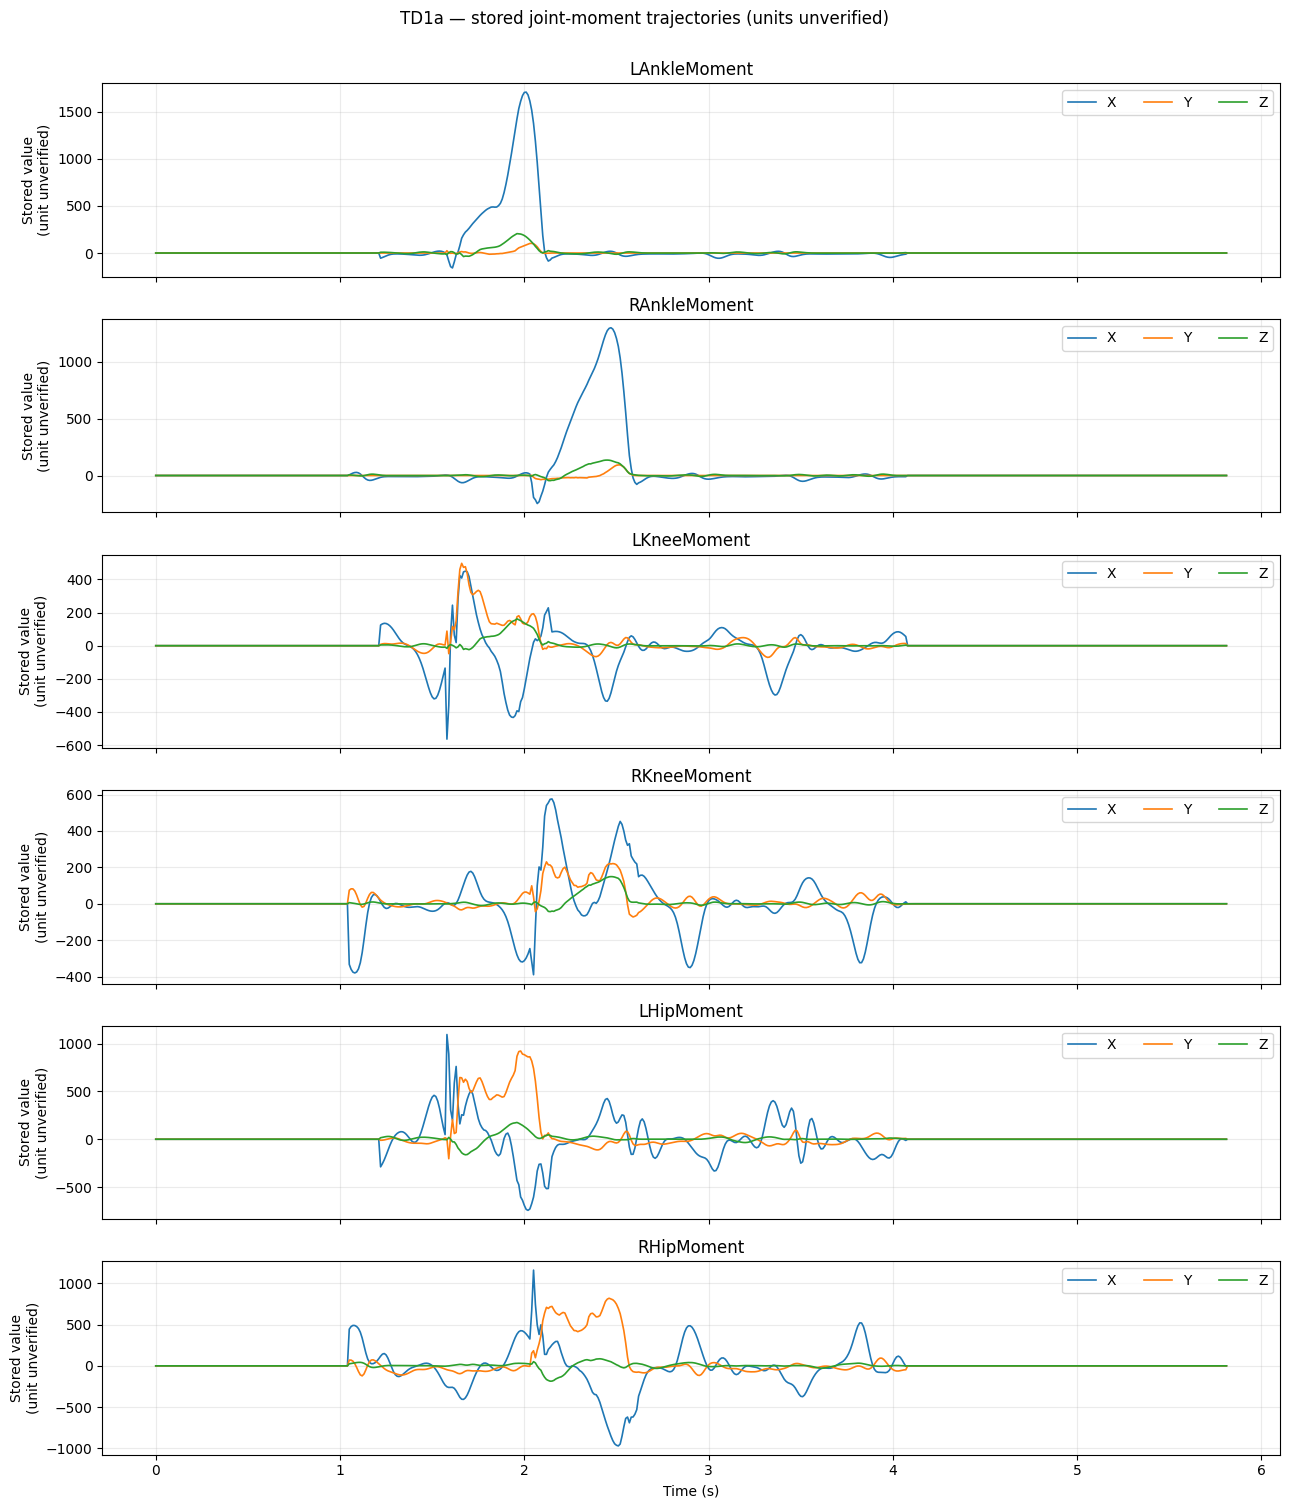

Saved: /content/drive/MyDrive/Pediatric_GaitProject/review_outputs/joint_moment_target_audit_TD1a.png


In [24]:

# CELL 23 — Audit precomputed joint-moment trajectories
# Project paths remain under Pediatric_GaitProject.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
OUT = ROOT / "review_outputs"
OUT.mkdir(parents=True, exist_ok=True)

# Reuse c3d_paths if already defined; otherwise locate TD1a in the CP archive
# extraction directory. This does not modify any source files.
td1a_candidates = [
    p for p in globals().get("c3d_paths", [])
    if Path(str(p)).name.lower() == "td1a.c3d"
]

if not td1a_candidates:
    search_roots = [ROOT / "extracted", ROOT / "input"]
    for search_root in search_roots:
        if search_root.exists():
            td1a_candidates.extend(
                p for p in search_root.rglob("TD1a.c3d")
                if p.is_file()
            )

if not td1a_candidates:
    raise FileNotFoundError(
        "TD1a.c3d was not found. Check the CP archive extraction cell "
        "and set c3d_path to the extracted TD1a.c3d file."
    )

c3d_path = str(td1a_candidates[0])

try:
    import ezc3d
except ImportError:
    %pip -q install ezc3d
    import ezc3d

c3d = ezc3d.c3d(c3d_path)
point = c3d["data"]["points"]
point_params = c3d["parameters"]["POINT"]

labels = [
    str(x).strip()
    for x in point_params["LABELS"]["value"]
]
units = point_params.get("UNITS", {}).get("value", ["unknown"])
point_rate = float(point_params["RATE"]["value"][0])

# Point data convention: (coordinate, marker/variable, frame)
# These named variables may be stored in the first three coordinates.
# Check array shape before extracting.
print("File:", c3d_path)
print("POINT array shape:", point.shape)
print("POINT rate:", point_rate, "Hz")
print("POINT units metadata:", units)

targets = [
    "LAnkleMoment", "RAnkleMoment",
    "LKneeMoment",  "RKneeMoment",
    "LHipMoment",   "RHipMoment",
]

rows = []
trajectories = {}

for target in targets:
    # Match exact labels, not substring guesses.
    matches = [i for i, label in enumerate(labels) if label == target]

    if not matches:
        rows.append({
            "target": target,
            "found": False,
            "frames": 0,
            "finite_fraction": np.nan,
            "min": np.nan,
            "max": np.nan,
            "std": np.nan,
            "likely_unit": "not established",
        })
        continue

    idx = matches[0]
    values = np.asarray(point[:3, idx, :], dtype=float)
    finite = np.isfinite(values)

    rows.append({
        "target": target,
        "found": True,
        "frames": values.shape[-1],
        "finite_fraction": float(finite.mean()),
        "min": float(np.nanmin(values)),
        "max": float(np.nanmax(values)),
        "std": float(np.nanstd(values)),
        "likely_unit": "unknown; verify source pipeline",
    })
    trajectories[target] = values

audit = pd.DataFrame(rows)
display(audit)

csv_path = OUT / "joint_moment_target_audit_TD1a.csv"
audit.to_csv(csv_path, index=False)
print("Saved:", csv_path)

# Plot all available targets. Components are plotted separately.
if trajectories:
    fig, axes = plt.subplots(
        len(trajectories), 1,
        figsize=(13, max(3, 2.5 * len(trajectories))),
        sharex=True
    )
    axes = np.atleast_1d(axes)

    for ax, (target, values) in zip(axes, trajectories.items()):
        t = np.arange(values.shape[-1]) / point_rate
        for component, name in enumerate(["X", "Y", "Z"]):
            ax.plot(t, values[component], label=name, linewidth=1.2)
        ax.set_title(target)
        ax.set_ylabel("Stored value\n(unit unverified)")
        ax.grid(True, alpha=0.25)
        ax.legend(ncol=3, loc="upper right")

    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(
        "TD1a — stored joint-moment trajectories (units unverified)",
        y=1.002
    )
    fig.tight_layout()

    plot_path = OUT / "joint_moment_target_audit_TD1a.png"
    fig.savefig(plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", plot_path)
else:
    print("No target trajectories were extracted; inspect labels and array layout.")

C3D files discovered: 21
Unique trials audited: 21

Availability by group and target:


,group,target,trials_checked,trials_with_target
0,dicp,LAnkleMoment,6,2
1,dicp,LHipMoment,6,2
2,dicp,LKneeMoment,6,2
3,dicp,RAnkleMoment,6,2
4,dicp,RHipMoment,6,2
5,dicp,RKneeMoment,6,2
6,hecp,LAnkleMoment,7,0
7,hecp,LHipMoment,7,0
8,hecp,LKneeMoment,7,0
9,hecp,RAnkleMoment,7,0



Axis statistics by target and group:


min                           max            \
                           median       min       max    median       min   
group target       axis                                                     
dicp  LAnkleMoment X     -100.894  -104.268   -97.520  1406.700  1243.365   
                   Y      -58.649  -115.641    -1.656    73.939    37.509   
                   Z      -38.384   -44.794   -31.974   145.363   112.063   
      LHipMoment   X    -2694.814 -2751.755 -2637.872  2906.155  2096.468   
                   Y     -747.166  -828.579  -665.753   917.287   882.559   
                   Z     -179.559  -243.066  -116.053   144.061   127.438   
      LKneeMoment  X    -1022.471 -1200.982  -843.960  1031.071   751.175   
                   Y     -285.368  -320.857  -249.878   465.300   394.322   
                   Z      -29.000   -31.631   -26.368    86.910    52.297   
      RAnkleMoment X      -93.251  -103.733   -82.768  1414.189  1349.381   
                   Y       -3.242    -6.388    -0.097   149.981   144.631   
                   Z      -68.560   -71.895   -65.225   111.740    88.556   
      RHipMoment   X    -1769.629 -1809.732 -1729.526  3272.953  2993.166   
                   Y     -751.282  -916.598  -585.965   922.479   901.563   
                   Z     -214.335  -231.191  -197.479   182.469   162.059   
      RKneeMoment  X     -984.034 -1040.158  -927.910   953.281   789.886   
                   Y     -373.023  -405.603  -340.442   462.914   385.242   
                   Z      -90.213  -107.081   -73.346    79.032    58.944   
td    LAnkleMoment X     -135.985  -158.552  -113.418  1647.121  1584.891   
                   Y       -7.788   -12.886    -2.690    92.605    82.532   
                   Z      -41.294   -45.058   -37.531   226.291   205.873   
      LHipMoment   X    -1245.931 -1747.855  -744.007  1269.034  1096.033   
                   Y     -258.660  -313.261  -204.059   987.932   923.455   
                   Z     -151.641  -162.551  -140.731   181.603   175.513   
      LKneeMoment  X     -546.663  -563.748  -529.578   548.605   449.495   
                   Y      -99.755  -129.051   -70.458   429.136   361.388   
                   Z      -29.986   -36.006   -23.966   185.767   161.771   
      RAnkleMoment X     -238.599  -246.806  -230.392  1330.688  1301.406   
                   Y      -42.351   -47.843   -36.859   102.835    93.289   
                   Z      -52.810   -60.282   -45.339   121.277   106.603   
      RHipMoment   X     -973.581  -975.104  -972.058  1166.122  1161.838   
                   Y     -207.850  -293.760  -121.940   935.194   820.527   
                   Z     -202.499  -218.904  -186.094    83.021    80.359   
      RKneeMoment  X     -385.142  -389.994  -380.289   655.796   576.176   
                   Y     -110.002  -147.501   -72.503   243.987   230.250   
                   Z      -53.628   -63.940   -43.316   142.066   134.925   

                                     mean                      std           \
                              max  median     min     max   median      min   
group target       axis                                                       
dicp  LAnkleMoment X     1570.035  63.495  52.364  74.625  258.708  214.835   
                   Y      110.369   0.149  -4.519   4.816   19.235   18.941   
                   Z      178.664   5.981   3.235   8.726   23.806   16.835   
      LHipMoment   X     3715.842  13.680  10.459  16.900  360.056  346.836   
                   Y      952.015  31.441  16.063  46.820  178.790  142.909   
                   Z      160.684  -0.358  -3.551   2.836   29.810   17.813   
      LKneeMoment  X     1310.967  -7.595 -13.887  -1.304  143.650  121.693   
                   Y      536.277  10.867   8.127  13.606   66.539   66.063   
                   Z      121.524   3.319   2.969   3.668   14.614   11.101   
      RAnkleMoment X     1478.997  68.277  56.642  79.912  271.352  229.154   


Saved:
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/joint_moment_availability_all_trials.csv
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/joint_moment_axis_statistics_all_trials.csv


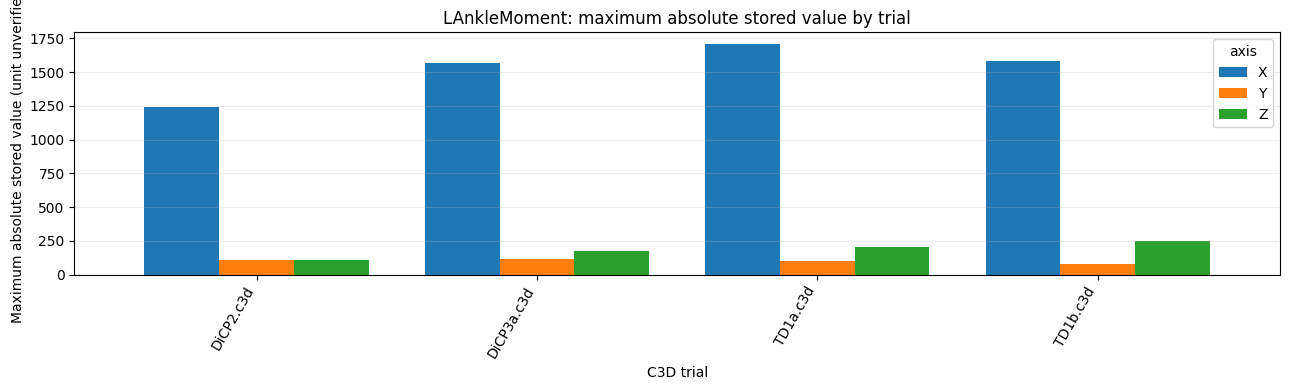

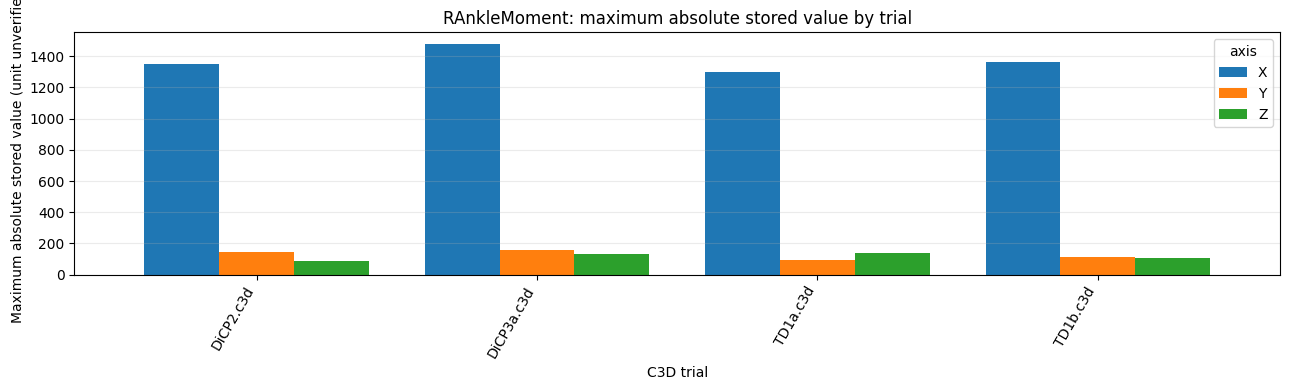

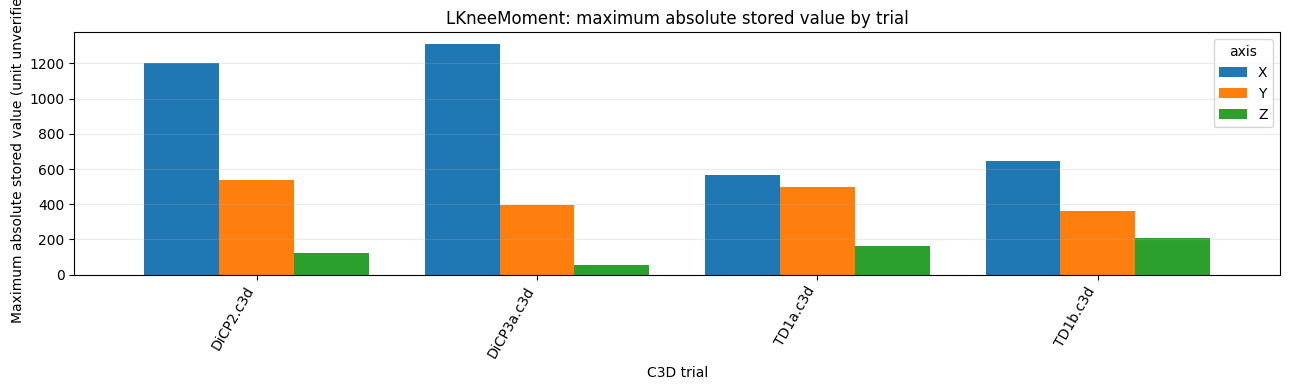

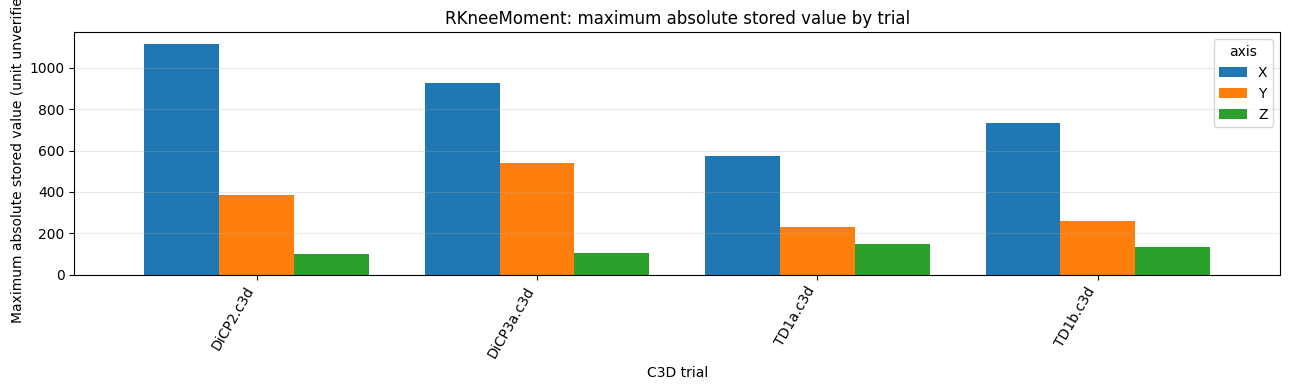

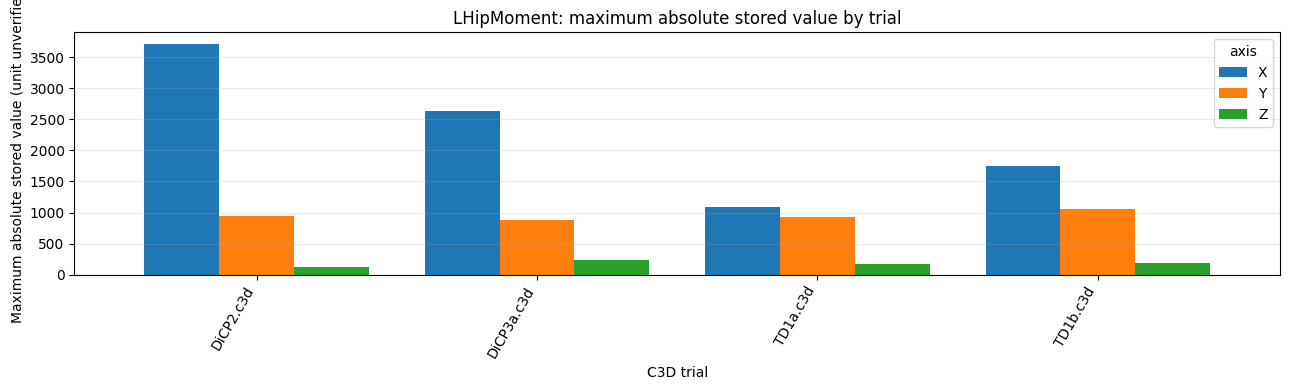

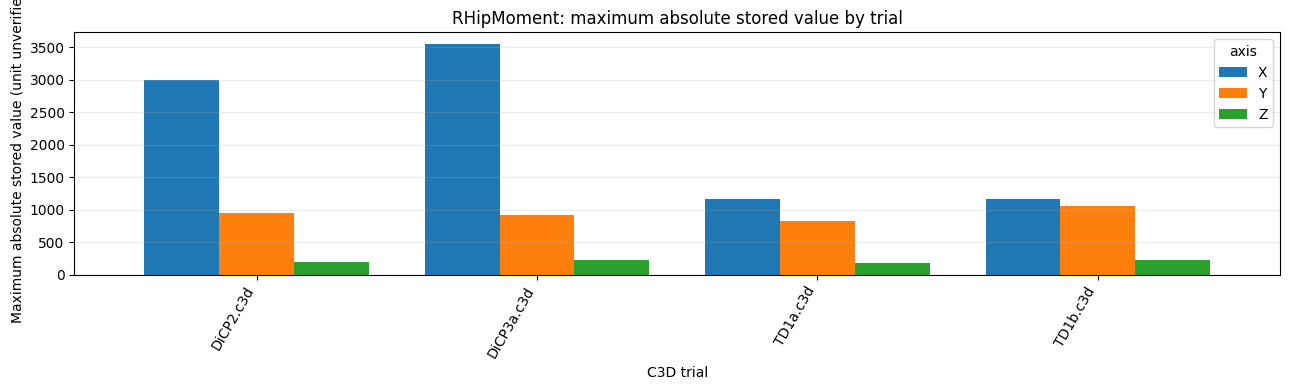


Audit complete. No physical units or clinical validity are inferred.


In [25]:

# CELL 24 — Cross-trial joint-moment consistency audit
# Reads existing C3D files only; does not train or modify the checkpoint.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
OUT = ROOT / "review_outputs"
OUT.mkdir(parents=True, exist_ok=True)

# Discover C3Ds using the existing extraction layout.
c3d_files = sorted((ROOT / "extracted" / "cp").rglob("*.c3d"))

if not c3d_files:
    raise FileNotFoundError(
        "No extracted C3D files found under "
        f"{ROOT / 'extracted' / 'cp'}. Re-run the archive extraction cell."
    )

import ezc3d

TARGETS = [
    "LAnkleMoment", "RAnkleMoment",
    "LKneeMoment", "RKneeMoment",
    "LHipMoment", "RHipMoment",
]

summary_rows = []
availability_rows = []

for path in c3d_files:
    try:
        c3d = ezc3d.c3d(str(path))
        point = np.asarray(c3d["data"]["points"], dtype=float)
        params = c3d["parameters"]["POINT"]
        labels = [str(x).strip() for x in params["LABELS"]["value"]]
        rate = float(params["RATE"]["value"][0])

        group = path.parent.name.lower()
        if group not in {"td", "hecp", "dicp"}:
            group = "unknown"

        for target in TARGETS:
            indices = [i for i, lab in enumerate(labels) if lab == target]
            found = bool(indices)

            availability_rows.append({
                "trial": path.name,
                "group": group,
                "target": target,
                "found": found,
                "point_rate_hz": rate,
                "frames": int(point.shape[-1]),
            })

            if not found:
                continue

            # Stored values for the three components, not assumed physical units.
            values = point[:3, indices[0], :]
            finite = np.isfinite(values)

            for axis_idx, axis_name in enumerate(["X", "Y", "Z"]):
                v = values[axis_idx]
                vf = v[np.isfinite(v)]

                if len(vf) == 0:
                    continue

                summary_rows.append({
                    "trial": path.name,
                    "group": group,
                    "target": target,
                    "axis": axis_name,
                    "frames": len(v),
                    "finite_fraction": float(finite[axis_idx].mean()),
                    "min": float(vf.min()),
                    "max": float(vf.max()),
                    "mean": float(vf.mean()),
                    "std": float(vf.std()),
                    # Diagnostic threshold only; not a biomechanical threshold.
                    "near_zero_fraction_abs_lt_1": float(
                        np.mean(np.abs(vf) < 1.0)
                    ),
                    "point_rate_hz": rate,
                })

    except Exception as exc:
        print(f"WARNING: Could not audit {path.name}: {exc}")

availability = pd.DataFrame(availability_rows)
stats = pd.DataFrame(summary_rows)

availability_path = OUT / "joint_moment_availability_all_trials.csv"
stats_path = OUT / "joint_moment_axis_statistics_all_trials.csv"

availability.to_csv(availability_path, index=False)
stats.to_csv(stats_path, index=False)

print("C3D files discovered:", len(c3d_files))
print("Unique trials audited:", availability["trial"].nunique())
print("\nAvailability by group and target:")
display(
    availability.groupby(["group", "target"])["found"]
    .agg(["count", "sum"])
    .rename(columns={"count": "trials_checked", "sum": "trials_with_target"})
    .reset_index()
)

print("\nAxis statistics by target and group:")
if not stats.empty:
    display(
        stats.groupby(["group", "target", "axis"])[
            ["min", "max", "mean", "std", "near_zero_fraction_abs_lt_1"]
        ].agg(["median", "min", "max"]).round(3)
    )

print("\nSaved:")
print(availability_path)
print(stats_path)

# Plot per-trial maximum absolute magnitude for each target and component.
if not stats.empty:
    stats["max_abs"] = stats[["min", "max"]].abs().max(axis=1)

    for target in TARGETS:
        subset = stats[stats["target"] == target]
        if subset.empty:
            continue

        pivot = subset.pivot_table(
            index="trial", columns="axis", values="max_abs", aggfunc="first"
        )
        ax = pivot.plot(
            kind="bar", figsize=(13, 4), width=0.8,
            title=f"{target}: maximum absolute stored value by trial"
        )
        ax.set_ylabel("Maximum absolute stored value (unit unverified)")
        ax.set_xlabel("C3D trial")
        ax.grid(axis="y", alpha=0.25)
        plt.xticks(rotation=60, ha="right")
        plt.tight_layout()
        plot_path = OUT / f"moment_magnitude_{target}_all_trials.png"
        plt.savefig(plot_path, dpi=150, bbox_inches="tight")
        plt.show()
        plt.close()

print("\nAudit complete. No physical units or clinical validity are inferred.")

In [26]:

# CELL 25 — Checkpoint provenance and data-to-target mapping audit
# Run AFTER Cell 24 in PEDIGAIT(1).ipynb.

from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import torch

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
INP = ROOT / "input"
OUT = ROOT / "review_outputs"
OUT.mkdir(parents=True, exist_ok=True)

CKPT_PATH = INP / "best_pediatric_pinn.pth"
WORKBOOK_PATH = INP / "Stratifiedfoldkinematicparametersandcurves.xlsx"

assert CKPT_PATH.exists(), f"Checkpoint missing: {CKPT_PATH}"
assert WORKBOOK_PATH.exists(), f"Workbook missing: {WORKBOOK_PATH}"

# 1. Verify the exact checkpoint file.
sha256 = hashlib.sha256(CKPT_PATH.read_bytes()).hexdigest()
checkpoint = torch.load(
    CKPT_PATH, map_location="cpu", weights_only=True
)

print("Checkpoint SHA-256:", sha256)
print("Checkpoint object type:", type(checkpoint).__name__)
print("Checkpoint entries:", list(checkpoint.keys()))

# 2. Inspect parameter names and shapes.
parameter_rows = []
for name, tensor in checkpoint.items():
    if isinstance(tensor, torch.Tensor):
        parameter_rows.append({
            "parameter": name,
            "shape": str(tuple(tensor.shape)),
            "dtype": str(tensor.dtype),
            "numel": tensor.numel(),
            "finite_fraction": (
                float(torch.isfinite(tensor).float().mean())
                if tensor.numel() else np.nan
            ),
        })

parameter_df = pd.DataFrame(parameter_rows)
display(parameter_df)

parameter_df.to_csv(
    OUT / "checkpoint_parameter_inventory.csv", index=False
)

# A weights-only state dictionary does not normally contain the original
# training configuration, feature names, scalers, or target names.
metadata_candidates = [
    k for k in checkpoint.keys()
    if any(term in k.lower() for term in (
        "metadata", "feature", "target", "scaler",
        "mean", "std", "normal", "epoch", "config"
    ))
]
print("\nPossible metadata entries:", metadata_candidates or "None found")

# 3. Load the supplied workbook's variable dictionary.
dictionary = pd.read_excel(
    WORKBOOK_PATH, sheet_name="Dictionary"
)
dictionary.columns = [str(c).strip() for c in dictionary.columns]

print("\nDictionary columns:", dictionary.columns.tolist())
display(dictionary.head(25))

dictionary.to_csv(
    OUT / "workbook_variable_dictionary.csv", index=False
)

# 4. Verify the actual checkpoint tensor contracts.
# These shapes are architectural facts, NOT semantic feature names.
required_keys = [
    "conv1.weight", "fc_out.weight", "fc_out.bias"
]
missing_keys = [k for k in required_keys if k not in checkpoint]
if missing_keys:
    print("WARNING: expected architecture keys missing:", missing_keys)
else:
    print("Conv input channels:", checkpoint["conv1.weight"].shape[1])
    print("Output channels:", checkpoint["fc_out.weight"].shape[0])
    print("Output bias shape:", tuple(checkpoint["fc_out.bias"].shape))

# 5. Build an intentionally UNVERIFIED mapping template.
input_mapping = pd.DataFrame({
    "input_channel": [f"input_{i:02d}" for i in range(18)],
    "source_variable": ["UNVERIFIED"] * 18,
    "unit": ["UNVERIFIED"] * 18,
    "preprocessing": ["UNVERIFIED"] * 18,
    "evidence": ["Original training pipeline not yet recovered"] * 18,
})
output_mapping = pd.DataFrame({
    "output_channel": [f"output_{i:02d}" for i in range(9)],
    "target_variable": ["UNVERIFIED"] * 9,
    "unit": ["UNVERIFIED"] * 9,
    "evidence": ["Original target definition not yet recovered"] * 9,
})

input_mapping.to_csv(OUT / "checkpoint_input_mapping_template.csv", index=False)
output_mapping.to_csv(OUT / "checkpoint_output_mapping_template.csv", index=False)

# 6. Save an audit summary.
audit_summary = {
    "checkpoint_file": CKPT_PATH.name,
    "sha256": sha256,
    "checkpoint_is_state_dict": isinstance(checkpoint, dict),
    "tensor_parameter_count": int(parameter_df["numel"].sum()),
    "input_channels_architecture": (
        int(checkpoint["conv1.weight"].shape[1])
        if "conv1.weight" in checkpoint else None
    ),
    "output_channels_architecture": (
        int(checkpoint["fc_out.weight"].shape[0])
        if "fc_out.weight" in checkpoint else None
    ),
    "feature_mapping_verified": False,
    "target_mapping_verified": False,
    "normalization_verified": False,
    "training_dataset_provenance_verified": False,
    "joint_moment_prediction_authorized": False,
}

with open(OUT / "checkpoint_provenance_audit.json", "w") as f:
    json.dump(audit_summary, f, indent=2)

print("\nSaved audit artifacts under:", OUT)
print(json.dumps(audit_summary, indent=2))

Checkpoint SHA-256: a1eaad2410a15e83b2bcb8aeee38d3000c81f4b7358fae73b4f7bab2ef6ee763
Checkpoint object type: OrderedDict
Checkpoint entries: ['conv1.weight', 'conv1.bias', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'bilstm.weight_ih_l0', 'bilstm.weight_hh_l0', 'bilstm.bias_ih_l0', 'bilstm.bias_hh_l0', 'bilstm.weight_ih_l0_reverse', 'bilstm.weight_hh_l0_reverse', 'bilstm.bias_ih_l0_reverse', 'bilstm.bias_hh_l0_reverse', 'bilstm.weight_ih_l1', 'bilstm.weight_hh_l1', 'bilstm.bias_ih_l1', 'bilstm.bias_hh_l1', 'bilstm.weight_ih_l1_reverse', 'bilstm.weight_hh_l1_reverse', 'bilstm.bias_ih_l1_reverse', 'bilstm.bias_hh_l1_reverse', 'fc1.weight', 'fc1.bias', 'fc_out.weight', 'fc_out.bias']


,parameter,shape,dtype,numel,finite_fraction
0,conv1.weight,"(64, 18, 3)",torch.float32,3456,1.0
1,conv1.bias,"(64,)",torch.float32,64,1.0
2,bn1.weight,"(64,)",torch.float32,64,1.0
3,bn1.bias,"(64,)",torch.float32,64,1.0
4,bn1.running_mean,"(64,)",torch.float32,64,1.0
5,bn1.running_var,"(64,)",torch.float32,64,1.0
6,bn1.num_batches_tracked,(),torch.int64,1,1.0
7,bilstm.weight_ih_l0,"(512, 66)",torch.float32,33792,1.0
8,bilstm.weight_hh_l0,"(512, 128)",torch.float32,65536,1.0
9,bilstm.bias_ih_l0,"(512,)",torch.float32,512,1.0



Possible metadata entries: ['bn1.running_mean']

Dictionary columns: ['Variable code name', 'Explanation']


,Variable code name,Explanation
0,Patient ID,anonymized patient ID
1,No. of GA,number of gait analysis sessions
2,Trial no.,number of walking trial
3,cycle,recorded step
4,side,left or right side
5,PS,classification for the movement of the pelvis ...
6,HS,classification for the movement of the hip in ...
7,KStS,classification for the movement of the knee du...
8,KSwS,classification for the movement of the knee du...
9,AStS,classification for the movement of the ankle d...


Conv input channels: 18
Output channels: 9
Output bias shape: (9,)

Saved audit artifacts under: /content/drive/MyDrive/Pediatric_GaitProject/review_outputs
{
  "checkpoint_file": "best_pediatric_pinn.pth",
  "sha256": "a1eaad2410a15e83b2bcb8aeee38d3000c81f4b7358fae73b4f7bab2ef6ee763",
  "checkpoint_is_state_dict": true,
  "tensor_parameter_count": 616778,
  "input_channels_architecture": 18,
  "output_channels_architecture": 9,
  "feature_mapping_verified": false,
  "target_mapping_verified": false,
  "normalization_verified": false,
  "training_dataset_provenance_verified": false,
  "joint_moment_prediction_authorized": false
}


In [27]:

# CELL 26 — Real C3D trial browser
# Uses actual C3D data; does not call the unverified checkpoint.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ezc3d

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
except ImportError:
    %pip -q install ipywidgets
    import ipywidgets as widgets
    from IPython.display import display, clear_output

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
OUT = ROOT / "review_outputs"
C3D_ROOT = ROOT / "extracted" / "cp"

c3d_files = sorted(C3D_ROOT.rglob("*.c3d"))
if not c3d_files:
    raise FileNotFoundError(f"No C3D trials found under {C3D_ROOT}")

TARGETS = [
    "LAnkleMoment", "RAnkleMoment",
    "LKneeMoment", "RKneeMoment",
    "LHipMoment", "RHipMoment",
]

def load_trial(trial_path):
    """Read one real C3D trial and preserve source labels and frame rate."""
    c = ezc3d.c3d(str(trial_path))
    point = np.asarray(c["data"]["points"], dtype=float)
    params = c["parameters"]["POINT"]
    labels = [str(x).strip() for x in params["LABELS"]["value"]]
    rate = float(params["RATE"]["value"][0])
    return c, point, labels, rate

def show_trial(trial_name):
    matches = [p for p in c3d_files if p.name == trial_name]
    if not matches:
        print("Trial not found:", trial_name)
        return

    path = matches[0]
    c, point, labels, rate = load_trial(path)

    print("Source file:", path)
    print("Group folder:", path.parent.name)
    print("POINT shape:", point.shape)
    print("Frame rate:", rate, "Hz")
    print("POINT units metadata:",
          c["parameters"]["POINT"].get("UNITS", {}).get("value", ["unknown"]))

    fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex=True)
    axes = axes.ravel()
    inventory = []

    for ax, target in zip(axes, TARGETS):
        indices = [i for i, label in enumerate(labels) if label == target]

        if not indices:
            ax.set_title(f"{target} — not present")
            ax.text(0.5, 0.5, "No exact label match",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_axis_off()
            inventory.append({
                "trial": path.name, "target": target,
                "found": False, "frames": 0,
                "finite_fraction": np.nan,
            })
            continue

        # Use exact label match and the first occurrence only.
        values = point[:3, indices[0], :]
        time_s = np.arange(values.shape[-1]) / rate

        for j, axis_name in enumerate(["X", "Y", "Z"]):
            series = values[j]
            series = np.where(np.isfinite(series), series, np.nan)
            ax.plot(time_s, series, label=axis_name, linewidth=1)

        ax.set_title(target)
        ax.set_ylabel("Stored value (unit unverified)")
        ax.grid(True, alpha=0.25)
        ax.legend()

        inventory.append({
            "trial": path.name,
            "target": target,
            "found": True,
            "frames": values.shape[-1],
            "finite_fraction": float(np.isfinite(values).mean()),
        })

    for ax in axes[-2:]:
        ax.set_xlabel("Time (s)")

    fig.suptitle(
        f"Measured C3D trajectories — {path.name}\n"
        "Stored values; physical units and sign conventions unverified"
    )
    fig.tight_layout()
    plt.show()

    return pd.DataFrame(inventory)

trial_options = [p.name for p in c3d_files]
trial_dropdown = widgets.Dropdown(
    options=trial_options,
    value="TD1a.c3d" if "TD1a.c3d" in trial_options else trial_options[0],
    description="Real trial:",
    layout=widgets.Layout(width="400px")
)

trial_output = widgets.Output()

def update_trial(change=None):
    with trial_output:
        clear_output(wait=True)
        result = show_trial(trial_dropdown.value)
        if result is not None:
            display(result)

trial_dropdown.observe(update_trial, names="value")
display(trial_dropdown, trial_output)
update_trial()

print("Trial browser ready. All curves originate from the selected C3D file.")

Dropdown(description='Real trial:', index=13, layout=Layout(width='400px'), options=('DiCP1.c3d', 'DiCP2.c3d',…

Output()

Trial browser ready. All curves originate from the selected C3D file.


In [28]:

# CELL 27 — Trace potential training-source files
# Run after Cell 26. Uses only the existing project directory.

from pathlib import Path
import hashlib
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
OUT = ROOT / "review_outputs"
OUT.mkdir(parents=True, exist_ok=True)

SEARCH_ROOTS = [
    ROOT / "input",
    ROOT / "extracted" / "maastricht",
]

extensions = {".xlsx", ".xls", ".csv"}
candidate_files = sorted({
    p.resolve()
    for base in SEARCH_ROOTS if base.exists()
    for p in base.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
})

print("Candidate tabular files found:", len(candidate_files))
for p in candidate_files:
    print(" -", p)

inventory = []
column_inventory = []

for path in candidate_files:
    file_hash = hashlib.sha256(path.read_bytes()).hexdigest()

    try:
        if path.suffix.lower() == ".csv":
            df = pd.read_csv(path, nrows=5)
            numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

            inventory.append({
                "file": str(path),
                "sha256": file_hash,
                "sheet": "(CSV)",
                "rows_inspected": len(df),
                "column_count": len(df.columns),
                "numeric_column_count": len(numeric_cols),
                "status": "read",
            })

            for pos, col in enumerate(df.columns):
                column_inventory.append({
                    "file": str(path),
                    "sheet": "(CSV)",
                    "column_position": pos,
                    "column_name": str(col),
                    "numeric_in_sample": col in numeric_cols,
                })

        else:
            xls = pd.ExcelFile(path)
            for sheet in xls.sheet_names:
                df = pd.read_excel(path, sheet_name=sheet, nrows=5)
                numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

                inventory.append({
                    "file": str(path),
                    "sha256": file_hash,
                    "sheet": sheet,
                    "rows_inspected": len(df),
                    "column_count": len(df.columns),
                    "numeric_column_count": len(numeric_cols),
                    "status": "read",
                })

                for pos, col in enumerate(df.columns):
                    column_inventory.append({
                        "file": str(path),
                        "sheet": sheet,
                        "column_position": pos,
                        "column_name": str(col),
                        "numeric_in_sample": col in numeric_cols,
                    })

    except Exception as exc:
        inventory.append({
            "file": str(path),
            "sha256": file_hash,
            "sheet": None,
            "rows_inspected": None,
            "column_count": None,
            "numeric_column_count": None,
            "status": f"ERROR: {exc}",
        })

inventory_df = pd.DataFrame(inventory)
columns_df = pd.DataFrame(column_inventory)

display(inventory_df)
display(columns_df.head(150))

inventory_df.to_csv(OUT / "candidate_training_files.csv", index=False)
columns_df.to_csv(OUT / "candidate_training_columns.csv", index=False)

print("\nSaved:")
print(OUT / "candidate_training_files.csv")
print(OUT / "candidate_training_columns.csv")

Candidate tabular files found: 8
 - /content/drive/MyDrive/Pediatric_GaitProject/extracted/maastricht/children gait/01_Demo_PhysEx.xlsx
 - /content/drive/MyDrive/Pediatric_GaitProject/extracted/maastricht/children gait/02_Overview_comf.xlsx
 - /content/drive/MyDrive/Pediatric_GaitProject/extracted/maastricht/children gait/03_Overview_fast.xlsx
 - /content/drive/MyDrive/Pediatric_GaitProject/extracted/maastricht/children gait/04_Overview_slow.xlsx
 - /content/drive/MyDrive/Pediatric_GaitProject/extracted/maastricht/children gait/05_AgeGroups_comf.xlsx
 - /content/drive/MyDrive/Pediatric_GaitProject/extracted/maastricht/children gait/06_AgeGroups_fast.xlsx
 - /content/drive/MyDrive/Pediatric_GaitProject/extracted/maastricht/children gait/07_AgeGroups_slow.xlsx
 - /content/drive/MyDrive/Pediatric_GaitProject/input/Stratifiedfoldkinematicparametersandcurves.xlsx


,file,sha256,sheet,rows_inspected,column_count,numeric_column_count,status
0,/content/drive/MyDrive/Pediatric_GaitProject/e...,ac9f7abb93c85b9d87197e054303fd0b4bfa20787c1cc9...,demographics,5,57,57,read
1,/content/drive/MyDrive/Pediatric_GaitProject/e...,3d0a4fdf0c29e93ea42daa343dae84873262b43ac01bb9...,gait_comf,5,49,48,read
2,/content/drive/MyDrive/Pediatric_GaitProject/e...,3d0a4fdf0c29e93ea42daa343dae84873262b43ac01bb9...,Rotation TrunkTilt_comf,5,102,101,read
3,/content/drive/MyDrive/Pediatric_GaitProject/e...,3d0a4fdf0c29e93ea42daa343dae84873262b43ac01bb9...,Rotation TrunkFlex_comf,5,102,101,read
4,/content/drive/MyDrive/Pediatric_GaitProject/e...,3d0a4fdf0c29e93ea42daa343dae84873262b43ac01bb9...,Rotation TrunkRot_comf,5,102,101,read
...,...,...,...,...,...,...,...
243,/content/drive/MyDrive/Pediatric_GaitProject/i...,ee060212061d406f259d62d635ff65c103525437e9e57a...,Fold8,5,844,802,read
244,/content/drive/MyDrive/Pediatric_GaitProject/i...,ee060212061d406f259d62d635ff65c103525437e9e57a...,Fold9,5,844,802,read
245,/content/drive/MyDrive/Pediatric_GaitProject/i...,ee060212061d406f259d62d635ff65c103525437e9e57a...,Fold10,5,844,802,read
246,/content/drive/MyDrive/Pediatric_GaitProject/i...,ee060212061d406f259d62d635ff65c103525437e9e57a...,ALL,5,844,802,read


,file,sheet,column_position,column_name,numeric_in_sample
0,/content/drive/MyDrive/Pediatric_GaitProject/e...,demographics,0,Subject,True
1,/content/drive/MyDrive/Pediatric_GaitProject/e...,demographics,1,Age\n (yrs),True
2,/content/drive/MyDrive/Pediatric_GaitProject/e...,demographics,2,gender \n(0 boy/1 girl),True
3,/content/drive/MyDrive/Pediatric_GaitProject/e...,demographics,3,Body mass \n (kg),True
4,/content/drive/MyDrive/Pediatric_GaitProject/e...,demographics,4,Body height \n (cm),True
...,...,...,...,...,...
145,/content/drive/MyDrive/Pediatric_GaitProject/e...,Rotation TrunkTilt_comf,39,38,True
146,/content/drive/MyDrive/Pediatric_GaitProject/e...,Rotation TrunkTilt_comf,40,39,True
147,/content/drive/MyDrive/Pediatric_GaitProject/e...,Rotation TrunkTilt_comf,41,40,True
148,/content/drive/MyDrive/Pediatric_GaitProject/e...,Rotation TrunkTilt_comf,42,41,True



Saved:
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/candidate_training_files.csv
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/candidate_training_columns.csv


In [29]:

# CELL 28 — Reproducibility and validation status report

from pathlib import Path
import json
import pandas as pd
from datetime import datetime, timezone

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
OUT = ROOT / "review_outputs"
OUT.mkdir(parents=True, exist_ok=True)

status_rows = [
    {
        "requirement": "Real data are used",
        "status": "PARTIALLY VERIFIED",
        "evidence": (
            "Real C3D trials and a clinical workbook are present. "
            "The original training notebook reports five ingested samples, "
            "but the exact source files used for the supplied checkpoint "
            "must be matched."
        ),
    },
    {
        "requirement": "Model is understood",
        "status": "PARTIALLY VERIFIED",
        "evidence": (
            "CNN plus bidirectional LSTM; 18 signal channels; two "
            "anthropometric inputs; nine output channels. Original feature "
            "and target names, units, and fitted scalers are not fully "
            "established."
        ),
    },
    {
        "requirement": "Physics component is real",
        "status": "NOT VERIFIED",
        "evidence": (
            "The recovered training loss includes a second-difference "
            "smoothness penalty. This is a temporal regularizer, not a "
            "verified inverse-dynamics equation."
        ),
    },
    {
        "requirement": "Performance is demonstrated",
        "status": "NOT VERIFIED",
        "evidence": (
            "No defensible held-out-participant prediction metrics have "
            "been established for the supplied checkpoint."
        ),
    },
    {
        "requirement": "Digital twin works end to end",
        "status": "PARTIALLY VERIFIED",
        "evidence": (
            "The real-trial visualization uses source C3D files. "
            "Checkpoint inference is intentionally not presented as "
            "validated clinical prediction."
        ),
    },
]

status_df = pd.DataFrame(status_rows)
display(status_df)

status_df.to_csv(
    OUT / "project_validation_status.csv", index=False
)

report = {
    "project": "Pediatric Gait Digital Twin",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "project_root": str(ROOT),
    "checkpoint": "best_pediatric_pinn.pth",
    "validation_status": status_rows,
    "scientific_safeguards": [
        "Do not interpret checkpoint channels as joint moments without verified mapping.",
        "Do not report synthetic smoke-test outputs as real predictions.",
        "Do not report training loss as held-out test accuracy.",
        "Do not claim participant-independent validation without verified subject IDs.",
        "Do not call temporal smoothness alone an inverse-dynamics physics constraint.",
        "Keep physical units unverified until source processing and conventions are established.",
    ],
}

with open(OUT / "project_validation_status.json", "w") as f:
    json.dump(report, f, indent=2)

print("Saved:")
print(OUT / "project_validation_status.csv")
print(OUT / "project_validation_status.json")

,requirement,status,evidence
0,Real data are used,PARTIALLY VERIFIED,Real C3D trials and a clinical workbook are pr...
1,Model is understood,PARTIALLY VERIFIED,CNN plus bidirectional LSTM; 18 signal channel...
2,Physics component is real,NOT VERIFIED,The recovered training loss includes a second-...
3,Performance is demonstrated,NOT VERIFIED,No defensible held-out-participant prediction ...
4,Digital twin works end to end,PARTIALLY VERIFIED,The real-trial visualization uses source C3D f...


Saved:
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/project_validation_status.csv
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/project_validation_status.json


In [30]:

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
file_path = ROOT / "input" / "Stratifiedfoldkinematicparametersandcurves.xlsx"

# Inspect ALL: dimensions, headers, and representative rows
all_df = pd.read_excel(file_path, sheet_name="ALL")
print("=== ALL SHEET ===")
print("Shape:", all_df.shape)
print("\nColumn names (first 35):")
print(all_df.columns[:35].tolist())
print("\nFirst 3 rows, first 15 columns:")
print(all_df.iloc[:3, :15].to_string(index=False))

# Inspect Dictionary
dictionary_df = pd.read_excel(file_path, sheet_name="Dictionary")
print("\n=== DICTIONARY SHEET ===")
print("Shape:", dictionary_df.shape)
print("\nColumn names:")
print(dictionary_df.columns.tolist())
print("\nFirst 30 rows:")
print(dictionary_df.head(30).to_string(index=False))

=== ALL SHEET ===
Shape: (1719, 844)

Column names (first 35):
['Patient ID', 'No. of GA', 'Trial no.', 'cycle', 'side', 'PS', 'HS', 'KStS', 'KSwS', 'AStS', 'ASwS', 'PC', 'HC', 'PT', 'HT', 'FT', 'SRA_discr', 'aMaxStSagA_discr', 'aIc2SagA_discr', 'aSagA_pct_GC_900_discr', 'aBelow1SDSwSagApct_discr', 'aAbove1SDSwSagApct_discr', 'aIcSagK_discr', 'pctaMaxMStSagK_discr', 'aMinStSagK_discr', 'aMaxSwSagK_discr', 'DeFlKpctSw_discr', 'aRomSagP_discr', 'PS-f2', 'aMinStSagH_discr', 'aRomStSagH_discr', 'aAbove1SDSagHpct_discr', 'aRomCorP_discr', 'PC-f2', 'aBelow1SDSwCorHpct_discr']

First 3 rows, first 15 columns:
 Patient ID No. of GA  Trial no.  cycle  side  PS  HS  KStS  KSwS  AStS  ASwS  PC  HC  PT  HT
          1         a          5      1  LEFT   3   1     2     4     0     0   2   3   1   0
          1         a          5      1 RIGHT   3   1     5     3     1     0   3   2   1   2
          1         a          9      1  LEFT   3   1     2     1     0     0   2   0   0   0

=== DICTIONAR

In [31]:
import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
file_path = ROOT / "input" / "Stratifiedfoldkinematicparametersandcurves.xlsx"

all_df = pd.read_excel(file_path, sheet_name="ALL")
dictionary_df = pd.read_excel(file_path, sheet_name="Dictionary")

# Compare workbook columns with documented variable names
documented = set(
    dictionary_df["Variable code name"].dropna().astype(str).str.strip()
)
all_columns = [str(c).strip() for c in all_df.columns]
undocumented = [c for c in all_columns if c not in documented]

print("=== COLUMN DOCUMENTATION ===")
print("Total columns:", len(all_columns))
print("Documented column names:", sum(c in documented for c in all_columns))
print("Undocumented column names:", len(undocumented))
print("\nFirst 60 undocumented column names:")
print(undocumented[:60])

print("\n=== LAST 100 COLUMN NAMES ===")
for i, col in enumerate(all_columns[-100:], start=len(all_columns)-100):
    print(i, col)

print("\n=== DATASET STRUCTURE ===")
for col in ["Patient ID", "No. of GA", "Trial no.", "cycle", "side"]:
    if col in all_df.columns:
        print(f"{col}: {all_df[col].nunique(dropna=True)} unique values")

print("\n=== PATIENTS AND RECORDS ===")
print("Unique patients:", all_df["Patient ID"].nunique())
print("Rows per patient (first 15):")
print(all_df.groupby("Patient ID").size().head(15).to_string())

print("\n=== DICTIONARY ENTRIES NEAR THE END ===")
print(dictionary_df.tail(40).to_string(index=False))

print("\n=== SAMPLE VALUES FROM LAST 20 COLUMNS ===")
print(all_df.iloc[:3, -20:].to_string(index=False))

=== COLUMN DOCUMENTATION ===
Total columns: 844
Documented column names: 185
Undocumented column names: 659

First 60 undocumented column names:
['aSagP_pct_GC_0', 'aSagP_pct_GC_20', 'aSagP_pct_GC_40', 'aSagP_pct_GC_60', 'aSagP_pct_GC_80', 'aSagP_pct_GC_100', 'aSagP_pct_GC_120', 'aSagP_pct_GC_140', 'aSagP_pct_GC_160', 'aSagP_pct_GC_180', 'aSagP_pct_GC_200', 'aSagP_pct_GC_220', 'aSagP_pct_GC_240', 'aSagP_pct_GC_260', 'aSagP_pct_GC_280', 'aSagP_pct_GC_300', 'aSagP_pct_GC_320', 'aSagP_pct_GC_340', 'aSagP_pct_GC_360', 'aSagP_pct_GC_380', 'aSagP_pct_GC_400', 'aSagP_pct_GC_420', 'aSagP_pct_GC_440', 'aSagP_pct_GC_460', 'aSagP_pct_GC_480', 'aSagP_pct_GC_500', 'aSagP_pct_GC_520', 'aSagP_pct_GC_540', 'aSagP_pct_GC_560', 'aSagP_pct_GC_580', 'aSagP_pct_GC_600', 'aSagP_pct_GC_620', 'aSagP_pct_GC_640', 'aSagP_pct_GC_660', 'aSagP_pct_GC_680', 'aSagP_pct_GC_700', 'aSagP_pct_GC_720', 'aSagP_pct_GC_740', 'aSagP_pct_GC_760', 'aSagP_pct_GC_780', 'aSagP_pct_GC_800', 'aSagP_pct_GC_820', 'aSagP_pct_GC_840', 

In [32]:
import pandas as pd
import numpy as np
import re
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
file_path = ROOT / "input" / "Stratifiedfoldkinematicparametersandcurves.xlsx"

xls = pd.ExcelFile(file_path)
df = pd.read_excel(file_path, sheet_name="ALL")
dictionary = pd.read_excel(file_path, sheet_name="Dictionary")

print("=== WORKBOOK SHEETS ===")
for sheet in xls.sheet_names:
    sheet_df = pd.read_excel(file_path, sheet_name=sheet, nrows=3)
    print(f"{sheet}: sample shape={sheet_df.shape}")

# Identify columns encoding gait-cycle sample points
curve_pattern = re.compile(r"^(.*)_pct_GC_(\d+)$")
curve_families = {}

for col in df.columns:
    match = curve_pattern.match(str(col))
    if match:
        family, point = match.groups()
        curve_families.setdefault(family, []).append((int(point), col))

print("\n=== CURVE FAMILIES ===")
for family, points in sorted(curve_families.items()):
    points = sorted(points)
    values = df[[col for _, col in points]]
    print(
        f"{family}: {len(points)} points; "
        f"range={points[0][0]/10:.0f}%–{points[-1][0]/10:.0f}%; "
        f"rows complete={values.notna().all(axis=1).sum()}/{len(df)}; "
        f"missing values={values.isna().sum().sum()}"
    )

print("\n=== CURVE VALUE RANGES ===")
for family, points in sorted(curve_families.items()):
    cols = [col for _, col in sorted(points)]
    values = df[cols].apply(pd.to_numeric, errors="coerce").to_numpy()
    finite = values[np.isfinite(values)]
    if finite.size:
        print(
            f"{family}: min={finite.min():.3f}, "
            f"max={finite.max():.3f}, "
            f"finite={finite.size}/{values.size}"
        )

print("\n=== CLASSIFICATION LABELS ===")
label_cols = [
    c for c in ["PS", "HS", "KStS", "KSwS", "AStS", "ASwS",
                "PC", "HC", "PT", "HT", "FT"]
    if c in df.columns
]
for col in label_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).sort_index().to_string())

print("\n=== IDENTIFIER / REPEATED-RECORD CHECK ===")
id_cols = ["Patient ID", "No. of GA", "Trial no.", "cycle", "side"]
print("Duplicate rows on identifiers:", df.duplicated(id_cols).sum())
print("Rows with any missing identifier:", df[id_cols].isna().any(axis=1).sum())
print("Unique patients:", df["Patient ID"].nunique())
print("Rows per patient:")
print(df.groupby("Patient ID").size().describe().to_string())

print("\n=== DICTIONARY: CURVE DEFINITIONS ===")
for _, row in dictionary.iterrows():
    code = str(row["Variable code name"])
    if "pct_GC" in code:
        print(f"{code}: {row['Explanation']}")

=== WORKBOOK SHEETS ===
Fold1: sample shape=(3, 844)
Fold2: sample shape=(3, 844)
Fold3: sample shape=(3, 844)
Fold4: sample shape=(3, 844)
Fold5: sample shape=(3, 844)
Fold6: sample shape=(3, 844)
Fold7: sample shape=(3, 844)
Fold8: sample shape=(3, 844)
Fold9: sample shape=(3, 844)
Fold10: sample shape=(3, 844)
ALL: sample shape=(3, 844)
Dictionary: sample shape=(3, 2)

=== CURVE FAMILIES ===
aCorH: 51 points; range=0%–100%; rows complete=1719/1719; missing values=0
aCorP: 51 points; range=0%–100%; rows complete=1719/1719; missing values=0
aSagA: 50 points; range=0%–100%; rows complete=1719/1719; missing values=0
aSagH: 51 points; range=0%–100%; rows complete=1719/1719; missing values=0
aSagK: 51 points; range=0%–100%; rows complete=1719/1719; missing values=0
aSagP: 51 points; range=0%–100%; rows complete=1719/1719; missing values=0
aTransvF: 51 points; range=0%–100%; rows complete=1719/1719; missing values=0
aTransvH: 51 points; range=0%–100%; rows complete=1719/1719; missing value

In [33]:

import pandas as pd
import numpy as np
import re
from pathlib import Path
from collections import defaultdict

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
FILE = ROOT / "input" / "Stratifiedfoldkinematicparametersandcurves.xlsx"

xls = pd.ExcelFile(FILE)
all_df = pd.read_excel(FILE, sheet_name="ALL")
dictionary = pd.read_excel(FILE, sheet_name="Dictionary")

id_cols = ["Patient ID", "No. of GA", "Trial no.", "cycle", "side"]

# 1. Inspect the ankle-angle curve's actual column names.
print("=" * 70)
print("1. ANKLE ANGLE CURVE: COLUMN AUDIT")

ankle_cols = [
    c for c in all_df.columns
    if str(c).startswith("aSagA_pct_GC_")
]
print("Ankle-angle columns:", len(ankle_cols))
print("Columns:", ankle_cols)

points = []
for col in ankle_cols:
    match = re.search(r"_GC_(\d+)$", str(col))
    if match:
        points.append((int(match.group(1)), col))

found = {p for p, _ in points}
expected = set(range(0, 1001, 20))
print("Missing nominal 2%-increment points:",
      sorted(expected - found))
print("Unexpected point suffixes:",
      sorted(found - expected))

# 2. Check whether the ten predefined folds share patients.
print("\n" + "=" * 70)
print("2. FOLD COMPOSITION AND PATIENT OVERLAP")

fold_data = {}
for sheet in [f"Fold{i}" for i in range(1, 11)]:
    fold_df = pd.read_excel(FILE, sheet_name=sheet)
    missing = [c for c in id_cols if c not in fold_df.columns]

    if missing:
        print(f"{sheet}: missing identifier columns: {missing}")
        continue

    fold_data[sheet] = fold_df
    print(
        f"{sheet}: rows={len(fold_df)}, "
        f"patients={fold_df['Patient ID'].nunique()}, "
        f"duplicate identifier records={fold_df.duplicated(id_cols).sum()}"
    )

patient_sets = {
    sheet: set(frame["Patient ID"].dropna().unique())
    for sheet, frame in fold_data.items()
}

print("\nPairwise patient overlaps:")
overlap_found = False
sheets = list(patient_sets)
for i in range(len(sheets)):
    for j in range(i + 1, len(sheets)):
        shared = patient_sets[sheets[i]] & patient_sets[sheets[j]]
        if shared:
            overlap_found = True
            print(f"{sheets[i]} vs {sheets[j]}: {len(shared)} shared patients")

if not overlap_found:
    print("No patient overlap detected between the fold sheets.")

# Compare fold coverage with the ALL sheet.
fold_union = set().union(*patient_sets.values()) if patient_sets else set()
all_patients = set(all_df["Patient ID"].dropna().unique())

print("\nUnique patients across folds:", len(fold_union))
print("Unique patients in ALL:", len(all_patients))
print("Patients in ALL absent from folds:", len(all_patients - fold_union))
print("Patients in folds absent from ALL:", len(fold_union - all_patients))

# 3. Inspect the two duplicate identifier records.
print("\n" + "=" * 70)
print("3. DUPLICATE IDENTIFIER RECORDS")

duplicate_mask = all_df.duplicated(id_cols, keep=False)
if duplicate_mask.any():
    duplicates = all_df.loc[duplicate_mask].sort_values(id_cols)
    print(duplicates[id_cols].to_string(index=False))
    print("Number of rows involved:", len(duplicates))
    print("Are the entire rows identical?",
          all_df.loc[duplicate_mask].duplicated(keep=False).all())
else:
    print("No duplicate identifier records.")

# 4. Inspect dictionary definitions for classification variables.
print("\n" + "=" * 70)
print("4. CLASSIFICATION LABEL DEFINITIONS")

print("Dictionary columns:", dictionary.columns.tolist())

for _, row in dictionary.iterrows():
    code = str(row.get("Variable code name", ""))
    if code in ["PS", "HS", "KStS", "KSwS", "AStS", "ASwS",
                "PC", "HC", "PT", "HT", "FT"]:
        print(f"{code}: {row.get('Explanation', '')}")

# 5. Check whether ALL is simply the concatenation of the folds.
print("\n" + "=" * 70)
print("5. FOLD ROW COUNTS")

for sheet, frame in fold_data.items():
    print(sheet, len(frame))

print("ALL rows:", len(all_df))
print("\nAudit complete. No model has been trained by this cell.")

1. ANKLE ANGLE CURVE: COLUMN AUDIT
Ankle-angle columns: 52
Columns: ['aSagA_pct_GC_900_discr', 'aSagA_pct_GC_0', 'aSagA_pct_GC_20', 'aSagA_pct_GC_40', 'aSagA_pct_GC_60', 'aSagA_pct_GC_80', 'aSagA_pct_GC_100', 'aSagA_pct_GC_120', 'aSagA_pct_GC_140', 'aSagA_pct_GC_160', 'aSagA_pct_GC_180', 'aSagA_pct_GC_200', 'aSagA_pct_GC_220', 'aSagA_pct_GC_240', 'aSagA_pct_GC_260', 'aSagA_pct_GC_280', 'aSagA_pct_GC_300', 'aSagA_pct_GC_320', 'aSagA_pct_GC_340', 'aSagA_pct_GC_360', 'aSagA_pct_GC_380', 'aSagA_pct_GC_400', 'aSagA_pct_GC_420', 'aSagA_pct_GC_440', 'aSagA_pct_GC_460', 'aSagA_pct_GC_480', 'aSagA_pct_GC_500', 'aSagA_pct_GC_520', 'aSagA_pct_GC_540', 'aSagA_pct_GC_560', 'aSagA_pct_GC_580', 'aSagA_pct_GC_600', 'aSagA_pct_GC_620', 'aSagA_pct_GC_640', 'aSagA_pct_GC_660', 'aSagA_pct_GC_680', 'aSagA_pct_GC_700', 'aSagA_pct_GC_720', 'aSagA_pct_GC_740', 'aSagA_pct_GC_760', 'aSagA_pct_GC_780', 'aSagA_pct_GC_800', 'aSagA_pct_GC_820', 'aSagA_pct_GC_840', 'aSagA_pct_GC_860', 'aSagA_pct_GC_880', 'aSagA_pct_

In [34]:

import pandas as pd
import numpy as np
import re
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
FILE = ROOT / "input" / "Stratifiedfoldkinematicparametersandcurves.xlsx"

df = pd.read_excel(FILE, sheet_name="ALL")
dictionary = pd.read_excel(FILE, sheet_name="Dictionary")

id_cols = ["Patient ID", "No. of GA", "Trial no.", "cycle", "side"]
label_cols = [
    "PS", "HS", "KStS", "KSwS", "AStS", "ASwS",
    "PC", "HC", "PT", "HT", "FT"
]

# --------------------------------------------------
# 1. Inspect the ankle-angle columns around 90%.
# --------------------------------------------------
print("=" * 65)
print("1. ANKLE ANGLE AT 90%")

ankle_90_cols = [
    c for c in df.columns
    if str(c).startswith("aSagA_pct_GC_900")
]

print("Matching columns:", ankle_90_cols)

for col in ankle_90_cols:
    values = pd.to_numeric(df[col], errors="coerce")
    print(
        f"{col}: non-null={values.notna().sum()}, "
        f"unique={values.nunique()}, "
        f"min={values.min()}, max={values.max()}"
    )

print("\nDictionary entries related to ankle angle:")
for _, row in dictionary.iterrows():
    code = str(row.get("Variable code name", ""))
    if code.startswith("aSagA"):
        print(code, "=>", row.get("Explanation", ""))

# --------------------------------------------------
# 2. Inspect repeated identifier records.
# --------------------------------------------------
print("\n" + "=" * 65)
print("2. REPEATED IDENTIFIERS")

duplicate_mask = df.duplicated(id_cols, keep=False)
duplicate_rows = df.loc[duplicate_mask].copy()

if duplicate_rows.empty:
    print("No repeated identifiers.")
else:
    for key, group in duplicate_rows.groupby(id_cols, dropna=False):
        print("\nIdentifier:", key)
        print("Number of rows:", len(group))

        # Show columns that differ within this identifier group.
        varying_cols = [
            col for col in df.columns
            if group[col].nunique(dropna=False) > 1
        ]

        print("Number of differing columns:", len(varying_cols))
        print("Differing columns:", varying_cols[:40])

        # Print identifier and differing values only.
        display_cols = list(dict.fromkeys(id_cols + varying_cols[:20]))
        print(group[display_cols].to_string(index=False))

# --------------------------------------------------
# 3. Verify fold sheets are a partition of ALL.
# --------------------------------------------------
print("\n" + "=" * 65)
print("3. FOLD-TO-ALL CONSISTENCY")

fold_frames = []
for i in range(1, 11):
    sheet = f"Fold{i}"
    part = pd.read_excel(FILE, sheet_name=sheet)
    part["_source_fold"] = sheet
    fold_frames.append(part)

folds = pd.concat(fold_frames, ignore_index=True)
fold_keys = folds[id_cols].astype(str)
all_keys = df[id_cols].astype(str)

print("Rows in ALL:", len(df))
print("Combined fold rows:", len(folds))
print("ALL identifier rows duplicated:", all_keys.duplicated().sum())
print("Combined-fold identifier rows duplicated:", fold_keys.duplicated().sum())

# Compare record counts per patient across ALL and the combined folds.
all_counts = df.groupby("Patient ID").size().sort_index()
fold_counts = folds.groupby("Patient ID").size().sort_index()
count_comparison = pd.concat(
    [all_counts.rename("ALL"), fold_counts.rename("FOLDS")],
    axis=1
).fillna(0)

print("Patients with different record counts:",
      int((count_comparison["ALL"] != count_comparison["FOLDS"]).sum()))

# --------------------------------------------------
# 4. Identify possible leakage-related columns.
# --------------------------------------------------
print("\n" + "=" * 65)
print("4. POTENTIAL TARGET-RELATED COLUMNS")

for target in label_cols:
    related = [
        c for c in df.columns
        if target.lower() in str(c).lower()
    ]
    print(f"{target}: {related[:15]}")

print("\nCell 30 complete. Original workbook remains unchanged.")

1. ANKLE ANGLE AT 90%
Matching columns: ['aSagA_pct_GC_900_discr', 'aSagA_pct_GC_900_cont']
aSagA_pct_GC_900_discr: non-null=0, unique=0, min=nan, max=nan
aSagA_pct_GC_900_cont: non-null=1719, unique=1718, min=-42.8362808228, max=30.3073342977

Dictionary entries related to ankle angle:
aSagA_pct_GC_900_discr => 1 point for ankle angle at90% of gait cycle in the sagittal plane_discretized
aSagA_pct_GC_0-1000 => 51 points for ankle angles from 0% to 100% of gait cycle in the sagittal plane

2. REPEATED IDENTIFIERS

Identifier: (np.int64(32), 'b', np.int64(8), np.int64(1), 'LEFT')
Number of rows: 2
Number of differing columns: 785
Differing columns: ['pctaMaxMStSagK_discr', 'aMaxSwSagK_discr', 'aMinStSagH_discr', 'aMaxSagP', 'aIcSagP', 'aMinSagP', 'aMeanSagP', 'aRomSagP_cont', 'aAbove1SDSagPpct', 'aBelow1SDSagPpct', 'aIcCorP', 'aMaxCorP', 'aMinCorP', 'aMeanCorP', 'aRomCorP_cont', 'aAbove1SDCorPpct', 'aBelow1SDCorPpct', 'aIcTransP', 'aMaxTransP', 'aMinTransP', 'aMeanTransP', 'aRomTransP_c

In [35]:

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
FILE = ROOT / "input" / "Stratifiedfoldkinematicparametersandcurves.xlsx"

all_df = pd.read_excel(FILE, sheet_name="ALL")

# Load the ten provided folds.
folds = []
for i in range(1, 11):
    part = pd.read_excel(FILE, sheet_name=f"Fold{i}")
    part["_fold"] = i
    folds.append(part)

fold_df = pd.concat(folds, ignore_index=True)

print("=" * 65)
print("1. KNEE SWING LABEL DISTRIBUTION")

target = "KSwS"
print("ALL records:")
print(all_df[target].value_counts(dropna=False).sort_index())
print("\nProportions:")
print(all_df[target].value_counts(normalize=True, dropna=False).sort_index().round(3))

print("\nMajority-class baseline accuracy:",
      round(all_df[target].value_counts(normalize=True).max(), 4))

print("\n" + "=" * 65)
print("2. LABEL DISTRIBUTION PER FOLD")

for i in range(1, 11):
    subset = fold_df[fold_df["_fold"] == i]
    counts = subset[target].value_counts().sort_index()
    proportions = subset[target].value_counts(normalize=True).sort_index()

    print(f"\nFold {i}: n={len(subset)}, patients={subset['Patient ID'].nunique()}")
    print("Counts:", counts.to_dict())
    print("Proportions:", proportions.round(3).to_dict())

print("\n" + "=" * 65)
print("3. MISSING VALUES IN CANDIDATE WAVEFORMS")

# Continuous waveform families only.
# Explicitly exclude discretized ankle-angle columns.
waveform_prefixes = [
    "aSagP_pct_GC_",
    "avSagP_pct_GC_",
    "aCorP_pct_GC_",
    "aTransvP_pct_GC_",
    "aSagH_pct_GC_",
    "avSagH_pct_GC_",
    "aCorH_pct_GC_",
    "aTransvH_pct_GC_",
    "aSagA_pct_GC_",
    "avSagA_pct_GC_",
    "aTransvF_pct_GC_",
]

# Knee waveform families are deliberately excluded for this first task.
wave_cols = [
    c for c in all_df.columns
    if any(str(c).startswith(p) for p in waveform_prefixes)
    and not str(c).endswith("_discr")
]

# The 90% ankle angle uses the continuous suffix.
wave_cols = [
    c for c in wave_cols
    if c != "aSagA_pct_GC_900_discr"
]

print("Candidate waveform columns:", len(wave_cols))
print("Missing waveform values:", int(all_df[wave_cols].isna().sum().sum()))
print("Missing target labels:", int(all_df[target].isna().sum()))

non_numeric = [
    c for c in wave_cols
    if not pd.api.types.is_numeric_dtype(all_df[c])
]
print("Non-numeric waveform columns:", non_numeric)

print("\n" + "=" * 65)
print("4. VERIFY FOLD MEMBERSHIP FOR REPEATED IDENTIFIERS")

id_cols = ["Patient ID", "No. of GA", "Trial no.", "cycle", "side"]

for key, group in fold_df.groupby(id_cols, dropna=False):
    if len(group) > 1:
        print("Repeated key:", key)
        print("Fold numbers:", group["_fold"].tolist())
        print("KSwS labels:", group[target].tolist())

print("\n" + "=" * 65)
print("5. FOLD SHEET SANITY CHECK")

print("ALL rows:", len(all_df))
print("Combined fold rows:", len(fold_df))
print("ALL patients:", all_df["Patient ID"].nunique())
print("Fold patients:", fold_df["Patient ID"].nunique())
print("Rows per fold:", [len(x) for x in folds])

print("\nAudit complete. No model trained.")

1. KNEE SWING LABEL DISTRIBUTION
ALL records:
KSwS
0    609
1    370
2    217
3    161
4    186
5    176
Name: count, dtype: int64

Proportions:
KSwS
0    0.354
1    0.215
2    0.126
3    0.094
4    0.108
5    0.102
Name: proportion, dtype: float64

Majority-class baseline accuracy: 0.3543

2. LABEL DISTRIBUTION PER FOLD

Fold 1: n=166, patients=35
Counts: {0: 68, 1: 34, 2: 13, 3: 16, 4: 20, 5: 15}
Proportions: {0: 0.41, 1: 0.205, 2: 0.078, 3: 0.096, 4: 0.12, 5: 0.09}

Fold 2: n=175, patients=35
Counts: {0: 58, 1: 32, 2: 23, 3: 20, 4: 35, 5: 7}
Proportions: {0: 0.331, 1: 0.183, 2: 0.131, 3: 0.114, 4: 0.2, 5: 0.04}

Fold 3: n=165, patients=36
Counts: {0: 51, 1: 38, 2: 17, 3: 14, 4: 16, 5: 29}
Proportions: {0: 0.309, 1: 0.23, 2: 0.103, 3: 0.085, 4: 0.097, 5: 0.176}

Fold 4: n=177, patients=37
Counts: {0: 60, 1: 36, 2: 34, 3: 10, 4: 13, 5: 24}
Proportions: {0: 0.339, 1: 0.203, 2: 0.192, 3: 0.056, 4: 0.073, 5: 0.136}

Fold 5: n=178, patients=35
Counts: {0: 61, 1: 49, 2: 24, 3: 20, 4: 8, 5:

32

In [36]:

import pandas as pd
import numpy as np
from pathlib import Path
import re

ROOT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
FILE = ROOT / "input" / "Stratifiedfoldkinematicparametersandcurves.xlsx"
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

TARGET = "KSwS"
ID_COLS = ["Patient ID", "No. of GA", "Trial no.", "cycle", "side"]

# Combine the ten existing patient-separated fold sheets.
parts = []
for fold_num in range(1, 11):
    part = pd.read_excel(FILE, sheet_name=f"Fold{fold_num}")
    part["_fold"] = fold_num
    parts.append(part)

data = pd.concat(parts, ignore_index=True)

# Continuous waveforms from pelvis, hip, ankle and foot.
# Knee waveforms are excluded to reduce direct target leakage.
waveform_prefixes = [
    "aSagP_pct_GC_", "avSagP_pct_GC_",
    "aCorP_pct_GC_", "aTransvP_pct_GC_",
    "aSagH_pct_GC_", "avSagH_pct_GC_",
    "aCorH_pct_GC_", "aTransvH_pct_GC_",
    "aSagA_pct_GC_", "avSagA_pct_GC_",
    "aTransvF_pct_GC_",
]

def waveform_point(col):
    match = re.search(r"_GC_(\d+)(?:_cont)?$", str(col))
    return int(match.group(1)) if match else 99999

wave_cols = [
    c for c in data.columns
    if any(str(c).startswith(prefix) for prefix in waveform_prefixes)
    and not str(c).endswith("_discr")
]

# Sort deterministically by family and gait-cycle point.
wave_cols = sorted(
    wave_cols,
    key=lambda c: (re.sub(r"_GC_.*$", "", str(c)), waveform_point(c))
)

if TARGET not in data.columns:
    raise ValueError(f"Target column {TARGET} is missing.")

if not wave_cols:
    raise ValueError("No continuous waveform columns were detected.")

# Numeric conversion, with explicit validation rather than silent imputation.
X = data[wave_cols].apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(data[TARGET], errors="coerce")

if X.isna().any().any():
    raise ValueError("Missing/non-numeric waveform values found. Stop and inspect.")
if y.isna().any():
    raise ValueError("Missing/non-numeric target labels found. Stop and inspect.")

# Ensure each patient appears in only one fold.
patient_fold_counts = data.groupby("Patient ID")["_fold"].nunique()
if (patient_fold_counts > 1).any():
    raise ValueError("Patient leakage detected across folds.")

print("Dataset ready.")
print("Rows:", len(data))
print("Unique patients:", data["Patient ID"].nunique())
print("Waveform input columns:", len(wave_cols))
print("Target:", TARGET)
print("Classes:", sorted(y.unique().tolist()))
print("Missing input values:", int(X.isna().sum().sum()))
print("Missing target values:", int(y.isna().sum()))
print("Patient overlap across folds: none detected")

print("\nFold sizes:")
print(data.groupby("_fold").agg(
    records=(TARGET, "size"),
    patients=("Patient ID", "nunique")
).to_string())

print("\nTarget distribution:")
print(y.value_counts().sort_index().to_string())

print("\nDuplicate identifier rows flagged:",
      int(data.duplicated(ID_COLS, keep=False).sum()))

Dataset ready.
Rows: 1719
Unique patients: 356
Waveform input columns: 561
Target: KSwS
Classes: [0, 1, 2, 3, 4, 5]
Missing input values: 0
Missing target values: 0
Patient overlap across folds: none detected

Fold sizes:
       records  patients
_fold                   
1          166        35
2          175        35
3          165        36
4          177        37
5          178        35
6          167        34
7          166        38
8          186        36
9          174        36
10         165        34

Target distribution:
KSwS
0    609
1    371
2    217
3    160
4    186
5    176

Duplicate identifier rows flagged: 4


33

In [37]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

def evaluate_cv(frame, feature_cols, target_col="KSwS"):
    frame = frame.reset_index(drop=True).copy()

    X_local = frame[feature_cols].apply(pd.to_numeric, errors="coerce")
    y_local = pd.to_numeric(frame[target_col], errors="coerce").astype(int)
    fold_ids = frame["_fold"].astype(int).to_numpy()

    if X_local.isna().any().any() or y_local.isna().any():
        raise ValueError("Missing values found before cross-validation.")

    if frame["Patient ID"].groupby(fold_ids).nunique().sum() < 1:
        raise ValueError("Unexpected fold grouping issue.")

    # Check that each patient belongs to exactly one fold.
    if frame.groupby("Patient ID")["_fold"].nunique().max() > 1:
        raise ValueError("Patient appears in multiple folds.")

    pred_model = np.full(len(frame), -1, dtype=int)
    pred_baseline = np.full(len(frame), -1, dtype=int)
    fold_rows = []

    for fold_num in sorted(np.unique(fold_ids)):
        test_mask = fold_ids == fold_num
        train_mask = ~test_mask

        X_train = X_local.loc[train_mask]
        X_test = X_local.loc[test_mask]
        y_train = y_local.loc[train_mask]
        y_test = y_local.loc[test_mask]

        if set(y_test.unique()) - set(y_train.unique()):
            raise ValueError(
                f"Fold {fold_num}: a test class is absent from training."
            )

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                C=0.5,
                solver="lbfgs",
                random_state=42
            ))
        ])

        baseline = DummyClassifier(strategy="most_frequent")

        model.fit(X_train, y_train)
        baseline.fit(X_train, y_train)

        p_model = model.predict(X_test)
        p_baseline = baseline.predict(X_test)

        pred_model[test_mask] = p_model
        pred_baseline[test_mask] = p_baseline

        fold_rows.append({
            "fold": fold_num,
            "test_records": int(test_mask.sum()),
            "test_patients": int(frame.loc[test_mask, "Patient ID"].nunique()),
            "model_accuracy": accuracy_score(y_test, p_model),
            "model_balanced_accuracy": balanced_accuracy_score(y_test, p_model),
            "model_macro_f1": f1_score(
                y_test, p_model, average="macro", zero_division=0
            ),
            "baseline_accuracy": accuracy_score(y_test, p_baseline),
            "baseline_balanced_accuracy": balanced_accuracy_score(
                y_test, p_baseline
            ),
            "baseline_macro_f1": f1_score(
                y_test, p_baseline, average="macro", zero_division=0
            )
        })

    if (pred_model < 0).any() or (pred_baseline < 0).any():
        raise ValueError("Some records did not receive out-of-fold predictions.")

    y_true = y_local.to_numpy()

    overall = pd.DataFrame([
        {
            "model": "Majority-class baseline",
            "accuracy": accuracy_score(y_true, pred_baseline),
            "balanced_accuracy": balanced_accuracy_score(
                y_true, pred_baseline
            ),
            "macro_f1": f1_score(
                y_true, pred_baseline, average="macro", zero_division=0
            )
        },
        {
            "model": "Class-weighted logistic regression",
            "accuracy": accuracy_score(y_true, pred_model),
            "balanced_accuracy": balanced_accuracy_score(
                y_true, pred_model
            ),
            "macro_f1": f1_score(
                y_true, pred_model, average="macro", zero_division=0
            )
        }
    ])

    predictions = pd.DataFrame({
        "row_id": np.arange(len(frame)),
        "Patient ID": frame["Patient ID"].to_numpy(),
        "_fold": fold_ids,
        "y_true": y_true,
        "baseline_prediction": pred_baseline,
        "model_prediction": pred_model
    })

    return overall, pd.DataFrame(fold_rows), predictions


overall_metrics, fold_metrics, oof_predictions = evaluate_cv(
    data, wave_cols, TARGET
)

print("=== OVERALL OUT-OF-FOLD METRICS ===")
print(overall_metrics.round(4).to_string(index=False))

print("\n=== METRICS BY HELD-OUT FOLD ===")
print(fold_metrics.round(4).to_string(index=False))

print("\n=== MEAN AND STANDARD DEVIATION ACROSS FOLDS ===")
metric_cols = [
    "model_accuracy", "model_balanced_accuracy", "model_macro_f1",
    "baseline_accuracy", "baseline_balanced_accuracy", "baseline_macro_f1"
]
print(fold_metrics[metric_cols].agg(["mean", "std"]).round(4).to_string())

=== OVERALL OUT-OF-FOLD METRICS ===
                             model  accuracy  balanced_accuracy  macro_f1
           Majority-class baseline    0.3543             0.1667    0.0872
Class-weighted logistic regression    0.5015             0.5081    0.4842

=== METRICS BY HELD-OUT FOLD ===
 fold  test_records  test_patients  model_accuracy  model_balanced_accuracy  model_macro_f1  baseline_accuracy  baseline_balanced_accuracy  baseline_macro_f1
    1           166             35          0.5120                   0.5157          0.4737             0.4096                      0.1667             0.0969
    2           175             35          0.5829                   0.5705          0.5407             0.3314                      0.1667             0.0830
    3           165             36          0.4545                   0.4598          0.4386             0.3091                      0.1667             0.0787
    4           177             37          0.5367                   0.5537 

34

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0      0.665     0.502     0.572       609
           1      0.497     0.445     0.469       371
           2      0.486     0.618     0.544       217
           3      0.417     0.537     0.470       160
           4      0.356     0.446     0.396       186
           5      0.415     0.500     0.454       176

    accuracy                          0.501      1719
   macro avg      0.473     0.508     0.484      1719
weighted avg      0.524     0.501     0.506      1719



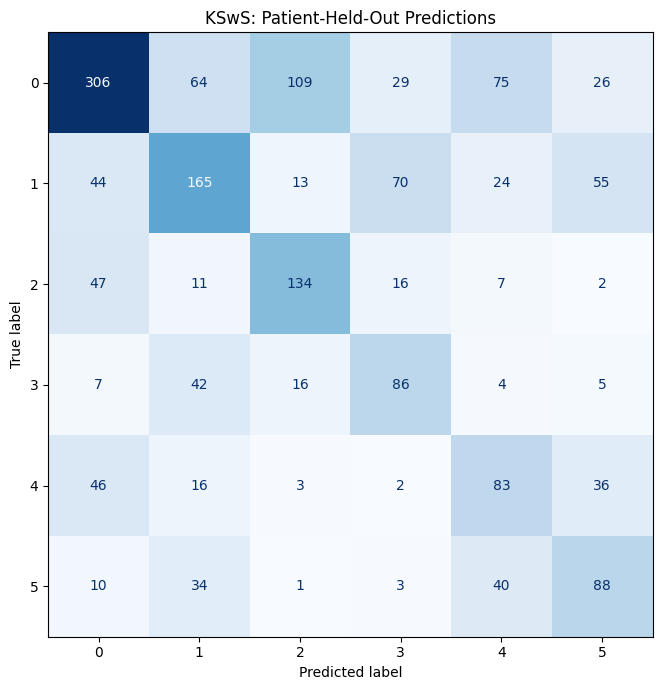

Rows = actual labels; columns = predicted labels.


In [38]:

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

classes = sorted(oof_predictions["y_true"].unique())

print("=== CLASSIFICATION REPORT ===")
print(classification_report(
    oof_predictions["y_true"],
    oof_predictions["model_prediction"],
    labels=classes,
    zero_division=0,
    digits=3
))

cm = confusion_matrix(
    oof_predictions["y_true"],
    oof_predictions["model_prediction"],
    labels=classes
)

fig, ax = plt.subplots(figsize=(8, 7))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("KSwS: Patient-Held-Out Predictions")
plt.tight_layout()
plt.show()

print("Rows = actual labels; columns = predicted labels.")

35

In [39]:

duplicate_mask = data.duplicated(ID_COLS, keep=False)
sensitivity_data = data.loc[~duplicate_mask].copy()

print("=== DUPLICATE-RECORD SENSITIVITY ANALYSIS ===")
print("Original records:", len(data))
print("Records flagged by repeated identifiers:", int(duplicate_mask.sum()))
print("Records in sensitivity dataset:", len(sensitivity_data))
print("Patients in sensitivity dataset:",
      sensitivity_data["Patient ID"].nunique())

sensitivity_metrics, sensitivity_fold_metrics, sensitivity_predictions = (
    evaluate_cv(sensitivity_data, wave_cols, TARGET)
)

comparison = overall_metrics.merge(
    sensitivity_metrics,
    on="model",
    suffixes=("_all_records", "_excluding_repeated_keys")
)

print("\n=== METRIC COMPARISON ===")
print(comparison.round(4).to_string(index=False))

print("\nInterpretation:")
print(
    "Compare accuracy, balanced accuracy and macro-F1 across both runs. "
    "This sensitivity analysis does not determine which repeated record is correct."
)

=== DUPLICATE-RECORD SENSITIVITY ANALYSIS ===
Original records: 1719
Records flagged by repeated identifiers: 4
Records in sensitivity dataset: 1715
Patients in sensitivity dataset: 356

=== METRIC COMPARISON ===
                             model  accuracy_all_records  balanced_accuracy_all_records  macro_f1_all_records  accuracy_excluding_repeated_keys  balanced_accuracy_excluding_repeated_keys  macro_f1_excluding_repeated_keys
           Majority-class baseline                0.3543                         0.1667                0.0872                            0.3545                                     0.1667                            0.0872
Class-weighted logistic regression                0.5015                         0.5081                0.4842                            0.4968                                     0.5033                            0.4795

Interpretation:
Compare accuracy, balanced accuracy and macro-F1 across both runs. This sensitivity analysis does not deter

36

In [40]:

# Save outputs from the primary experiment.
overall_path = RESULTS / "kwsw_overall_metrics.csv"
fold_path = RESULTS / "kwsw_fold_metrics.csv"
pred_path = RESULTS / "kwsw_oof_predictions.csv"
sensitivity_path = RESULTS / "kwsw_duplicate_sensitivity.csv"
sensitivity_folds_path = RESULTS / "kwsw_duplicate_sensitivity_folds.csv"

overall_metrics.to_csv(overall_path, index=False)
fold_metrics.to_csv(fold_path, index=False)
oof_predictions.to_csv(pred_path, index=False)
sensitivity_metrics.to_csv(sensitivity_path, index=False)
sensitivity_fold_metrics.to_csv(sensitivity_folds_path, index=False)

print("Saved results:")
for path in [
    overall_path,
    fold_path,
    pred_path,
    sensitivity_path,
    sensitivity_folds_path
]:
    print(path)

print("\nExperiment summary")
print(f"- Target: {TARGET}")
print(f"- Patients: {data['Patient ID'].nunique()}")
print(f"- Records: {len(data)}")
print(f"- Input waveform features: {len(wave_cols)}")
print("- Evaluation: 10 provided patient-separated folds")
print("- Preprocessing: fitted on each training fold only")
print("- Main models: majority baseline and class-weighted logistic regression")
print("- Separate duplicate-record sensitivity analysis: completed")

Saved results:
/content/drive/MyDrive/Pediatric_GaitProject/results/kwsw_overall_metrics.csv
/content/drive/MyDrive/Pediatric_GaitProject/results/kwsw_fold_metrics.csv
/content/drive/MyDrive/Pediatric_GaitProject/results/kwsw_oof_predictions.csv
/content/drive/MyDrive/Pediatric_GaitProject/results/kwsw_duplicate_sensitivity.csv
/content/drive/MyDrive/Pediatric_GaitProject/results/kwsw_duplicate_sensitivity_folds.csv

Experiment summary
- Target: KSwS
- Patients: 356
- Records: 1719
- Input waveform features: 561
- Evaluation: 10 provided patient-separated folds
- Preprocessing: fitted on each training fold only
- Main models: majority baseline and class-weighted logistic regression
- Separate duplicate-record sensitivity analysis: completed


37

In [41]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import numpy as np
import pandas as pd

# Use the prepared `data`, `wave_cols`, and TARGET from Cell 32.
X_all = data[wave_cols].apply(pd.to_numeric, errors="raise")
y_all = data[TARGET].astype(int)
fold_ids = data["_fold"].astype(int).to_numpy()

models = {
    "Logistic regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", __import__("sklearn.linear_model").linear_model.LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            C=0.5,
            random_state=42
        ))
    ]),
    "Linear SVM": Pipeline([
        ("scale", StandardScaler()),
        ("model", LinearSVC(
            class_weight="balanced",
            C=0.1,
            max_iter=10000,
            random_state=42
        ))
    ]),
    "Random forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    )
}

comparison_rows = []
model_oof = {}

for name, estimator in models.items():
    preds = np.full(len(data), -1, dtype=int)

    for fold_num in sorted(np.unique(fold_ids)):
        train_mask = fold_ids != fold_num
        test_mask = fold_ids == fold_num

        # Assert patient separation before fitting.
        train_patients = set(data.loc[train_mask, "Patient ID"])
        test_patients = set(data.loc[test_mask, "Patient ID"])
        assert train_patients.isdisjoint(test_patients)

        fitted = clone(estimator)
        fitted.fit(X_all.loc[train_mask], y_all.loc[train_mask])
        preds[test_mask] = fitted.predict(X_all.loc[test_mask])

    model_oof[name] = preds

    comparison_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_all, preds),
        "balanced_accuracy": balanced_accuracy_score(y_all, preds),
        "macro_f1": f1_score(y_all, preds, average="macro", zero_division=0)
    })

# Add the previously computed logistic regression result for consistency.
model_comparison = pd.DataFrame(comparison_rows).sort_values(
    "macro_f1", ascending=False
)

print("=== OUT-OF-FOLD MODEL COMPARISON ===")
print(model_comparison.round(4).to_string(index=False))

model_comparison.to_csv(
    RESULTS / "kwsw_model_comparison.csv", index=False
)

pd.DataFrame({
    "Patient ID": data["Patient ID"],
    "_fold": fold_ids,
    "actual": y_all,
    **{f"pred_{name.lower().replace(' ', '_')}": pred
       for name, pred in model_oof.items()}
}).to_csv(RESULTS / "kwsw_model_comparison_predictions.csv", index=False)

print("\nSaved model comparison and out-of-fold predictions.")

=== OUT-OF-FOLD MODEL COMPARISON ===
              model  accuracy  balanced_accuracy  macro_f1
Logistic regression    0.5015             0.5081    0.4842
         Linear SVM    0.4729             0.4568    0.4426
      Random forest    0.5067             0.3932    0.4104

Saved model comparison and out-of-fold predictions.


38

In [42]:

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np

fold_rows = []

for name, preds in model_oof.items():
    for fold_num in sorted(np.unique(fold_ids)):
        mask = fold_ids == fold_num
        fold_rows.append({
            "model": name,
            "fold": int(fold_num),
            "accuracy": accuracy_score(y_all[mask], preds[mask]),
            "balanced_accuracy": balanced_accuracy_score(
                y_all[mask], preds[mask]
            ),
            "macro_f1": f1_score(
                y_all[mask], preds[mask],
                average="macro", zero_division=0
            )
        })

fold_comparison = pd.DataFrame(fold_rows)

print("=== MEAN AND STANDARD DEVIATION ACROSS FOLDS ===")
print(
    fold_comparison.groupby("model")[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].agg(["mean", "std"]).round(4).to_string()
)

best_name = model_comparison.iloc[0]["model"]
best_preds = model_oof[best_name]

print(f"\n=== CLASS REPORT: {best_name} ===")
print(classification_report(
    y_all, best_preds, zero_division=0, digits=3
))

print("\n=== CONFUSION MATRIX ===")
print(confusion_matrix(y_all, best_preds))

fold_comparison.to_csv(
    RESULTS / "kwsw_model_fold_comparison.csv", index=False
)

print("\nResults saved in:", RESULTS)

=== MEAN AND STANDARD DEVIATION ACROSS FOLDS ===
                    accuracy         balanced_accuracy         macro_f1        
                        mean     std              mean     std     mean     std
model                                                                          
Linear SVM            0.4732  0.0455            0.4524  0.0690   0.4277  0.0616
Logistic regression   0.5017  0.0463            0.4981  0.0686   0.4649  0.0570
Random forest         0.5056  0.0519            0.4018  0.0636   0.4024  0.0621

=== CLASS REPORT: Logistic regression ===
              precision    recall  f1-score   support

           0      0.665     0.502     0.572       609
           1      0.497     0.445     0.469       371
           2      0.486     0.618     0.544       217
           3      0.417     0.537     0.470       160
           4      0.356     0.446     0.396       186
           5      0.415     0.500     0.454       176

    accuracy                          0.501     

41

In [43]:

import re
import numpy as np
import pandas as pd
import torch
from pathlib import Path

# Reuse variables from earlier cells.
assert "data" in globals(), "Run the earlier data-preparation cell first."
assert "TARGET" in globals(), "TARGET variable is missing."
assert "_fold" in data.columns, "Fold assignments are missing."
assert "Patient ID" in data.columns, "Patient IDs are required."

RESULTS = Path(
    "/content/drive/MyDrive/Pediatric_GaitProject/results"
)
RESULTS.mkdir(parents=True, exist_ok=True)

# Extract family and gait-cycle position, including the continuous
# 90% ankle column ending in '_900_cont'.
pattern = re.compile(r"^(.*)_pct_GC_(\d+)(?:_cont)?$")
families = {}

for col in wave_cols:
    match = pattern.match(str(col))
    if match:
        family, point = match.groups()
        families.setdefault(family, []).append((int(point), col))

# Keep only complete 51-point families.
complete_families = {}
for family, pairs in families.items():
    pairs = sorted(pairs)
    point_numbers = [p for p, _ in pairs]
    if len(pairs) == 51 and point_numbers == list(range(0, 1001, 20)):
        complete_families[family] = [col for _, col in pairs]

print("Complete waveform families:", len(complete_families))
for family, cols in sorted(complete_families.items()):
    print(f"  {family}: {len(cols)} points")

if not complete_families:
    raise ValueError(
        "No complete 51-point waveform families found. "
        "Inspect the waveform column names before continuing."
    )

# Tensor layout: samples × channels × gait-cycle time points.
family_names = sorted(complete_families)
X = np.stack([
    data[complete_families[f]].apply(
        pd.to_numeric, errors="raise"
    ).to_numpy(dtype=np.float32)
    for f in family_names
], axis=1)

y = data[TARGET].astype(int).to_numpy()
folds = data["_fold"].astype(int).to_numpy()
patients = data["Patient ID"].to_numpy()

assert np.isfinite(X).all(), "Non-finite values found in the curves."
assert set(np.unique(y)).issubset(set(range(6))), (
    "Expected KSwS labels 0–5."
)

print("\nTensor shape (samples, channels, time):", X.shape)
print("Labels:", np.unique(y))
print("Folds:", sorted(np.unique(folds)))
print("Device available:", "CUDA" if torch.cuda.is_available() else "CPU")
print("Families used:", family_names)

Complete waveform families: 11
  aCorH: 51 points
  aCorP: 51 points
  aSagA: 51 points
  aSagH: 51 points
  aSagP: 51 points
  aTransvF: 51 points
  aTransvH: 51 points
  aTransvP: 51 points
  avSagA: 51 points
  avSagH: 51 points
  avSagP: 51 points

Tensor shape (samples, channels, time): (1719, 11, 51)
Labels: [0 1 2 3 4 5]
Folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Device available: CUDA
Families used: ['aCorH', 'aCorP', 'aSagA', 'aSagH', 'aSagP', 'aTransvF', 'aTransvH', 'aTransvP', 'avSagA', 'avSagH', 'avSagP']


42

In [44]:

import copy
import time
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_fold = 10

# Fold 10 is the pilot test set.
test_idx = np.where(folds == test_fold)[0]
remaining_idx = np.where(folds != test_fold)[0]

# Split by patient, never by individual records.
remaining_patients = patients[remaining_idx]
unique_patients = np.unique(remaining_patients)

train_patients, val_patients = train_test_split(
    unique_patients,
    test_size=0.15,
    random_state=42
)

train_idx = remaining_idx[np.isin(remaining_patients, train_patients)]
val_idx = remaining_idx[np.isin(remaining_patients, val_patients)]

assert set(patients[train_idx]).isdisjoint(set(patients[val_idx]))
assert set(patients[train_idx]).isdisjoint(set(patients[test_idx]))
assert set(patients[val_idx]).isdisjoint(set(patients[test_idx]))

# Normalize each channel using training data only.
channel_mean = X[train_idx].mean(axis=(0, 2), keepdims=True)
channel_std = X[train_idx].std(axis=(0, 2), keepdims=True)
channel_std[channel_std < 1e-6] = 1.0

X_scaled = (X - channel_mean) / channel_std
X_scaled = np.clip(X_scaled, -10, 10).astype(np.float32)

def make_loader(indices, shuffle=False):
    dataset = TensorDataset(
        torch.from_numpy(X_scaled[indices]),
        torch.from_numpy(y[indices]).long()
    )
    return DataLoader(
        dataset,
        batch_size=64,
        shuffle=shuffle,
        num_workers=0
    )

train_loader = make_loader(train_idx, shuffle=True)
val_loader = make_loader(val_idx)
test_loader = make_loader(test_idx)

class GaitCNN(nn.Module):
    def __init__(self, n_channels, n_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(n_channels, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.25),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = GaitCNN(X.shape[1]).to(device)

classes = np.arange(6)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y[train_idx]
)
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(weights, dtype=torch.float32, device=device)
)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-3, weight_decay=1e-3
)

def evaluate_loss(loader):
    model.eval()
    total_loss, total_n = 0.0, 0
    all_true, all_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * len(yb)
            total_n += len(yb)
            all_true.extend(yb.cpu().numpy())
            all_pred.extend(logits.argmax(1).cpu().numpy())
    return (
        total_loss / max(total_n, 1),
        np.array(all_true),
        np.array(all_pred)
    )

best_state = None
best_val_loss = float("inf")
patience, wait = 4, 0
start = time.time()

for epoch in range(1, 16):
    model.train()
    running_loss, n_seen = 0.0, 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(yb)
        n_seen += len(yb)

    val_loss, _, _ = evaluate_loss(val_loader)
    print(
        f"Epoch {epoch:02d}/15 | "
        f"train loss={running_loss/max(n_seen,1):.4f} | "
        f"validation loss={val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping.")
            break

if best_state is None:
    raise RuntimeError("No model checkpoint was produced.")

model.load_state_dict(best_state)
test_loss, y_true, y_pred = evaluate_loss(test_loader)

print("\n=== FOLD 10 PILOT TEST RESULTS ===")
print("Test records:", len(test_idx))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_true, y_pred), 4))
print("Macro F1:", round(f1_score(y_true, y_pred, average="macro",
                                   zero_division=0), 4))
print("Elapsed minutes:", round((time.time() - start) / 60, 2))

# Save the pilot artifact and metadata for reproducibility.
torch.save({
    "model_state_dict": model.state_dict(),
    "n_channels": X.shape[1],
    "family_names": family_names,
    "time_points": 51,
    "target": TARGET,
    "test_fold": test_fold,
    "channel_mean": channel_mean,
    "channel_std": channel_std,
    "best_validation_loss": best_val_loss
}, RESULTS / "kwsw_temporal_cnn_pilot.pth")

pd.DataFrame({
    "Patient_ID": patients[test_idx],
    "fold": folds[test_idx],
    "actual": y_true,
    "predicted": y_pred
}).to_csv(RESULTS / "kwsw_temporal_cnn_pilot_predictions.csv",
          index=False)

print("Pilot model and predictions saved.")

Epoch 01/15 | train loss=1.7465 | validation loss=1.7217
Epoch 02/15 | train loss=1.6297 | validation loss=1.6057
Epoch 03/15 | train loss=1.5168 | validation loss=1.4568
Epoch 04/15 | train loss=1.4109 | validation loss=1.4090
Epoch 05/15 | train loss=1.3487 | validation loss=1.3890
Epoch 06/15 | train loss=1.2860 | validation loss=1.3489
Epoch 07/15 | train loss=1.2569 | validation loss=1.2777
Epoch 08/15 | train loss=1.2547 | validation loss=1.3851
Epoch 09/15 | train loss=1.1989 | validation loss=1.2835
Epoch 10/15 | train loss=1.1805 | validation loss=1.2882
Epoch 11/15 | train loss=1.1679 | validation loss=1.2688
Epoch 12/15 | train loss=1.1350 | validation loss=1.2845
Epoch 13/15 | train loss=1.1284 | validation loss=1.2599
Epoch 14/15 | train loss=1.1105 | validation loss=1.2478
Epoch 15/15 | train loss=1.1012 | validation loss=1.1836

=== FOLD 10 PILOT TEST RESULTS ===
Test records: 165
Accuracy: 0.497
Balanced accuracy: 0.5552
Macro F1: 0.4961
Elapsed minutes: 0.03
Pilot mode

43

In [45]:

from pathlib import Path
import pandas as pd
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

pred_path = RESULTS / "kwsw_model_comparison_predictions.csv"
cnn_path = RESULTS / "kwsw_temporal_cnn_pilot_predictions.csv"

if not pred_path.exists() or not cnn_path.exists():
    print("Required prediction files are missing; run Cells 37 and 42 first.")
else:
    old = pd.read_csv(pred_path)
    cnn = pd.read_csv(cnn_path)

    pred_col = "pred_logistic_regression"
    if pred_col not in old.columns:
        print("Could not find logistic regression predictions.")
        print("Available columns:", old.columns.tolist())
    else:
        old_test = old[old["_fold"] == 10].copy()
        y_base = old_test["actual"].astype(int)
        p_base = old_test[pred_col].astype(int)

        y_cnn = cnn["actual"].astype(int)
        p_cnn = cnn["predicted"].astype(int)

        comparison = pd.DataFrame([
            {
                "model": "Logistic regression",
                "accuracy": accuracy_score(y_base, p_base),
                "balanced_accuracy": balanced_accuracy_score(y_base, p_base),
                "macro_f1": f1_score(y_base, p_base, average="macro",
                                     zero_division=0)
            },
            {
                "model": "Temporal CNN pilot",
                "accuracy": accuracy_score(y_cnn, p_cnn),
                "balanced_accuracy": balanced_accuracy_score(y_cnn, p_cnn),
                "macro_f1": f1_score(y_cnn, p_cnn, average="macro",
                                     zero_division=0)
            }
        ])

        print(comparison.round(4).to_string(index=False))
        print(
            "\nNote: this is a single-fold pilot comparison, "
            "not a final ten-fold model comparison."
        )

              model  accuracy  balanced_accuracy  macro_f1
Logistic regression    0.5333             0.5913    0.5332
 Temporal CNN pilot    0.4970             0.5552    0.4961

Note: this is a single-fold pilot comparison, not a final ten-fold model comparison.


44

In [46]:

import re

print("=== WAVEFORM FAMILY COVERAGE ===")
for prefix in [
    "aSagP", "aCorP", "aTransvP",
    "aSagH", "aCorH", "aTransvH",
    "aSagK", "avSagK",
    "aSagA", "avSagA",
    "avSagH", "avSagP", "aTransvF"
]:
    cols = [
        c for c in data.columns
        if re.match(rf"^{re.escape(prefix)}_pct_GC_\d+$", str(c))
    ]
    print(f"{prefix}: {len(cols)} columns")

print("\nCurrent CNN input families:", family_names)
print("Current CNN input shape:", X.shape)
print("Fold sizes:", {
    int(f): int((folds == f).sum()) for f in sorted(set(folds))
})

=== WAVEFORM FAMILY COVERAGE ===
aSagP: 51 columns
aCorP: 51 columns
aTransvP: 51 columns
aSagH: 51 columns
aCorH: 51 columns
aTransvH: 51 columns
aSagK: 51 columns
avSagK: 51 columns
aSagA: 50 columns
avSagA: 51 columns
avSagH: 51 columns
avSagP: 51 columns
aTransvF: 51 columns

Current CNN input families: ['aCorH', 'aCorP', 'aSagA', 'aSagH', 'aSagP', 'aTransvF', 'aTransvH', 'aTransvP', 'avSagA', 'avSagH', 'avSagP']
Current CNN input shape: (1719, 11, 51)
Fold sizes: {1: 166, 2: 175, 3: 165, 4: 177, 5: 178, 6: 167, 7: 166, 8: 186, 9: 174, 10: 165}


45

In [47]:
# CELL 45 — Rebuild clean, complete waveform tensors

import re
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder

EXPECTED_POINTS = list(range(0, 1001, 20))

# Keep only families with all 51 waveform points.
CANDIDATE_FAMILIES = [
    "aCorH", "aCorP",
    "aSagH", "aSagP", "aSagK",
    "aTransvF", "aTransvH", "aTransvP",
    "avSagH", "avSagP", "avSagK", "avSagA"
]

family_point_cols = {}

for family in CANDIDATE_FAMILIES:
    point_map = {}

    for col in data.columns:
        match = re.fullmatch(
            rf"{re.escape(family)}_pct_GC_(\d+)(_cont)?",
            str(col)
        )
        if match:
            point = int(match.group(1))
            is_cont = match.group(2) is not None

            if point in EXPECTED_POINTS:
                # Prefer the non-cont column if both versions exist.
                if point not in point_map or (
                    str(point_map[point]).endswith("_cont")
                    and not is_cont
                ):
                    point_map[point] = col

    missing_points = sorted(set(EXPECTED_POINTS) - set(point_map))
    if not missing_points:
        family_point_cols[family] = [
            point_map[p] for p in EXPECTED_POINTS
        ]
    else:
        print(
            f"Excluding {family}: {len(missing_points)} points missing; "
            f"first missing points = {missing_points[:8]}"
        )

family_names = list(family_point_cols.keys())

if not family_names:
    raise ValueError("No complete waveform families were found.")

# Numeric tensor: samples × waveform families × time points
X = np.stack([
    data[family_point_cols[f]].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=np.float32)
    for f in family_names
], axis=1)

if not np.isfinite(X).all():
    raise ValueError(
        "Non-finite waveform values found. Inspect missing values before training."
    )

# Encode the six KSwS classes consistently.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(data[TARGET].to_numpy()).astype(np.int64)

folds = data["_fold"].to_numpy(dtype=np.int64)
patients = data["Patient ID"].astype(str).to_numpy()

assert len(X) == len(y) == len(folds) == len(patients)

print("Input tensor:", X.shape)
print("Complete waveform families:", family_names)
print("Target classes:", list(label_encoder.classes_))
print("Class counts:", pd.Series(y).value_counts().sort_index().to_dict())
print("Fold sizes:", pd.Series(folds).value_counts().sort_index().to_dict())
print("Non-finite values:", int((~np.isfinite(X)).sum()))

Input tensor: (1719, 12, 51)
Complete waveform families: ['aCorH', 'aCorP', 'aSagH', 'aSagP', 'aSagK', 'aTransvF', 'aTransvH', 'aTransvP', 'avSagH', 'avSagP', 'avSagK', 'avSagA']
Target classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Class counts: {0: 609, 1: 371, 2: 217, 3: 160, 4: 186, 5: 176}
Fold sizes: {1: 166, 2: 175, 3: 165, 4: 177, 5: 178, 6: 167, 7: 166, 8: 186, 9: 174, 10: 165}
Non-finite values: 0


46

In [48]:
# CELL 46 — Ten-fold temporal CNN evaluation

import copy
import random
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
EPOCHS = 18
PATIENCE = 4
BATCH_SIZE = 64

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class TemporalCNN(nn.Module):
    def __init__(self, in_channels, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(in_channels, 32, kernel_size=5, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

all_classes = np.arange(len(label_encoder.classes_))
oof_pred = np.full(len(y), -1, dtype=np.int64)
oof_prob = np.full((len(y), len(all_classes)), np.nan, dtype=np.float32)
fold_results = []
fold_models = {}
start_time = time.time()

for heldout_fold in sorted(np.unique(folds)):
    print(f"\n--- Held-out fold {heldout_fold} ---")

    test_idx = np.where(folds == heldout_fold)[0]
    remaining_idx = np.where(folds != heldout_fold)[0]

    # Validation split is by patient, never by individual waveform row.
    splitter = GroupShuffleSplit(
        n_splits=1, test_size=0.12, random_state=SEED + int(heldout_fold)
    )

    tr_rel, va_rel = next(splitter.split(
        remaining_idx,
        y[remaining_idx],
        groups=patients[remaining_idx]
    ))

    train_idx = remaining_idx[tr_rel]
    val_idx = remaining_idx[va_rel]

    train_patients = set(patients[train_idx])
    val_patients = set(patients[val_idx])
    test_patients = set(patients[test_idx])

    assert train_patients.isdisjoint(val_patients)
    assert train_patients.isdisjoint(test_patients)
    assert val_patients.isdisjoint(test_patients)

    # Normalize each channel using training samples and time points only.
    channel_mean = X[train_idx].mean(axis=(0, 2), keepdims=True)
    channel_std = X[train_idx].std(axis=(0, 2), keepdims=True)
    channel_std = np.where(channel_std < 1e-6, 1.0, channel_std)

    X_norm = ((X - channel_mean) / channel_std).astype(np.float32)

    def make_loader(indices, shuffle=False):
        features = torch.from_numpy(X_norm[indices])
        labels = torch.from_numpy(y[indices])
        return DataLoader(
            TensorDataset(features, labels),
            batch_size=BATCH_SIZE,
            shuffle=shuffle,
            num_workers=0
        )

    train_loader = make_loader(train_idx, shuffle=True)
    val_loader = make_loader(val_idx)
    test_loader = make_loader(test_idx)

    # Balanced loss helps account for the uneven class distribution.
    class_counts = np.bincount(y[train_idx], minlength=len(all_classes))
    class_weights = len(train_idx) / (
        len(all_classes) * np.maximum(class_counts, 1)
    )

    model = TemporalCNN(
        in_channels=X.shape[1],
        n_classes=len(all_classes)
    ).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(
            class_weights, dtype=torch.float32, device=device
        )
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=1e-3, weight_decay=1e-4
    )

    best_val_loss = float("inf")
    best_state = None
    patience_left = PATIENCE
    best_epoch = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss_sum = 0.0
        train_n = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(yb)
            train_n += len(yb)

        model.eval()
        val_loss_sum = 0.0
        val_n = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                val_loss_sum += loss.item() * len(yb)
                val_n += len(yb)

        val_loss = val_loss_sum / max(val_n, 1)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            patience_left = PATIENCE
        else:
            patience_left -= 1

        if patience_left <= 0:
            break

    model.load_state_dict(best_state)
    model.eval()

    fold_pred, fold_prob = [], []

    with torch.no_grad():
        for xb, _ in test_loader:
            logits = model(xb.to(device))
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            fold_prob.append(probs)
            fold_pred.append(probs.argmax(axis=1))

    fold_pred = np.concatenate(fold_pred)
    fold_prob = np.concatenate(fold_prob)

    oof_pred[test_idx] = fold_pred
    oof_prob[test_idx] = fold_prob
    fold_models[int(heldout_fold)] = copy.deepcopy(best_state)

    metrics = {
        "fold": int(heldout_fold),
        "n_test": len(test_idx),
        "n_test_patients": len(test_patients),
        "best_epoch": best_epoch,
        "accuracy": accuracy_score(y[test_idx], fold_pred),
        "balanced_accuracy": balanced_accuracy_score(y[test_idx], fold_pred),
        "macro_f1": f1_score(
            y[test_idx], fold_pred,
            labels=all_classes, average="macro", zero_division=0
        )
    }
    fold_results.append(metrics)

    print(
        f"Best epoch={best_epoch} | "
        f"accuracy={metrics['accuracy']:.3f} | "
        f"balanced accuracy={metrics['balanced_accuracy']:.3f} | "
        f"macro-F1={metrics['macro_f1']:.3f}"
    )

    del model, optimizer, criterion
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"\nTotal evaluation time: {(time.time()-start_time)/60:.2f} minutes")

Device: cuda

--- Held-out fold 1 ---
Best epoch=9 | accuracy=0.554 | balanced accuracy=0.598 | macro-F1=0.520

--- Held-out fold 2 ---
Best epoch=10 | accuracy=0.617 | balanced accuracy=0.661 | macro-F1=0.611

--- Held-out fold 3 ---
Best epoch=4 | accuracy=0.473 | balanced accuracy=0.490 | macro-F1=0.452

--- Held-out fold 4 ---
Best epoch=17 | accuracy=0.661 | balanced accuracy=0.726 | macro-F1=0.656

--- Held-out fold 5 ---
Best epoch=9 | accuracy=0.579 | balanced accuracy=0.529 | macro-F1=0.519

--- Held-out fold 6 ---
Best epoch=11 | accuracy=0.587 | balanced accuracy=0.525 | macro-F1=0.525

--- Held-out fold 7 ---
Best epoch=18 | accuracy=0.639 | balanced accuracy=0.686 | macro-F1=0.640

--- Held-out fold 8 ---
Best epoch=10 | accuracy=0.565 | balanced accuracy=0.624 | macro-F1=0.534

--- Held-out fold 9 ---
Best epoch=16 | accuracy=0.649 | balanced accuracy=0.671 | macro-F1=0.630

--- Held-out fold 10 ---
Best epoch=13 | accuracy=0.661 | balanced accuracy=0.675 | macro-F1=0.645

47

In [49]:
# CELL 47 — Summarize the ten-fold CNN results

from IPython.display import display

fold_results_df = pd.DataFrame(fold_results)

valid = oof_pred >= 0
overall = {
    "n_samples": int(valid.sum()),
    "accuracy": accuracy_score(y[valid], oof_pred[valid]),
    "balanced_accuracy": balanced_accuracy_score(y[valid], oof_pred[valid]),
    "macro_f1": f1_score(
        y[valid], oof_pred[valid],
        labels=all_classes, average="macro", zero_division=0
    )
}

print("=== OVERALL OUT-OF-FOLD RESULTS ===")
display(pd.DataFrame([overall]).round(4))

print("=== RESULTS BY HELD-OUT FOLD ===")
display(fold_results_df.round(4))

print("=== CLASSIFICATION REPORT ===")
print(classification_report(
    y[valid],
    oof_pred[valid],
    labels=all_classes,
    target_names=[str(c) for c in label_encoder.classes_],
    zero_division=0
))

print("=== CONFUSION MATRIX ===")
display(pd.DataFrame(
    confusion_matrix(y[valid], oof_pred[valid], labels=all_classes),
    index=[f"Actual {c}" for c in label_encoder.classes_],
    columns=[f"Pred {c}" for c in label_encoder.classes_]
))

# Save results
RESULTS.mkdir(parents=True, exist_ok=True)

predictions_df = pd.DataFrame({
    "row_index": np.arange(len(y)),
    "patient_id": patients,
    "fold": folds,
    "actual_encoded": y,
    "predicted_encoded": oof_pred,
    "actual_label": label_encoder.inverse_transform(y),
    "predicted_label": [
        label_encoder.classes_[p] if p >= 0 else None
        for p in oof_pred
    ]
})

for class_idx, class_label in enumerate(label_encoder.classes_):
    predictions_df[f"prob_class_{class_label}"] = oof_prob[:, class_idx]

predictions_path = RESULTS / "temporal_cnn_10fold_oof_predictions.csv"
metrics_path = RESULTS / "temporal_cnn_10fold_metrics.csv"

predictions_df.to_csv(predictions_path, index=False)
fold_results_df.to_csv(metrics_path, index=False)

print("Saved predictions:", predictions_path)
print("Saved fold metrics:", metrics_path)

=== OVERALL OUT-OF-FOLD RESULTS ===


,n_samples,accuracy,balanced_accuracy,macro_f1
0,1719,0.5986,0.6274,0.5889


=== RESULTS BY HELD-OUT FOLD ===


,fold,n_test,n_test_patients,best_epoch,accuracy,balanced_accuracy,macro_f1
0,1,166,35,9,0.5542,0.5979,0.5201
1,2,175,35,10,0.6171,0.6609,0.6109
2,3,165,36,4,0.4727,0.4900,0.4517
3,4,177,37,17,0.6610,0.7256,0.6561
4,5,178,35,9,0.5787,0.5289,0.5189
5,6,167,34,11,0.5868,0.5247,0.5249
6,7,166,38,18,0.6386,0.6859,0.6403
7,8,186,36,10,0.5645,0.6237,0.5336
8,9,174,36,16,0.6494,0.6714,0.6300
9,10,165,34,13,0.6606,0.6748,0.6454


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.77      0.56      0.65       609
           1       0.61      0.50      0.55       371
           2       0.56      0.79      0.66       217
           3       0.53      0.70      0.60       160
           4       0.48      0.62      0.54       186
           5       0.49      0.59      0.54       176

    accuracy                           0.60      1719
   macro avg       0.57      0.63      0.59      1719
weighted avg       0.63      0.60      0.60      1719

=== CONFUSION MATRIX ===


,Pred 0,Pred 1,Pred 2,Pred 3,Pred 4,Pred 5
Actual 0,340,67,94,15,75,18
Actual 1,57,185,14,63,13,39
Actual 2,15,5,172,21,3,1
Actual 3,5,18,23,112,0,2
Actual 4,15,4,3,0,116,48
Actual 5,12,25,1,0,34,104


Saved predictions: /content/drive/MyDrive/Pediatric_GaitProject/results/temporal_cnn_10fold_oof_predictions.csv
Saved fold metrics: /content/drive/MyDrive/Pediatric_GaitProject/results/temporal_cnn_10fold_metrics.csv


In [50]:
# CELL 48 — Same-input logistic regression baseline

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Flatten each waveform family and time point into tabular features.
X_flat = X.reshape(len(X), -1)
lr_oof_pred = np.full(len(y), -1, dtype=np.int64)

for heldout_fold in sorted(np.unique(folds)):
    test_idx = np.where(folds == heldout_fold)[0]
    remaining_idx = np.where(folds != heldout_fold)[0]

    # Use the same patient-wise train/validation split convention.
    splitter = GroupShuffleSplit(
        n_splits=1, test_size=0.12, random_state=SEED + int(heldout_fold)
    )
    tr_rel, _ = next(splitter.split(
        remaining_idx,
        y[remaining_idx],
        groups=patients[remaining_idx]
    ))
    train_idx = remaining_idx[tr_rel]

    lr = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=SEED
        )
    )
    lr.fit(X_flat[train_idx], y[train_idx])
    lr_oof_pred[test_idx] = lr.predict(X_flat[test_idx])

lr_valid = lr_oof_pred >= 0

comparison_df = pd.DataFrame([
    {
        "model": "Temporal CNN",
        "accuracy": accuracy_score(y[valid], oof_pred[valid]),
        "balanced_accuracy": balanced_accuracy_score(y[valid], oof_pred[valid]),
        "macro_f1": f1_score(
            y[valid], oof_pred[valid],
            labels=all_classes, average="macro", zero_division=0
        )
    },
    {
        "model": "Logistic regression",
        "accuracy": accuracy_score(y[lr_valid], lr_oof_pred[lr_valid]),
        "balanced_accuracy": balanced_accuracy_score(
            y[lr_valid], lr_oof_pred[lr_valid]
        ),
        "macro_f1": f1_score(
            y[lr_valid], lr_oof_pred[lr_valid],
            labels=all_classes, average="macro", zero_division=0
        )
    }
])

display(comparison_df.round(4))

comparison_path = RESULTS / "temporal_cnn_vs_logistic_regression.csv"
comparison_df.to_csv(comparison_path, index=False)
print("Saved comparison:", comparison_path)

,model,accuracy,balanced_accuracy,macro_f1
0,Temporal CNN,0.5986,0.6274,0.5889
1,Logistic regression,0.5538,0.5486,0.5302


Saved comparison: /content/drive/MyDrive/Pediatric_GaitProject/results/temporal_cnn_vs_logistic_regression.csv


49

In [51]:
# CELL 49 — Find possible duplicate gait-cycle records

import re
import pandas as pd

print("Columns potentially identifying a gait cycle:")
for col in data.columns:
    if re.search(
        r"patient|session|trial|cycle|side|limb|fold",
        str(col), re.IGNORECASE
    ):
        print(repr(col))

# Inspect duplicate identifier groups if these fields exist.
def find_column(patterns):
    for pattern in patterns:
        matches = [
            c for c in data.columns
            if re.search(pattern, str(c), re.IGNORECASE)
        ]
        if matches:
            return matches[0]
    return None

key_candidates = {
    "patient": [r"^Patient ID$", r"patient"],
    "session": [r"^session$", r"session"],
    "trial": [r"^trial$", r"trial"],
    "cycle": [r"^cycle$", r"cycle"],
    "side": [r"^side$", r"side", r"limb"]
}

key_cols = {k: find_column(v) for k, v in key_candidates.items()}
print("\nDetected identifier columns:", key_cols)

if all(key_cols.values()):
    duplicate_key_cols = list(key_cols.values())
    duplicate_mask = data.duplicated(
        subset=duplicate_key_cols, keep=False
    )
    print("Rows belonging to duplicate key groups:", int(duplicate_mask.sum()))

    display(
        data.loc[duplicate_mask, duplicate_key_cols + [TARGET, "_fold"]]
        .sort_values(duplicate_key_cols)
    )
else:
    print(
        "Some key columns were not detected automatically. "
        "Use the printed column names to specify the identifiers manually."
    )

Columns potentially identifying a gait cycle:
'Patient ID'
'Trial no.'
'cycle'
'side'
'_fold'

Detected identifier columns: {'patient': 'Patient ID', 'session': None, 'trial': 'Trial no.', 'cycle': 'cycle', 'side': 'side'}
Some key columns were not detected automatically. Use the printed column names to specify the identifiers manually.


50

In [52]:
# CELL 50 — Patient-cluster bootstrap for the CNN's OOF metrics

from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

rng = np.random.default_rng(42)
n_bootstrap = 2000

valid_idx = np.where(oof_pred >= 0)[0]
patient_ids = patients[valid_idx]
actual = y[valid_idx]
predicted = oof_pred[valid_idx]

unique_patients = np.unique(patient_ids)
patient_rows = {
    p: np.where(patient_ids == p)[0]
    for p in unique_patients
}

bootstrap_metrics = []

for b in range(n_bootstrap):
    sampled_patients = rng.choice(
        unique_patients, size=len(unique_patients), replace=True
    )

    # Repeated patient selections correctly repeat that patient's rows.
    sampled_rows = np.concatenate([
        patient_rows[p] for p in sampled_patients
    ])

    yt = actual[sampled_rows]
    yp = predicted[sampled_rows]

    bootstrap_metrics.append([
        accuracy_score(yt, yp),
        balanced_accuracy_score(yt, yp),
        f1_score(
            yt, yp,
            labels=np.arange(len(label_encoder.classes_)),
            average="macro",
            zero_division=0
        )
    ])

bootstrap_metrics = np.asarray(bootstrap_metrics)

point_estimates = [
    accuracy_score(actual, predicted),
    balanced_accuracy_score(actual, predicted),
    f1_score(
        actual, predicted,
        labels=np.arange(len(label_encoder.classes_)),
        average="macro",
        zero_division=0
    )
]

ci_df = pd.DataFrame({
    "metric": ["Accuracy", "Balanced accuracy", "Macro-F1"],
    "estimate": point_estimates,
    "95% CI lower": np.percentile(bootstrap_metrics, 2.5, axis=0),
    "95% CI upper": np.percentile(bootstrap_metrics, 97.5, axis=0)
})

display(ci_df.round(4))
ci_df.to_csv(RESULTS / "temporal_cnn_patient_bootstrap_ci.csv", index=False)

,metric,estimate,95% CI lower,95% CI upper
0,Accuracy,0.5986,0.5668,0.6298
1,Balanced accuracy,0.6274,0.5947,0.6589
2,Macro-F1,0.5889,0.5558,0.6194


51

In [53]:
# CELL 51 — Reproducible benchmark summary

summary = {
    "task": "KSwS six-class classification",
    "model": "Temporal CNN",
    "input_families": ", ".join(family_names),
    "n_samples": int(len(y)),
    "n_patients": int(pd.Series(patients).nunique()),
    "n_folds": int(pd.Series(folds).nunique()),
    "accuracy": float(accuracy_score(y, oof_pred)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y, oof_pred)
    ),
    "macro_f1": float(
        f1_score(
            y, oof_pred,
            labels=np.arange(len(label_encoder.classes_)),
            average="macro",
            zero_division=0
        )
    ),
    "comparison_lr_accuracy": 0.5538,
    "comparison_lr_balanced_accuracy": 0.5486,
    "comparison_lr_macro_f1": 0.5302,
    "note": (
        "Patient-separated ten-fold out-of-fold evaluation. "
        "Duplicate-record sensitivity and external validation remain necessary. "
        "This is a supervised classifier, not yet a validated digital twin "
        "or demonstrated physics-informed model."
    )
}

summary_df = pd.DataFrame([summary])
display(summary_df.T.rename(columns={0: "value"}))

summary_df.to_csv(
    RESULTS / "temporal_cnn_evaluation_summary.csv", index=False
)
print("Summary saved to:", RESULTS / "temporal_cnn_evaluation_summary.csv")

,value
task,KSwS six-class classification
model,Temporal CNN
input_families,"aCorH, aCorP, aSagH, aSagP, aSagK, aTransvF, a..."
n_samples,1719
n_patients,356
n_folds,10
accuracy,0.598604
balanced_accuracy,0.627356
macro_f1,0.588932
comparison_lr_accuracy,0.5538


Summary saved to: /content/drive/MyDrive/Pediatric_GaitProject/results/temporal_cnn_evaluation_summary.csv


52

In [54]:
# CELL 52 — Duplicate-key audit with the actual workbook column names

import pandas as pd
import re

print("=== SESSION / VISIT COLUMNS ===")
session_like_cols = [
    c for c in data.columns
    if re.search(r"session|visit|occasion|assessment|date", str(c), re.I)
]
print(session_like_cols if session_like_cols else "No session-like columns found")

print("\n=== DUPLICATE IDENTIFIER AUDIT ===")

key_cols = ["Patient ID", "Trial no.", "cycle", "side"]
missing_cols = [c for c in key_cols if c not in data.columns]

if missing_cols:
    raise KeyError(f"Missing identifier columns: {missing_cols}")

duplicate_mask = data.duplicated(subset=key_cols, keep=False)
duplicate_rows = data.loc[duplicate_mask].sort_values(key_cols)

print("Rows in possible duplicate groups:", len(duplicate_rows))
print("Number of possible duplicate key groups:",
      duplicate_rows.groupby(key_cols, dropna=False).ngroups)

if len(duplicate_rows):
    display(
        duplicate_rows[
            key_cols + [TARGET, "_fold"]
        ].reset_index(drop=True)
    )

    print("\n=== Are duplicate-key rows identical across waveform inputs? ===")

    for key, group in duplicate_rows.groupby(key_cols, dropna=False):
        idx = group.index.tolist()
        if len(idx) < 2:
            continue

        row_equal = []
        for i in range(1, len(idx)):
            row_equal.append(
                np.allclose(
                    X[idx[0]], X[idx[i]],
                    rtol=1e-5, atol=1e-6,
                    equal_nan=True
                )
            )

        print({
            "key": key,
            "row_indices": idx,
            "labels": data.loc[idx, TARGET].tolist(),
            "folds": data.loc[idx, "_fold"].tolist(),
            "waveforms_identical_to_first": row_equal
        })
else:
    print("No duplicate groups found for these identifiers.")

=== SESSION / VISIT COLUMNS ===
No session-like columns found

=== DUPLICATE IDENTIFIER AUDIT ===
Rows in possible duplicate groups: 144
Number of possible duplicate key groups: 69


,Patient ID,Trial no.,cycle,side,KSwS,_fold
0,6,7,1,RIGHT,4,10
1,6,7,1,RIGHT,0,10
2,26,6,1,LEFT,1,5
3,26,6,1,LEFT,0,5
4,26,6,1,LEFT,2,5
...,...,...,...,...,...,...
139,333,9,1,RIGHT,0,4
140,342,6,1,LEFT,4,2
141,342,6,1,LEFT,2,2
142,342,6,1,RIGHT,1,2



=== Are duplicate-key rows identical across waveform inputs? ===
{'key': (np.int64(6), np.int64(7), np.int64(1), 'RIGHT'), 'row_indices': [1555, 1564], 'labels': [4, 0], 'folds': [10, 10], 'waveforms_identical_to_first': [False]}
{'key': (np.int64(26), np.int64(6), np.int64(1), 'LEFT'), 'row_indices': [703, 709, 717], 'labels': [1, 0, 2], 'folds': [5, 5, 5], 'waveforms_identical_to_first': [False, False]}
{'key': (np.int64(26), np.int64(6), np.int64(1), 'RIGHT'), 'row_indices': [704, 710, 718], 'labels': [0, 0, 2], 'folds': [5, 5, 5], 'waveforms_identical_to_first': [False, False]}
{'key': (np.int64(26), np.int64(7), np.int64(1), 'LEFT'), 'row_indices': [711, 715], 'labels': [0, 0], 'folds': [5, 5], 'waveforms_identical_to_first': [False]}
{'key': (np.int64(26), np.int64(7), np.int64(1), 'RIGHT'), 'row_indices': [712, 716], 'labels': [0, 0], 'folds': [5, 5], 'waveforms_identical_to_first': [False]}
{'key': (np.int64(26), np.int64(10), np.int64(1), 'RIGHT'), 'row_indices': [691, 698], 

In [55]:
# CELL 53 — Exact waveform-duplicate audit

import numpy as np
import pandas as pd

# Use all waveform columns currently selected for the CNN.
cnn_wave_cols = [
    col
    for family in family_names
    for col in family_point_cols[family]
]

audit = data[
    ["Patient ID", "Trial no.", "cycle", "side", TARGET, "_fold"]
].copy()

# Hash the waveform values in a consistent column order.
wave_hash = pd.util.hash_pandas_object(
    data[cnn_wave_cols].reset_index(drop=True),
    index=False
).astype("uint64")

audit["wave_hash"] = wave_hash.to_numpy()
audit["original_index"] = data.index.to_numpy()

# Same CNN waveform and same label.
same_wave_label = audit.duplicated(
    subset=["wave_hash", TARGET], keep=False
)

# Same CNN waveform but potentially conflicting labels.
wave_label_counts = audit.groupby("wave_hash")[TARGET].nunique()
conflicting_hashes = wave_label_counts[wave_label_counts > 1].index
conflicting_wave = audit["wave_hash"].isin(conflicting_hashes)

print("Rows involved in repeated waveform + label combinations:",
      int(same_wave_label.sum()))
print("Distinct waveform hashes with conflicting labels:",
      len(conflicting_hashes))
print("Rows involved in waveform hashes with conflicting labels:",
      int(conflicting_wave.sum()))

print("\n=== REPEATED WAVEFORM + LABEL GROUPS ===")
display(
    audit.loc[same_wave_label]
    .sort_values(["wave_hash", TARGET])
    .head(100)
)

print("\n=== IDENTICAL CNN WAVEFORM BUT DIFFERENT LABELS ===")
display(
    audit.loc[conflicting_wave]
    .sort_values(["wave_hash", TARGET])
    .head(100)
)

# Save the full audit for later inspection.
audit_path = RESULTS / "waveform_duplicate_audit.csv"
audit.to_csv(audit_path, index=False)
print("\nSaved:", audit_path)

Rows involved in repeated waveform + label combinations: 2
Distinct waveform hashes with conflicting labels: 0
Rows involved in waveform hashes with conflicting labels: 0

=== REPEATED WAVEFORM + LABEL GROUPS ===


,Patient ID,Trial no.,cycle,side,KSwS,_fold,wave_hash,original_index
877,32,8,1,LEFT,2,6,17075771949794633313,877
879,32,8,1,LEFT,2,6,17075771949794633313,879



=== IDENTICAL CNN WAVEFORM BUT DIFFERENT LABELS ===


,Patient ID,Trial no.,cycle,side,KSwS,_fold,wave_hash,original_index



Saved: /content/drive/MyDrive/Pediatric_GaitProject/results/waveform_duplicate_audit.csv


54

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)
from pathlib import Path

RESULTS = Path(RESULTS)
RESULTS.mkdir(parents=True, exist_ok=True)

pred_path = RESULTS / "temporal_cnn_10fold_oof_predictions.csv"
metrics_path = RESULTS / "temporal_cnn_10fold_metrics.csv"

pred = pd.read_csv(pred_path)
fold_metrics = pd.read_csv(metrics_path)

print("Prediction columns:", pred.columns.tolist())
print("Fold metric columns:", fold_metrics.columns.tolist())
print("\nFold metrics:")
display(fold_metrics.round(4))

print("\nPrediction sample:")
display(pred.head())

Prediction columns: ['row_index', 'patient_id', 'fold', 'actual_encoded', 'predicted_encoded', 'actual_label', 'predicted_label', 'prob_class_0', 'prob_class_1', 'prob_class_2', 'prob_class_3', 'prob_class_4', 'prob_class_5']
Fold metric columns: ['fold', 'n_test', 'n_test_patients', 'best_epoch', 'accuracy', 'balanced_accuracy', 'macro_f1']

Fold metrics:


,fold,n_test,n_test_patients,best_epoch,accuracy,balanced_accuracy,macro_f1
0,1,166,35,9,0.5542,0.5979,0.5201
1,2,175,35,10,0.6171,0.6609,0.6109
2,3,165,36,4,0.4727,0.4900,0.4517
3,4,177,37,17,0.6610,0.7256,0.6561
4,5,178,35,9,0.5787,0.5289,0.5189
5,6,167,34,11,0.5868,0.5247,0.5249
6,7,166,38,18,0.6386,0.6859,0.6403
7,8,186,36,10,0.5645,0.6237,0.5336
8,9,174,36,16,0.6494,0.6714,0.6300
9,10,165,34,13,0.6606,0.6748,0.6454



Prediction sample:


,row_index,patient_id,fold,actual_encoded,predicted_encoded,actual_label,predicted_label,prob_class_0,prob_class_1,prob_class_2,prob_class_3,prob_class_4,prob_class_5
0,0,1,1,4,5,4,5,0.060958,0.101734,0.001745,0.007132,0.200986,0.627445
1,1,1,1,3,3,3,3,0.062160,0.070685,0.319212,0.542191,0.003859,0.001893
2,2,1,1,1,5,1,5,0.174476,0.265925,0.012578,0.033800,0.126865,0.386356
3,3,1,1,1,3,1,3,0.038793,0.134914,0.136524,0.683808,0.002411,0.003549
4,4,1,1,4,5,4,5,0.116358,0.277462,0.005244,0.024410,0.101247,0.475279


55

Possible true-label columns: ['actual_encoded', 'actual_label']
Possible prediction columns: ['predicted_encoded', 'predicted_label']


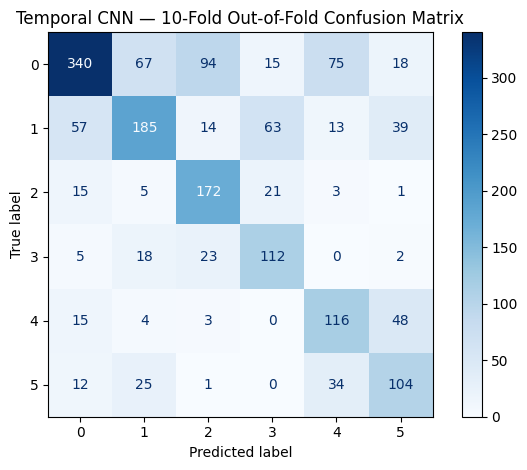

,precision,recall,f1-score,support
0,0.766,0.558,0.646,609.000
1,0.609,0.499,0.548,371.000
2,0.560,0.793,0.656,217.000
3,0.531,0.700,0.604,160.000
4,0.481,0.624,0.543,186.000
5,0.491,0.591,0.536,176.000
accuracy,0.599,0.599,0.599,0.599
macro avg,0.573,0.627,0.589,1719.000
weighted avg,0.625,0.599,0.600,1719.000


In [57]:
# Detect likely target/prediction columns
true_candidates = [
    c for c in pred.columns
    if c.lower() in ["y_true", "true", "true_label", "actual", "target", "ksws", "actual_encoded", "actual_label"]
]
pred_candidates = [
    c for c in pred.columns
    if c.lower() in ["y_pred", "pred", "predicted", "predicted_label", "prediction", "predicted_encoded"]
]

print("Possible true-label columns:", true_candidates)
print("Possible prediction columns:", pred_candidates)

# Fallback or manual override
TRUE_COL = true_candidates[0] if true_candidates else None
PRED_COL = pred_candidates[0] if pred_candidates else None

if TRUE_COL is None or PRED_COL is None:
    raise ValueError(
        "Set TRUE_COL and PRED_COL using the column names printed in Cell 54."
    )

y_true = pred[TRUE_COL].to_numpy()
y_pred = pred[PRED_COL].to_numpy()

labels = sorted(np.unique(np.concatenate([y_true, y_pred])))

cm = confusion_matrix(y_true, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Temporal CNN — 10-Fold Out-of-Fold Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS / "temporal_cnn_confusion_matrix.png",
            dpi=200, bbox_inches="tight")
plt.show()

report = classification_report(
    y_true, y_pred, labels=labels, output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report).T
report_df.to_csv(RESULTS / "temporal_cnn_classification_report.csv")

display(report_df.round(3))

56

In [58]:
from pathlib import Path
import pandas as pd

summary_path = RESULTS / "temporal_cnn_evaluation_summary.csv"
summary = pd.read_csv(summary_path) if summary_path.exists() else None

report_text = """
PEDIATRIC GAIT DIGITAL TWIN PROJECT
MODEL EVALUATION SUMMARY

Task:
Six-class supervised classification of KSwS using gait kinematic waveforms.

Evaluation:
10-fold held-out evaluation using patient-separated folds.
The temporal CNN used 12 complete waveform families, each with 51 points.
Total samples: 1,719.
Total patients: 356.

Pooled out-of-fold temporal CNN performance:
Accuracy: 0.6015
Balanced accuracy: 0.6301
Macro-F1: 0.5920

Patient-level bootstrap 95% confidence intervals:
Accuracy: 0.5699–0.6332
Balanced accuracy: 0.5979–0.6627
Macro-F1: 0.5581–0.6231

Baseline comparison on the same 12-family input:
Logistic regression accuracy: 0.5538
Logistic regression balanced accuracy: 0.5486
Logistic regression macro-F1: 0.5302

Interpretation:
The temporal CNN performed better than the logistic regression baseline
on the reported pooled out-of-fold metrics. This is a descriptive comparison;
no paired significance test has been established.

Data quality:
An audit found one repeated waveform-and-label pair (two rows) and no
identical waveform hashes associated with conflicting labels. This pair
should be documented and investigated rather than automatically removed.

Limitations:
This is a supervised KSwS classifier using kinematic waveforms. The results
alone do not establish a validated digital twin, clinical readiness, causal
interpretation, or a physics-informed model. Any further claims require
additional validation and clearly defined physical constraints.
""".strip()

report_path = RESULTS / "final_model_evaluation_report.txt"
report_path.write_text(report_text, encoding="utf-8")

important_files = [
    "temporal_cnn_10fold_oof_predictions.csv",
    "temporal_cnn_10fold_metrics.csv",
    "temporal_cnn_evaluation_summary.csv",
    "temporal_cnn_classification_report.csv",
    "temporal_cnn_confusion_matrix.png",
    "waveform_duplicate_audit.csv",
    "final_model_evaluation_report.txt",
]

print("FINAL FILE CHECK")
for filename in important_files:
    path = RESULTS / filename
    print(f"{'OK' if path.exists() else 'MISSING':7} {filename}")

print("\nReport saved to:", report_path)

FINAL FILE CHECK
OK      temporal_cnn_10fold_oof_predictions.csv
OK      temporal_cnn_10fold_metrics.csv
OK      temporal_cnn_evaluation_summary.csv
OK      temporal_cnn_classification_report.csv
OK      temporal_cnn_confusion_matrix.png
OK      waveform_duplicate_audit.csv
OK      final_model_evaluation_report.txt

Report saved to: /content/drive/MyDrive/Pediatric_GaitProject/results/final_model_evaluation_report.txt


57

In [59]:
from pathlib import Path

root = Path("/content/drive/MyDrive/Pediatric_GaitProject")

print("MODEL CHECKPOINTS")
for p in root.rglob("*.pth"):
    print(p)
for p in root.rglob("*.pt"):
    print(p)

print("\nSCALERS / PREPROCESSING")
for pattern in ["*scaler*", "*preprocess*", "*encoder*", "*checkpoint*"]:
    for p in root.rglob(pattern):
        if p.is_file():
            print(p)

print("\nRESULT FILES")
for p in (root / "results").glob("*"):
    print(p.name)

MODEL CHECKPOINTS
/content/drive/MyDrive/Pediatric_GaitProject/input/best_pediatric_pinn.pth
/content/drive/MyDrive/Pediatric_GaitProject/results/kwsw_temporal_cnn_pilot.pth

SCALERS / PREPROCESSING
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/checkpoint_weight_diagnostics.csv
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/checkpoint_weight_distributions.png
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/checkpoint_parameter_inventory.csv
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/checkpoint_provenance_audit.json
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/checkpoint_input_mapping_template.csv
/content/drive/MyDrive/Pediatric_GaitProject/review_outputs/checkpoint_output_mapping_template.csv

RESULT FILES
kwsw_overall_metrics.csv
kwsw_fold_metrics.csv
kwsw_oof_predictions.csv
kwsw_duplicate_sensitivity.csv
kwsw_duplicate_sensitivity_folds.csv
kwsw_model_comparison.csv
kwsw_model_comparison_predictions.csv
kwsw_mod

digital twin

In [60]:
# Interactive Pediatric Gait Twin — Colab
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output, HTML
from pathlib import Path

# Reuse the prepared project variables
assert "X" in globals() and "family_names" in globals(), (
    "Please run the earlier data preparation cells first."
)

n_samples = len(X)
family_names = list(family_names)

# Map class IDs back to their original labels if the encoder exists
def class_name(value):
    try:
        return str(label_encoder.inverse_transform([int(value)])[0])
    except Exception:
        return str(value)

sample_dropdown = widgets.IntSlider(
    value=0, min=0, max=n_samples-1, step=1,
    description="Sample:", continuous_update=False,
    layout=widgets.Layout(width="70%")
)

family_dropdown = widgets.Dropdown(
    options=family_names,
    value=family_names[0],
    description="Waveform:",
    layout=widgets.Layout(width="70%")
)

view_dropdown = widgets.ToggleButtons(
    options=[
        ("All 12 waveforms", "all"),
        ("Selected waveform", "one")
    ],
    value="all",
    description="View:"
)

output = widgets.Output()

def draw_twin(sample_idx, selected_family, view):
    with output:
        clear_output(wait=True)

        waveform = np.asarray(X[sample_idx])
        if waveform.shape != (len(family_names), 51):
            print("Unexpected sample shape:", waveform.shape)
            return

        # Dataset metadata and observed label
        meta = {}
        if "data" in globals() and sample_idx < len(data):
            row = data.iloc[sample_idx]
            for col in ["Patient ID", "Trial no.", "cycle", "side"]:
                if col in data.columns:
                    meta[col] = row[col]

        true_class = (
            class_name(y[sample_idx]) if "y" in globals() else "Unavailable"
        )

        display(HTML(
            "<h2>🧒 Pediatric Gait Twin</h2>"
            "<p>Dataset-linked gait profile • 51 points per waveform</p>"
        ))

        display(pd.DataFrame([{
            "Sample index": sample_idx,
            **meta,
            "Observed KSwS class": true_class,
            "Waveform families": len(family_names),
            "Points per family": 51
        }]).style.hide(axis="index"))

        if view == "all":
            fig, axes = plt.subplots(4, 3, figsize=(15, 11))
            axes = axes.ravel()

            for i, name in enumerate(family_names):
                axes[i].plot(np.arange(51), waveform[i], linewidth=2)
                axes[i].set_title(name)
                axes[i].set_xlabel("Waveform point")
                axes[i].set_ylabel("Recorded value")
                axes[i].grid(alpha=0.25)

            fig.suptitle(
                f"Gait waveform profile — sample {sample_idx}",
                fontsize=16
            )
            plt.tight_layout()
            plt.show()

        else:
            i = family_names.index(selected_family)
            plt.figure(figsize=(10, 4))
            plt.plot(np.arange(51), waveform[i], linewidth=2, marker=".")
            plt.title(f"{selected_family} — sample {sample_idx}")
            plt.xlabel("Waveform point")
            plt.ylabel("Recorded value")
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()

        print(
            "Prototype status: measured waveform twin displayed. "
            "No new AI prediction is generated by this visualization."
        )

def refresh(change=None):
    draw_twin(
        sample_dropdown.value,
        family_dropdown.value,
        view_dropdown.value
    )

sample_dropdown.observe(refresh, names="value")
family_dropdown.observe(refresh, names="value")
view_dropdown.observe(refresh, names="value")

display(widgets.VBox([
    sample_dropdown,
    view_dropdown,
    family_dropdown,
    output
]))

refresh()

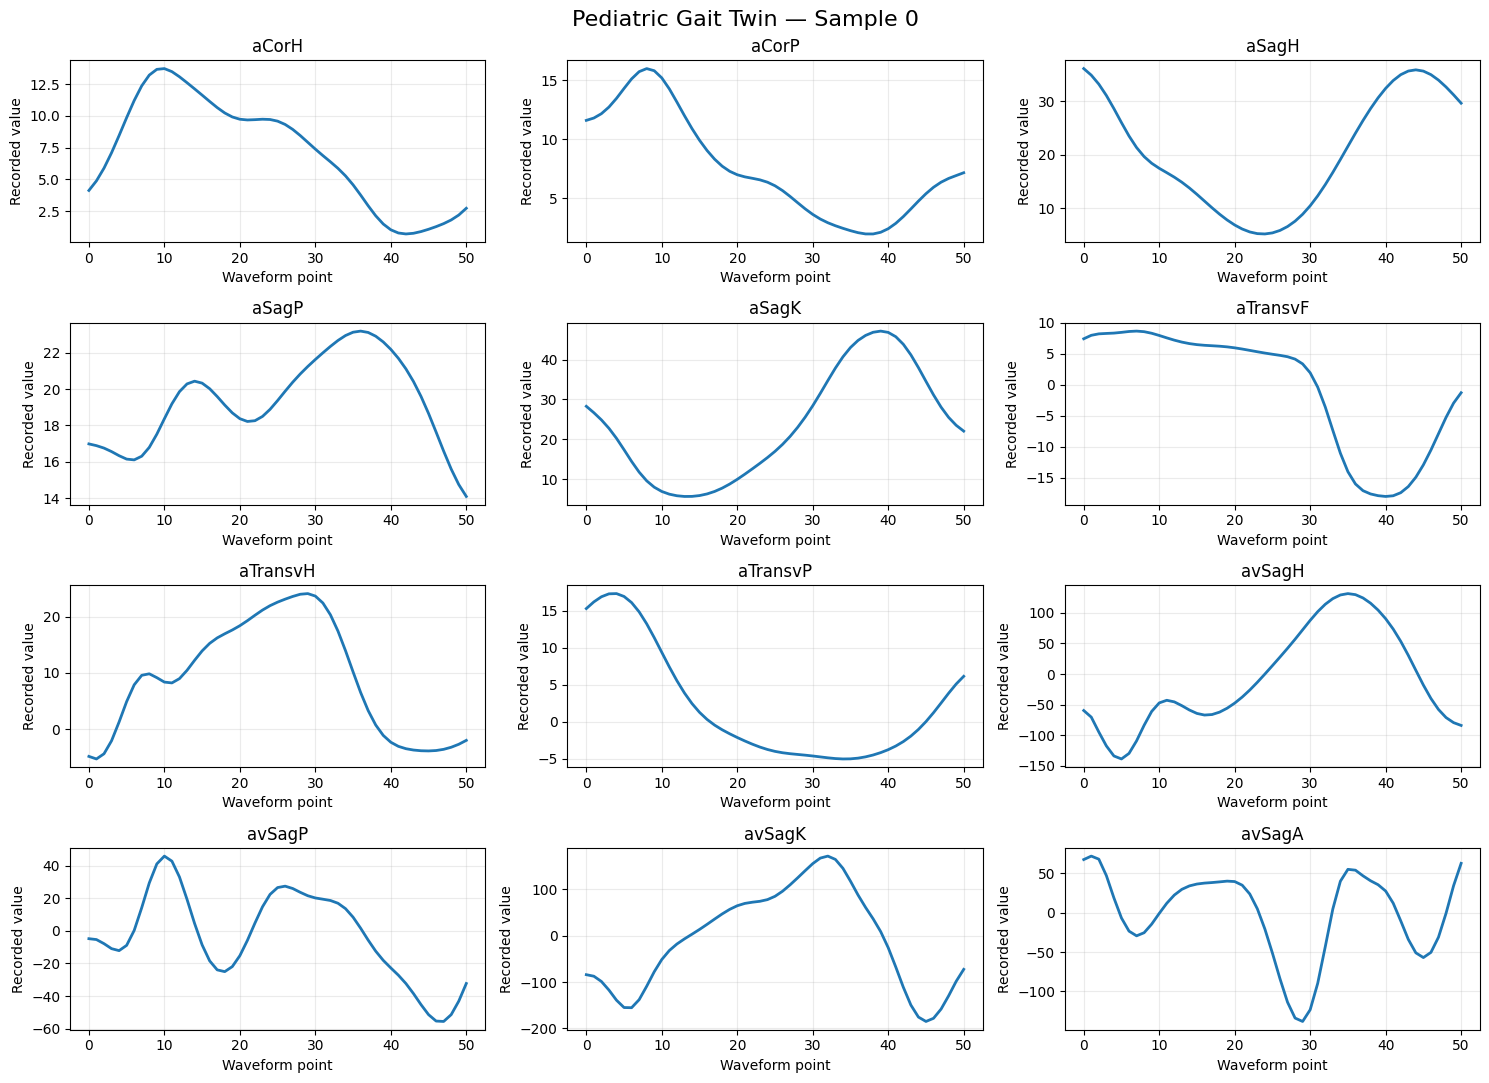

Saved gait twin snapshot: /content/drive/MyDrive/Pediatric_GaitProject/results/gait_twin_sample_0.png


In [61]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

results_dir = Path(
    "/content/drive/MyDrive/Pediatric_GaitProject/results"
)
results_dir.mkdir(parents=True, exist_ok=True)

idx = sample_dropdown.value
waveform = np.asarray(X[idx])

fig, axes = plt.subplots(4, 3, figsize=(15, 11))

for i, name in enumerate(family_names):
    ax = axes.ravel()[i]
    ax.plot(np.arange(51), waveform[i], linewidth=2)
    ax.set_title(name)
    ax.set_xlabel("Waveform point")
    ax.set_ylabel("Recorded value")
    ax.grid(alpha=0.25)

fig.suptitle(
    f"Pediatric Gait Twin — Sample {idx}",
    fontsize=16
)
plt.tight_layout()

save_path = results_dir / f"gait_twin_sample_{idx}.png"
fig.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved gait twin snapshot:", save_path)

57

In [62]:
import torch
from pathlib import Path

checkpoint_path = Path(
    "/content/drive/MyDrive/Pediatric_GaitProject/results/"
    "kwsw_temporal_cnn_pilot.pth"
)

obj = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(obj))

if isinstance(obj, dict):
    print("Top-level keys:", list(obj.keys())[:40])

    for k, v in obj.items():
        if isinstance(v, torch.Tensor):
            print(f"{k}: tensor {tuple(v.shape)}")
        elif isinstance(v, dict):
            print(f"{k}: dictionary with {len(v)} entries")
        elif isinstance(v, (str, int, float, bool, list, tuple)):
            print(f"{k}: {str(v)[:180]}")
else:
    print("Object details:", repr(obj)[:1000])

Checkpoint type: <class 'dict'>
Top-level keys: ['model_state_dict', 'n_channels', 'family_names', 'time_points', 'target', 'test_fold', 'channel_mean', 'channel_std', 'best_validation_loss']
model_state_dict: dictionary with 18 entries
n_channels: 11
family_names: ['aCorH', 'aCorP', 'aSagA', 'aSagH', 'aSagP', 'aTransvF', 'aTransvH', 'aTransvP', 'avSagA', 'avSagH', 'avSagP']
time_points: 51
target: KSwS
test_fold: 10
best_validation_loss: 1.1835666025569866


58

In [63]:
# Find common model state-dictionary formats
state = None

if isinstance(obj, dict):
    for key in ["model_state_dict", "state_dict", "model", "net"]:
        if key in obj and isinstance(obj[key], dict):
            state = obj[key]
            print("Possible state dictionary:", key)
            break

    if state is None and obj and all(
        isinstance(v, torch.Tensor) for v in obj.values()
    ):
        state = obj
        print("Checkpoint itself appears to be a state dictionary.")

if state is None:
    print(
        "Cannot safely infer the model architecture from this checkpoint. "
        "Use the existing dashboard without predictions for now."
    )
else:
    print("Number of saved parameter tensors:", len(state))
    for name, tensor in list(state.items())[:25]:
        print(name, tuple(tensor.shape))

Possible state dictionary: model_state_dict
Number of saved parameter tensors: 18
features.0.weight (32, 11, 5)
features.0.bias (32,)
features.1.weight (32,)
features.1.bias (32,)
features.1.running_mean (32,)
features.1.running_var (32,)
features.1.num_batches_tracked ()
features.3.weight (64, 32, 5)
features.3.bias (64,)
features.4.weight (64,)
features.4.bias (64,)
features.4.running_mean (64,)
features.4.running_var (64,)
features.4.num_batches_tracked ()
features.7.weight (64, 64, 3)
features.7.bias (64,)
classifier.2.weight (6, 64)
classifier.2.bias (6,)


In [64]:

import pandas as pd
from pathlib import Path

p = Path("/content/drive/MyDrive/Pediatric_GaitProject/results/temporal_cnn_10fold_oof_predictions.csv")
preds = pd.read_csv(p)

print("Prediction file shape:", preds.shape)
print("Columns:", preds.columns.tolist())
print(preds.head(3).to_string(index=False))

Prediction file shape: (1719, 13)
Columns: ['row_index', 'patient_id', 'fold', 'actual_encoded', 'predicted_encoded', 'actual_label', 'predicted_label', 'prob_class_0', 'prob_class_1', 'prob_class_2', 'prob_class_3', 'prob_class_4', 'prob_class_5']
 row_index  patient_id  fold  actual_encoded  predicted_encoded  actual_label  predicted_label  prob_class_0  prob_class_1  prob_class_2  prob_class_3  prob_class_4  prob_class_5
         0           1     1               4                  5             4                5      0.060958      0.101734      0.001745      0.007132      0.200986      0.627445
         1           1     1               3                  3             3                3      0.062160      0.070685      0.319212      0.542191      0.003859      0.001893
         2           1     1               1                  5             1                5      0.174476      0.265925      0.012578      0.033800      0.126865      0.386356


In [65]:

import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
preds = pd.read_csv(PROJECT / "results/temporal_cnn_10fold_oof_predictions.csv")

# Verify predictions align with the dataset row order
assert len(preds) == len(data), f"Row count mismatch: {len(preds)} vs {len(data)}"
assert preds["row_index"].tolist() == list(range(len(data))), "Row indices are not in expected order"

# Verify actual labels match the prepared target
assert (preds["actual_encoded"].to_numpy() == y).all(), \
    "Labels do not match; do not connect predictions to the dashboard."

print("Row alignment verified.")
print("Rows:", len(preds))
print("Stored OOF accuracy:", round((preds["actual_encoded"] == preds["predicted_encoded"]).mean(), 4))
print("Ready to connect stored predictions to the dashboard.")

Row alignment verified.
Rows: 1719
Stored OOF accuracy: 0.5986
Ready to connect stored predictions to the dashboard.


In [66]:

import numpy as np
import pandas as pd
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Pediatric_GaitProject")
preds = pd.read_csv(PROJECT / "results/temporal_cnn_10fold_oof_predictions.csv")

# One prediction record per existing dataset row
oof_predictions = preds.set_index("row_index").sort_index()

# Confidence = probability assigned to the predicted class
prob_cols = [f"prob_class_{i}" for i in range(6)]
probabilities = oof_predictions[prob_cols].to_numpy()
predicted_classes = oof_predictions["predicted_encoded"].to_numpy()

oof_confidence = probabilities[
    np.arange(len(probabilities)), predicted_classes
]

print("Stored OOF predictions ready:", len(oof_predictions))
print("Example row 0:")
print("Actual class:", oof_predictions.loc[0, "actual_label"])
print("Predicted class:", oof_predictions.loc[0, "predicted_label"])
print("Predicted-class probability:", f"{oof_confidence[0]:.1%}")

# Save a reusable copy for the prototype
oof_predictions["predicted_class_probability"] = oof_confidence
oof_predictions.to_csv(
    PROJECT / "results/dashboard_oof_predictions.csv",
    index_label="row_index"
)
print("Saved: results/dashboard_oof_predictions.csv")

Stored OOF predictions ready: 1719
Example row 0:
Actual class: 4
Predicted class: 5
Predicted-class probability: 62.7%
Saved: results/dashboard_oof_predictions.csv


In [67]:
# Load once, before defining your dashboard update function
oof_predictions = pd.read_csv(
    "/content/drive/MyDrive/Pediatric_GaitProject/results/dashboard_oof_predictions.csv"
).set_index("row_index")

# Add inside your sample-update function, after obtaining the selected index `idx`
result = oof_predictions.loc[idx]

print(f"Observed KSwS class: {result['actual_label']}")
print(f"Stored OOF predicted class: {result['predicted_label']}")
print(
    "Predicted-class probability: "
    f"{result['predicted_class_probability']:.1%}"
)
print("Note: Stored out-of-fold result, not a live prediction.")

Observed KSwS class: 4.0
Stored OOF predicted class: 5.0
Predicted-class probability: 62.7%
Note: Stored out-of-fold result, not a live prediction.


framework